# Digo - NLP Disaster Tweet Classification

**Project 7 | Data Science & AI Internship**

**Prepared by:** Bhawna Chouhan

---

## 1. Project Introduction

### 1.1 Problem statement

During an emergency, Twitter/X is often faster than official channels. Disaster-relief
agencies and news desks would like to monitor it automatically. The difficulty is that
**the vocabulary of disaster is also the vocabulary of everyday exaggeration**:

| Tweet | Contains | Actually a disaster? |
|---|---|---|
| "Forest fire near La Ronge Sask. Canada" | *fire* | **Yes** |
| "that exam absolutely destroyed me" | *destroyed* | **No** |
| "My new song is FIRE 🔥" | *fire* | **No** |
| "13,000 people receive wildfires evacuation orders" | *wildfires* | **Yes** |

A system that simply looks for the word *fire* will flag all four. The real task is
therefore **contextual understanding**, not keyword matching. This is what makes the
problem a genuine Natural Language Processing problem rather than a lookup table.

### 1.2 Business and emergency-response relevance

The two kinds of mistake are *not* equally costly, and they trade off against each other:

- A **false positive** (crying wolf) wastes responder attention. Too many and operators
  start ignoring the system entirely - the classic alarm-fatigue failure.
- A **false negative** (a real emergency missed) is the more dangerous error for a
  monitoring tool, because the event passes silently.

Because of this, we do **not** optimise accuracy alone. We report precision, recall and
F1 with respect to the disaster class throughout, and we look at the confusion matrix
rather than a single headline number.

### 1.3 Objectives

1. Audit the supplied dataset honestly and document every data-quality issue found.
2. Explore the data and establish what actually separates the two classes.
3. Build a reusable, tested text-preprocessing pipeline that **preserves meaning**
   (negation, numbers, hashtag words) instead of stripping everything.
4. Engineer and evaluate numeric features, including genuine sentiment analysis.
5. Compare several classical models fairly on an untouched test set.
6. Investigate and actually fine-tune DistilBERT as an advanced comparison.
7. Select a final model on evidence, save it, and prove it reloads and predicts.
8. Ship a Streamlit application that uses the saved model.

### 1.4 The classification target

| Label | Meaning | Count in supplied data |
|---|---|---|
| `0` | Non-disaster - figurative, joking, or unrelated use of disaster words | 4,342 |
| `1` | Disaster-related - refers to a genuine disaster or emergency | 3,271 |

(These counts are re-derived from the actual file in Section 3 - they are not assumed.)

### 1.5 Planned workflow

```
Audit -> EDA -> Preprocessing -> Keyword analysis -> Feature engineering
      -> Sentiment -> Vectorization -> Leakage-safe split -> Model comparison
      -> DistilBERT -> Evaluation & error analysis -> Save model -> Streamlit app
```

### 1.6 Tools used

`pandas` / `numpy` (data), `matplotlib` / `seaborn` / `wordcloud` (visualisation),
`scikit-learn` (vectorizers, models, metrics), `vaderSentiment` + `TextBlob`
(sentiment), `gensim` (Word2Vec), `transformers` + `torch` (DistilBERT),
`joblib` (serialization), `streamlit` (application).

### 1.7 A note on the project brief

> The written project statement describes **"10,000 hand-classified tweets"**.
> The dataset actually supplied (`data/twitter_disaster.csv`) contains **7,613 rows**.
> **This project uses the supplied 7,613 rows and nothing else.** No rows are
> synthesised, duplicated or imported from elsewhere to reach 10,000. Section 3
> verifies the true size directly from the file.

---

## 2. Import Libraries and Configuration

We import everything once, fix the random seed for reproducibility, and configure
plotting defaults so every chart in the notebook is readable and consistent.

The project's own logic lives in the `src/` package and is **imported, not
re-typed**. The exact same `clean_text` function used here is used by the Streamlit
app, which is what guarantees that training and inference cannot drift apart.

In [1]:
# --- make the project package importable from the notebooks/ folder ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo


In [2]:
# --- standard library ---
import json
import re
import time
import warnings
from collections import Counter

# --- third party ---
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from wordcloud import WordCloud

# --- project modules (single source of truth) ---
from src import config
from src.config import (
    FIGURES_DIR,
    LABEL_NAMES,
    RANDOM_SEED,
    RAW_DATA_FILE,
    TEST_SIZE,
    CV_FOLDS,
)
from src.preprocessing import (
    clean_text,
    decode_keyword,
    tokenize,
    NEGATION_WORDS,
    STOPWORDS,
)
from src.features import add_text_features, NUMERIC_FEATURE_NAMES
from src.sentiment import add_sentiment_features, analyse_sentiment, SENTIMENT_FEATURE_NAMES
from src import evaluation as ev

config.ensure_directories()
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"pandas       {pd.__version__}")
print(f"numpy        {np.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"Python       {sys.version.split()[0]}")

pandas       2.3.3
numpy        2.5.4
scikit-learn 1.9.1
Python       3.12.7


In [3]:
# --- reproducibility ---
np.random.seed(RANDOM_SEED)

# --- plotting defaults ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["savefig.bbox"] = "tight"

# Consistent colours for the two classes everywhere in the notebook.
CLASS_PALETTE = {0: "#4C72B0", 1: "#C44E52"}
CLASS_COLOURS = [CLASS_PALETTE[0], CLASS_PALETTE[1]]

# --- pandas display ---
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

print(f"Random seed fixed at {RANDOM_SEED}")
print(f"Test split          {TEST_SIZE:.0%}")
print(f"Cross-validation    {CV_FOLDS}-fold stratified")
print(f"Figures will be saved to: {FIGURES_DIR.relative_to(PROJECT_ROOT)}")

Random seed fixed at 42
Test split          20%
Cross-validation    5-fold stratified
Figures will be saved to: reports\figures


---

## 3. Load and Audit the Data

Before any modelling we establish **what we actually have**. Every number below is
computed from the file itself. Nothing is copied from the project brief.

In [4]:
df = pd.read_csv(RAW_DATA_FILE)

print(f"File       : {RAW_DATA_FILE.relative_to(PROJECT_ROOT)}")
print(f"Shape      : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Columns    : {list(df.columns)}")
print(f"Memory     : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
df.head()

File       : data\twitter_disaster.csv
Shape      : 7,613 rows x 5 columns
Columns    : ['id', 'keyword', 'location', 'text', 'target']
Memory     : 2.02 MB


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter i...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5079 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


### 3.1 Dataset size: the brief vs. the file

The project statement says 10,000 tweets. Let us check what the file really contains.

In [6]:
STATED_IN_BRIEF = 10_000
actual_rows = len(df)

print(f"Rows stated in the project brief : {STATED_IN_BRIEF:,}")
print(f"Rows actually in the supplied CSV: {actual_rows:,}")
print(f"Difference                       : {STATED_IN_BRIEF - actual_rows:,}")
print()
print("DECISION: this project uses the supplied file exactly as given.")
print("No rows are generated, duplicated or imported to reach 10,000.")
print(f"Every statistic, split and metric in this notebook is based on {actual_rows:,} real rows.")

Rows stated in the project brief : 10,000
Rows actually in the supplied CSV: 7,613
Difference                       : 2,387

DECISION: this project uses the supplied file exactly as given.
No rows are generated, duplicated or imported to reach 10,000.
Every statistic, split and metric in this notebook is based on 7,613 real rows.


> **Documented discrepancy.** The supplied dataset is the well-known Kaggle
> *"Natural Language Processing with Disaster Tweets"* training split, which contains
> 7,613 labelled rows. The brief's "10,000" does not match it. Mentor guidance was
> explicit that the **actual supplied dataset** must be used, so that is what we do.
> Inventing 2,387 synthetic tweets would corrupt every metric in the project.

### 3.2 Missing values

In [7]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().sum() / len(df) * 100).round(2),
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(),
})
missing

,missing_count,missing_pct,dtype,unique_values
id,0,0.00,int64,7613
keyword,61,0.80,object,221
location,2534,33.29,object,3293
text,0,0.00,object,7503
target,0,0.00,int64,2


**What this means for each column:**

- **`id`** - a row identifier only. It carries no information about whether a tweet
  describes a disaster, so it must never be used as a feature.
- **`keyword`** - 61 missing (0.8%). Nearly complete, and it is a curated disaster term,
  so it is worth investigating as a feature.
- **`location`** - 2,534 missing (33.3%). This is free text typed by users, not a
  validated field; Section 7 examines whether it is usable at all.
- **`text`** - the tweet itself. This is the primary input.
- **`target`** - the label we predict.

### 3.3 Duplicates and label conflicts

Duplicates matter here for a specific technical reason: if the *same tweet* appears in
both the training and the test set, the model can memorise it and the test score becomes
dishonestly high. This is a form of **data leakage**, so we must quantify it now.

In [8]:
dup_ids = df["id"].duplicated().sum()
dup_rows = df.duplicated().sum()
dup_text = df["text"].duplicated().sum()

# Tweets whose identical text was given BOTH labels by the human annotators.
labels_per_text = df.groupby("text")["target"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1]
rows_affected = df[df["text"].isin(conflicting_texts.index)]

print(f"Duplicate 'id' values            : {dup_ids}")
print(f"Fully duplicated rows            : {dup_rows}")
print(f"Duplicated 'text' values         : {dup_text}")
print(f"Distinct texts with BOTH labels  : {len(conflicting_texts)}")
print(f"Rows involved in those conflicts : {len(rows_affected)}")

Duplicate 'id' values            : 0
Fully duplicated rows            : 0
Duplicated 'text' values         : 110
Distinct texts with BOTH labels  : 18
Rows involved in those conflicts : 55


In [9]:
# Look at the contradictions directly - they tell us something real about the task.
(rows_affected
 .sort_values("text")[["id", "text", "target"]]
 .head(8))

,id,text,target
4290,6094,#Allah describes piling up #wealth thinking it would last #forever as the description of the people of #He...,0
4299,6105,#Allah describes piling up #wealth thinking it would last #forever as the description of the people of #He...,0
4312,6123,#Allah describes piling up #wealth thinking it would last #forever as the description of the people of #He...,1
4244,6031,#foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #human...,0
4221,5996,#foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #human...,1
4239,6023,#foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #human...,1
2832,4076,.POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; ...,0
2831,4072,.POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; ...,1


**Observation.** A small number of identical tweets were hand-labelled *both* 0 and 1.
This is not a bug in our code - it is genuine **annotator disagreement**, and it is
informative: it shows that even humans cannot always agree on whether an ambiguous tweet
describes a real disaster. This sets a realistic ceiling on achievable accuracy; a model
reporting 100% would be a sign of leakage, not skill.

These rows are handled explicitly in Section 10 (before the train/test split), not
silently dropped here.

### 3.4 Text quality and target validity

In [10]:
empty_text = (df["text"].fillna("").str.strip() == "").sum()
null_text = df["text"].isna().sum()
invalid_targets = df.loc[~df["target"].isin([0, 1]), "target"].unique()

print(f"Null 'text' values        : {null_text}")
print(f"Empty / whitespace 'text' : {empty_text}")
print(f"'target' dtype            : {df['target'].dtype}")
print(f"'target' unique values    : {sorted(df['target'].unique())}")
print(f"Invalid target values     : {list(invalid_targets) if len(invalid_targets) else 'none'}")
print()

# Does the cleaning pipeline ever destroy a tweet completely?
cleaned_preview = df["text"].apply(clean_text)
print(f"Tweets that become empty after cleaning: {(cleaned_preview.str.strip() == '').sum()}")

Null 'text' values        : 0
Empty / whitespace 'text' : 0
'target' dtype            : int64
'target' unique values    : [np.int64(0), np.int64(1)]
Invalid target values     : none



Tweets that become empty after cleaning: 0


In [11]:
target_counts = df["target"].value_counts().sort_index()
target_pct = df["target"].value_counts(normalize=True).sort_index() * 100

summary = pd.DataFrame({
    "label": [LABEL_NAMES[0], LABEL_NAMES[1]],
    "count": target_counts.values,
    "percentage": target_pct.round(2).values,
}, index=target_counts.index)
summary.index.name = "target"
print(summary.to_string())
print()
print(f"Imbalance ratio (majority:minority) = {target_counts.max() / target_counts.min():.2f} : 1")
print(f"Majority-class baseline accuracy    = {target_pct.max():.2f}%")
print()
print("A model that always predicts 'Non-disaster' would score "
      f"{target_pct.max():.1f}% accuracy while finding ZERO real disasters.")
print("This is exactly why accuracy alone is not an acceptable metric here.")

                   label  count  percentage
target                                     
0           Non-disaster   4342       57.03
1       Disaster-related   3271       42.97

Imbalance ratio (majority:minority) = 1.33 : 1
Majority-class baseline accuracy    = 57.03%

A model that always predicts 'Non-disaster' would score 57.0% accuracy while finding ZERO real disasters.
This is exactly why accuracy alone is not an acceptable metric here.


### 3.5 Audit summary

| Finding | Value | Why it matters |
|---|---|---|
| Rows x columns | **7,613 x 5** | The brief's 10,000 is wrong; we use the real file |
| Missing `keyword` | **61 (0.8%)** | Almost complete - worth testing as a feature |
| Missing `location` | **2,534 (33.3%)** | Unreliable free text - investigated in Section 7 |
| Duplicate `id` | **0** | Row identity is clean |
| Duplicate `text` | **110** | Must be removed *before* splitting to avoid leakage |
| Contradictory labels | **18 texts** | Human annotators disagree - a realistic accuracy ceiling |
| Empty / null `text` | **0** | No rows need dropping for missing input |
| Class balance | **57.0% / 43.0%** | Mild imbalance - accuracy alone is misleading |

The data is clean enough to model, with two issues to handle deliberately:
the **duplicate/contradictory rows** (Section 10) and the **class imbalance**
(addressed by choosing F1-based metrics rather than accuracy).

---

## 4. Exploratory Data Analysis

The goal of this section is not to produce as many charts as possible, but to answer
specific questions: *How balanced are the classes? Does tweet length separate them?
Which words and keywords matter? Do structural features (hashtags, URLs, mentions)
differ between classes?*

Each chart is followed by a short interpretation that states **what it shows** and,
just as importantly, **what it does not prove**.

### 4.1 Class distribution

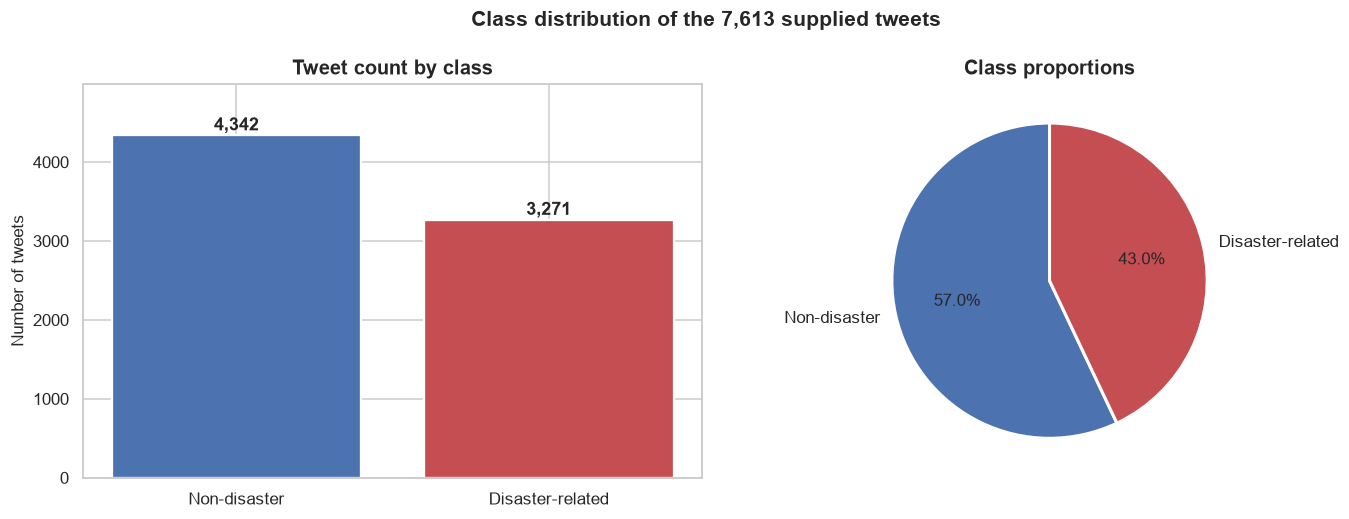

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

counts = df["target"].value_counts().sort_index()
bars = axes[0].bar([LABEL_NAMES[0], LABEL_NAMES[1]], counts.values,
                   color=CLASS_COLOURS, edgecolor="white", linewidth=1.5)
axes[0].set_title("Tweet count by class")
axes[0].set_ylabel("Number of tweets")
axes[0].set_ylim(0, counts.max() * 1.15)
for bar, value in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 60,
                 f"{value:,}", ha="center", fontweight="bold")

axes[1].pie(counts.values, labels=[LABEL_NAMES[0], LABEL_NAMES[1]],
            colors=CLASS_COLOURS, autopct="%1.1f%%", startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 2},
            textprops={"fontsize": 11})
axes[1].set_title("Class proportions")

fig.suptitle("Class distribution of the 7,613 supplied tweets", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=150)
plt.show()

**Interpretation.** The dataset is *mildly* imbalanced at roughly 57% / 43%. This is
not severe enough to require resampling (SMOTE or class weighting), but it is enough
that **accuracy is a misleading headline metric**: always predicting "Non-disaster"
scores 57% while being operationally useless.

**What this does not show:** nothing about how *separable* the classes are. A balanced
dataset can still be impossible to classify.

### 4.2 Missing values

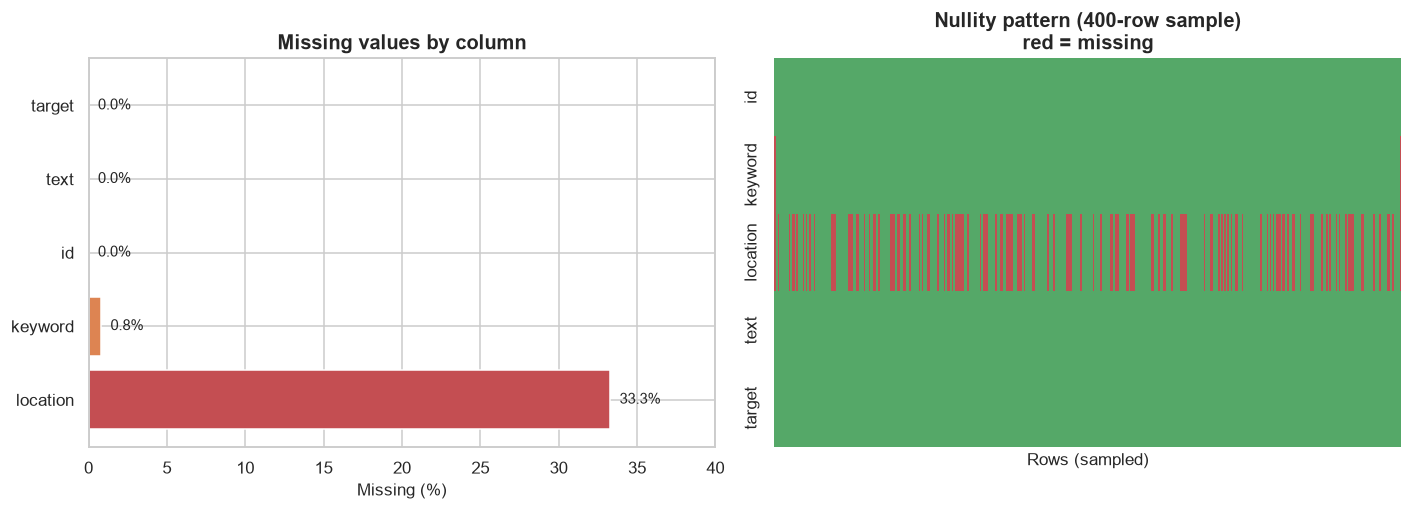

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

missing_pct = (df.isna().sum() / len(df) * 100).sort_values(ascending=False)
colours = ["#C44E52" if v > 20 else "#DD8452" if v > 0 else "#55A868" for v in missing_pct.values]
bars = axes[0].barh(missing_pct.index, missing_pct.values, color=colours, edgecolor="white")
axes[0].set_title("Missing values by column")
axes[0].set_xlabel("Missing (%)")
axes[0].set_xlim(0, 40)
for bar, value in zip(bars, missing_pct.values):
    axes[0].text(value + 0.6, bar.get_y() + bar.get_height() / 2,
                 f"{value:.1f}%", va="center", fontsize=10)

# A sampled nullity matrix: white stripes = missing. Sampling keeps it readable.
sample = df.sample(400, random_state=RANDOM_SEED).sort_index()
sns.heatmap(sample.isna().T, cbar=False, cmap=["#55A868", "#C44E52"],
            yticklabels=sample.columns, xticklabels=False, ax=axes[1])
axes[1].set_title("Nullity pattern (400-row sample)\nred = missing")
axes[1].set_xlabel("Rows (sampled)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_missing_values.png", dpi=150)
plt.show()

In [14]:
# Is 'location' missing at random, or does missingness itself carry signal?
loc_missing_by_class = df.groupby("target")["location"].apply(lambda s: s.isna().mean() * 100)
kw_missing_by_class = df.groupby("target")["keyword"].apply(lambda s: s.isna().mean() * 100)

print("Missing 'location' by class:")
for label, pct in loc_missing_by_class.items():
    print(f"   {LABEL_NAMES[label]:18s} {pct:.2f}%")
print("\nMissing 'keyword' by class:")
for label, pct in kw_missing_by_class.items():
    print(f"   {LABEL_NAMES[label]:18s} {pct:.2f}%")
print(f"\nDifference in location-missingness between classes: "
      f"{abs(loc_missing_by_class.diff().iloc[-1]):.2f} percentage points")

Missing 'location' by class:
   Non-disaster       33.58%
   Disaster-related   32.90%

Missing 'keyword' by class:
   Non-disaster       0.44%
   Disaster-related   1.28%

Difference in location-missingness between classes: 0.68 percentage points


**Interpretation.** `location` is missing for a third of all rows, and the missing rate
is close between the two classes - so "did the user fill in a location?" is not a strong
clue by itself. `keyword` is almost complete.

**What this does not prove:** that `location` is useless. It tests only *missingness*,
not the content. Section 7 examines whether the location text itself helps.

### 4.3 Tweet length

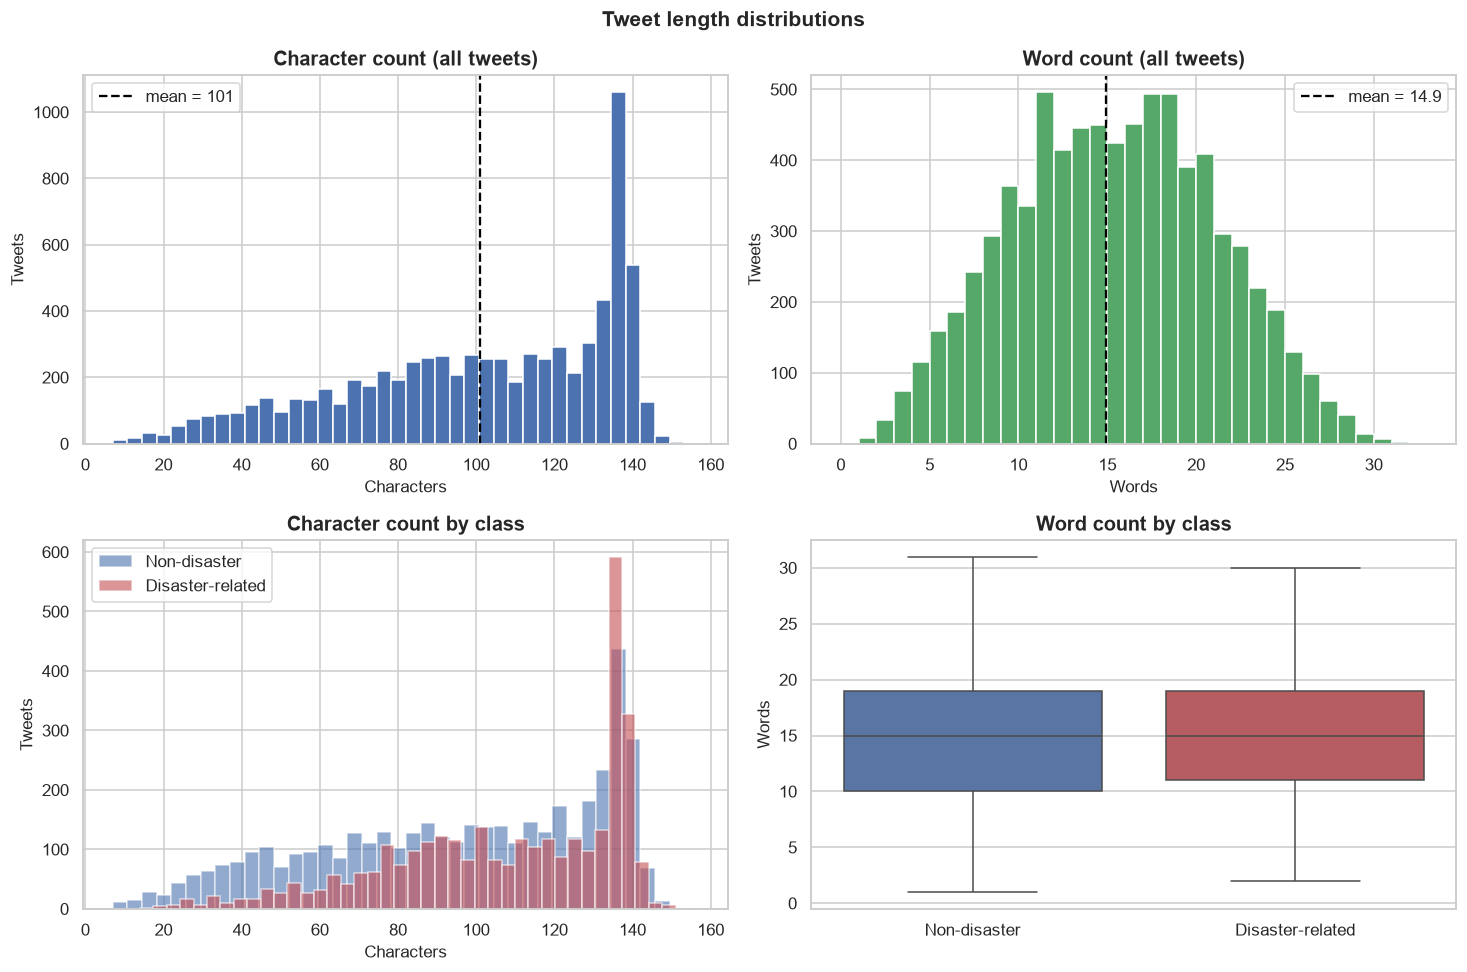

In [15]:
df["char_count"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9))

axes[0, 0].hist(df["char_count"], bins=40, color="#4C72B0", edgecolor="white")
axes[0, 0].axvline(df["char_count"].mean(), color="black", linestyle="--",
                   label=f"mean = {df['char_count'].mean():.0f}")
axes[0, 0].set_title("Character count (all tweets)")
axes[0, 0].set_xlabel("Characters"); axes[0, 0].set_ylabel("Tweets"); axes[0, 0].legend()

axes[0, 1].hist(df["word_count"], bins=range(0, 34), color="#55A868", edgecolor="white")
axes[0, 1].axvline(df["word_count"].mean(), color="black", linestyle="--",
                   label=f"mean = {df['word_count'].mean():.1f}")
axes[0, 1].set_title("Word count (all tweets)")
axes[0, 1].set_xlabel("Words"); axes[0, 1].set_ylabel("Tweets"); axes[0, 1].legend()

for label in (0, 1):
    subset = df[df["target"] == label]
    axes[1, 0].hist(subset["char_count"], bins=40, alpha=0.6,
                    label=LABEL_NAMES[label], color=CLASS_PALETTE[label], edgecolor="white")
axes[1, 0].set_title("Character count by class")
axes[1, 0].set_xlabel("Characters"); axes[1, 0].set_ylabel("Tweets"); axes[1, 0].legend()

sns.boxplot(data=df, x="target", y="word_count", hue="target",
            palette=CLASS_PALETTE, legend=False, ax=axes[1, 1])
axes[1, 1].set_xticks([0, 1]); axes[1, 1].set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])
axes[1, 1].set_title("Word count by class")
axes[1, 1].set_xlabel(""); axes[1, 1].set_ylabel("Words")

fig.suptitle("Tweet length distributions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_tweet_length.png", dpi=150)
plt.show()

In [16]:
length_stats = df.groupby("target")[["char_count", "word_count"]].agg(["mean", "median", "std", "min", "max"])
length_stats.index = [LABEL_NAMES[0], LABEL_NAMES[1]]
print(length_stats.round(2).to_string())

from scipy import stats as scipy_stats
group0 = df.loc[df["target"] == 0, "char_count"]
group1 = df.loc[df["target"] == 1, "char_count"]
t_stat, p_value = scipy_stats.ttest_ind(group0, group1, equal_var=False)
pooled_sd = np.sqrt((group0.var() + group1.var()) / 2)
cohens_d = (group1.mean() - group0.mean()) / pooled_sd

print(f"\nCharacter count, disaster vs non-disaster:")
print(f"   difference in means : {group1.mean() - group0.mean():+.1f} characters")
print(f"   Welch t-test p-value: {p_value:.3e}")
print(f"   Cohen's d           : {cohens_d:.3f}  (0.2 = small, 0.5 = medium, 0.8 = large)")

                 char_count                        word_count                     
                       mean median    std min  max       mean median   std min max
Non-disaster          95.68  101.0  35.88   7  157      14.70   15.0  6.16   1  31
Disaster-related     108.10  115.0  29.32  14  151      15.17   15.0  5.10   2  30

Character count, disaster vs non-disaster:
   difference in means : +12.4 characters
   Welch t-test p-value: 8.218e-61
   Cohen's d           : 0.379  (0.2 = small, 0.5 = medium, 0.8 = large)


**Interpretation.** Disaster tweets are measurably *longer* on average, and with 7,613
rows that difference is statistically significant. But look at **Cohen's d**: the effect
size is small. The two distributions overlap heavily.

**What this does not prove:** that length is a useful classifier. A statistically
significant difference with a small effect size means length is a *weak* signal - it may
contribute a little inside a larger model, but on its own it would be close to useless.
This is exactly the distinction between "significant" and "important", and it is why we
keep length as *one* engineered feature rather than treating it as a discovery.

### 4.4 Word frequency - raw vs. cleaned

A frequency count on **raw** text is dominated by grammar words (*the*, *a*, *in*) and
HTML junk (`&amp;`). Comparing raw against cleaned shows exactly what preprocessing buys us.

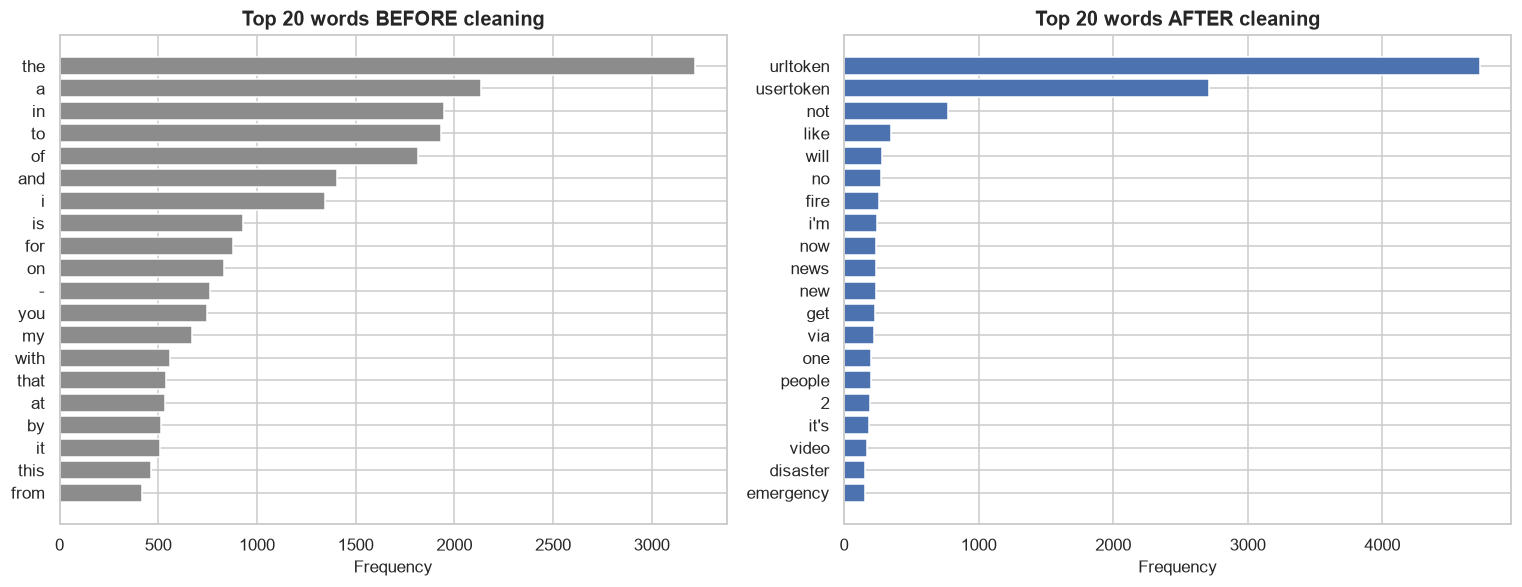

Distinct tokens before cleaning: 27,933
Distinct tokens after cleaning : 14,656
Vocabulary reduction           : 47.5%


In [17]:
raw_tokens = Counter(w.lower() for tweet in df["text"] for w in tweet.split())
df["clean_text"] = df["text"].apply(clean_text)
clean_tokens = Counter(w for tweet in df["clean_text"] for w in tweet.split())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, counter, title, colour in [
    (axes[0], raw_tokens, "Top 20 words BEFORE cleaning", "#8C8C8C"),
    (axes[1], clean_tokens, "Top 20 words AFTER cleaning", "#4C72B0"),
]:
    words, values = zip(*counter.most_common(20))
    ax.barh(list(words)[::-1], list(values)[::-1], color=colour, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_word_frequency_raw_vs_clean.png", dpi=150)
plt.show()

print(f"Distinct tokens before cleaning: {len(raw_tokens):,}")
print(f"Distinct tokens after cleaning : {len(clean_tokens):,}")
print(f"Vocabulary reduction           : {(1 - len(clean_tokens)/len(raw_tokens))*100:.1f}%")

**Interpretation.** Before cleaning, the top of the list is entirely function words plus
`&amp;` and bare URL fragments - none of which distinguish a disaster from a joke. After
cleaning, genuinely topical terms surface. The vocabulary also shrinks substantially,
which makes the TF-IDF matrix smaller and the model faster.

**What this does not prove:** that the frequent cleaned words are *predictive*. Frequency
is not discrimination - a word can be common in both classes. Section 6 tests that directly.

### 4.5 Most frequent words per class

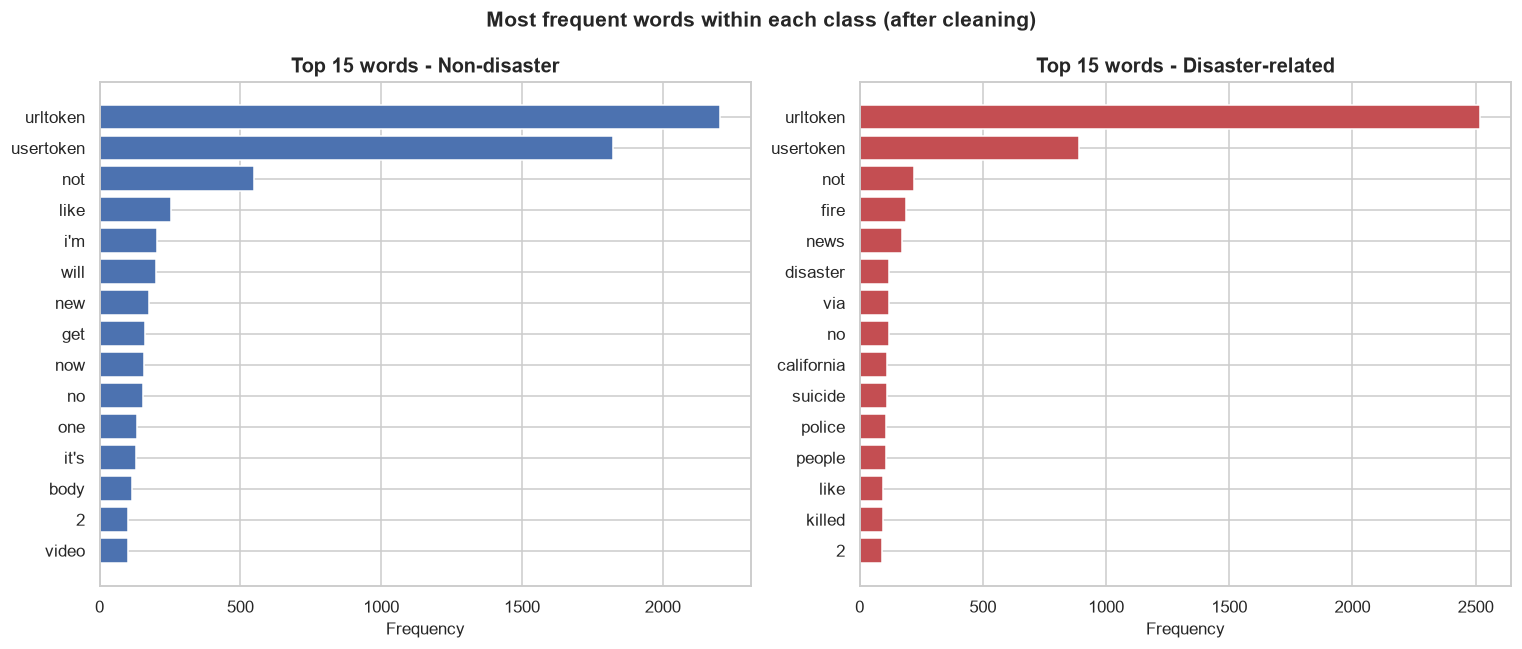

In [18]:
tokens_by_class = {
    label: Counter(w for tweet in df.loc[df["target"] == label, "clean_text"] for w in tweet.split())
    for label in (0, 1)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, label in zip(axes, (0, 1)):
    words, values = zip(*tokens_by_class[label].most_common(15))
    ax.barh(list(words)[::-1], list(values)[::-1],
            color=CLASS_PALETTE[label], edgecolor="white")
    ax.set_title(f"Top 15 words - {LABEL_NAMES[label]}")
    ax.set_xlabel("Frequency")

fig.suptitle("Most frequent words within each class (after cleaning)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_top_words_by_class.png", dpi=150)
plt.show()

**Interpretation.** The disaster class is dominated by event nouns (*fire*, *flood*,
*bomb*, *killed*, *disaster*) and news vocabulary. The non-disaster class contains far
more conversational and first-person language.

Note that `urltoken` is prominent in the disaster class - real disaster tweets frequently
link to a news article, whereas casual tweets more often do not. That is a *structural*
signal, captured numerically by the `url_count` feature in Section 7.

### 4.6 Word clouds

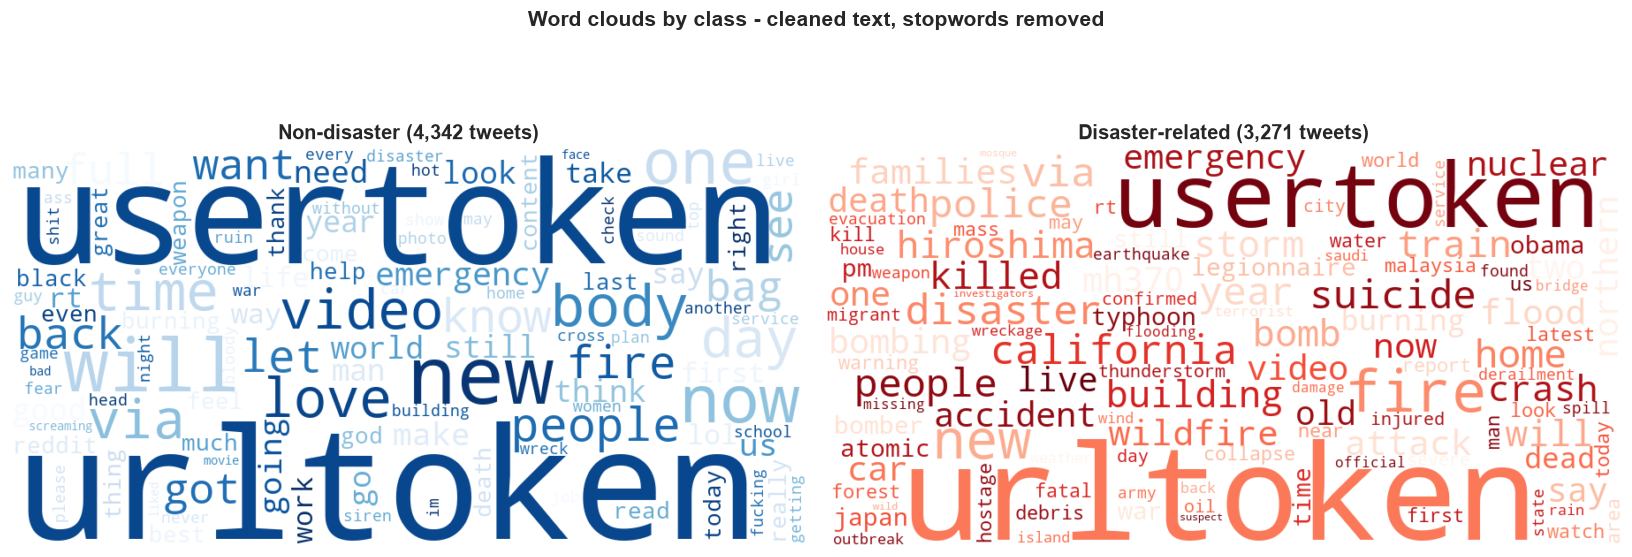

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, label in zip(axes, (0, 1)):
    text_blob = " ".join(df.loc[df["target"] == label, "clean_text"])
    cloud = WordCloud(width=900, height=450, background_color="white",
                      colormap="Blues_r" if label == 0 else "Reds_r",
                      max_words=110, random_state=RANDOM_SEED,
                      collocations=False).generate(text_blob)
    ax.imshow(cloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{LABEL_NAMES[label]} ({(df['target'] == label).sum():,} tweets)",
                 fontsize=13, fontweight="bold")

fig.suptitle("Word clouds by class - cleaned text, stopwords removed",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_wordclouds.png", dpi=150)
plt.show()

**Interpretation.** The clouds reinforce Section 4.5 visually and are useful for a
presentation audience.

**What this does not prove:** word clouds size words by raw frequency only. They cannot
show whether a word is *discriminative*, and they hide the counts. They are an
illustration, never evidence - the quantitative version is in Section 6.

### 4.7 Keyword analysis

In [20]:
df["keyword_clean"] = df["keyword"].apply(decode_keyword)
has_keyword = df[df["keyword_clean"] != ""].copy()

print(f"Rows with a keyword : {len(has_keyword):,} ({len(has_keyword)/len(df)*100:.1f}%)")
print(f"Distinct keywords   : {has_keyword['keyword_clean'].nunique()}")
print(f"Example raw -> decoded: 'body%20bags' -> '{decode_keyword('body%20bags')}'")

top_keywords = has_keyword["keyword_clean"].value_counts().head(10)
print(f"\nTop 10 keywords by frequency:")
for rank, (kw, count) in enumerate(top_keywords.items(), 1):
    print(f"  {rank:2d}. {kw:<18s} {count:3d}")

Rows with a keyword : 7,552 (99.2%)
Distinct keywords   : 221
Example raw -> decoded: 'body%20bags' -> 'body bags'

Top 10 keywords by frequency:
   1. fatalities          45
   2. deluge              42
   3. armageddon          42
   4. damage              41
   5. body bags           41
   6. harm                41
   7. sinking             41
   8. evacuate            40
   9. outbreak            40
  10. fear                40


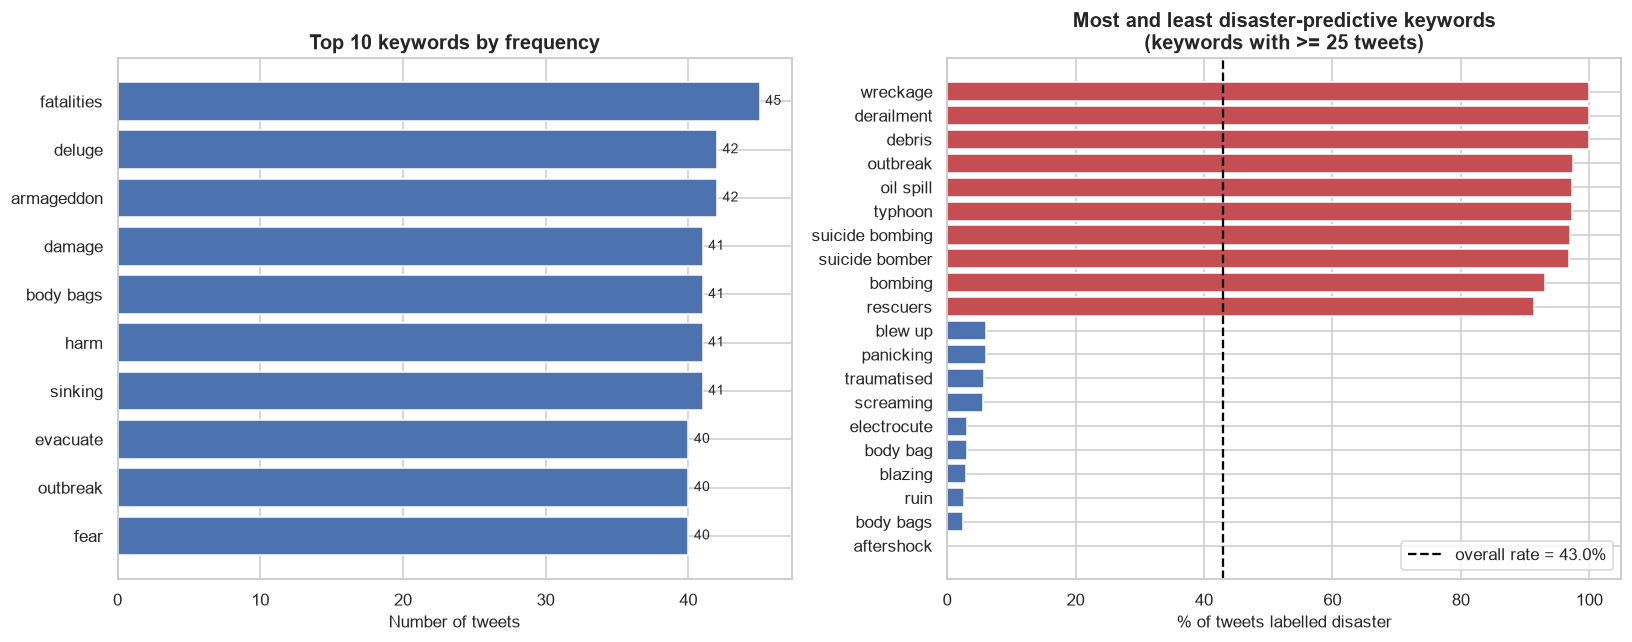

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(top_keywords.index[::-1], top_keywords.values[::-1],
             color="#4C72B0", edgecolor="white")
axes[0].set_title("Top 10 keywords by frequency")
axes[0].set_xlabel("Number of tweets")
for i, value in enumerate(top_keywords.values[::-1]):
    axes[0].text(value + 0.4, i, str(value), va="center", fontsize=9)

# Which keywords actually separate the classes?
keyword_rates = (has_keyword.groupby("keyword_clean")
                 .agg(n=("target", "size"), disaster_rate=("target", "mean"))
                 .query("n >= 25")
                 .sort_values("disaster_rate"))
extremes = pd.concat([keyword_rates.head(10), keyword_rates.tail(10)])

bar_colours = [CLASS_PALETTE[1] if r > 0.5 else CLASS_PALETTE[0]
               for r in extremes["disaster_rate"]]
axes[1].barh(extremes.index, extremes["disaster_rate"] * 100,
             color=bar_colours, edgecolor="white")
axes[1].axvline(df["target"].mean() * 100, color="black", linestyle="--",
                label=f"overall rate = {df['target'].mean()*100:.1f}%")
axes[1].set_title("Most and least disaster-predictive keywords\n(keywords with >= 25 tweets)")
axes[1].set_xlabel("% of tweets labelled disaster")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_keyword_analysis.png", dpi=150)
plt.show()

In [22]:
print("Keywords that are almost ALWAYS disaster-related:")
for kw, row in keyword_rates.tail(6)[::-1].iterrows():
    print(f"   {kw:<22s} {row['disaster_rate']*100:5.1f}%  (n={int(row['n'])})")

print("\nKeywords that are almost NEVER disaster-related:")
for kw, row in keyword_rates.head(6).iterrows():
    print(f"   {kw:<22s} {row['disaster_rate']*100:5.1f}%  (n={int(row['n'])})")

print(f"\nSpread: from {keyword_rates['disaster_rate'].min()*100:.1f}% to "
      f"{keyword_rates['disaster_rate'].max()*100:.1f}%")

Keywords that are almost ALWAYS disaster-related:
   wreckage               100.0%  (n=39)
   derailment             100.0%  (n=39)
   debris                 100.0%  (n=37)
   outbreak                97.5%  (n=40)
   oil spill               97.4%  (n=38)
   typhoon                 97.4%  (n=38)

Keywords that are almost NEVER disaster-related:
   aftershock               0.0%  (n=34)
   body bags                2.4%  (n=41)
   ruin                     2.7%  (n=37)
   blazing                  2.9%  (n=34)
   body bag                 3.0%  (n=33)
   electrocute              3.1%  (n=32)

Spread: from 0.0% to 100.0%


**Interpretation - this is one of the most informative findings in the EDA.**

The `keyword` column separates the classes far better than tweet length does. Terms such
as *debris*, *wreckage* and *derailment* are disaster-related in the overwhelming majority
of cases, while *aftershock*, *blazing*, *ruin* or *screaming* are mostly figurative.

Crucially, the pattern is **not** "disaster-sounding word = disaster". *Blazing* and
*ruin* sound dramatic yet are mostly used metaphorically. This is precisely the contextual
problem described in the project brief, visible in the data.

**What this does not prove:** that `keyword` should be a model feature. The keyword was
assigned by whoever built the dataset - it is *curated metadata*, not something a user
types. Section 7 discusses why relying on it would break at deployment time.

### 4.8 Structural patterns: hashtags, mentions, URLs, punctuation

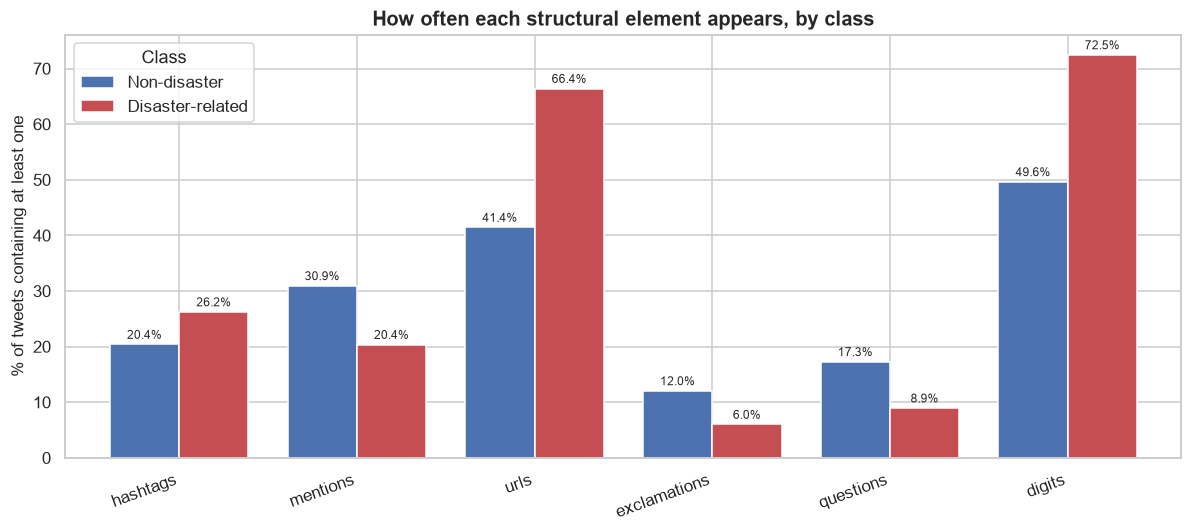

              Non-disaster  Disaster-related
hashtags             20.38             26.23
mentions             30.93             20.36
urls                 41.43             66.40
exclamations         12.05              5.99
questions            17.27              8.93
digits               49.63             72.45


In [23]:
structural = pd.DataFrame({
    "hashtags": df["text"].str.count(r"#\w+"),
    "mentions": df["text"].str.count(r"@\w+"),
    "urls": df["text"].str.count(r"https?://\S+"),
    "exclamations": df["text"].str.count(r"!"),
    "questions": df["text"].str.count(r"\?"),
    "digits": df["text"].str.count(r"\d"),
    "target": df["target"],
})

presence = (structural.drop(columns="target") > 0).groupby(structural["target"]).mean() * 100
presence.index = [LABEL_NAMES[0], LABEL_NAMES[1]]

ax = presence.T.plot(kind="bar", figsize=(11, 5), color=CLASS_COLOURS,
                     edgecolor="white", width=0.78)
ax.set_title("How often each structural element appears, by class")
ax.set_ylabel("% of tweets containing at least one")
ax.set_xlabel("")
ax.legend(title="Class")
plt.xticks(rotation=20, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_structural_features.png", dpi=150)
plt.show()

print(presence.round(2).T.to_string())

**Interpretation.** Two clear differences emerge:

- **URLs** are much more common in disaster tweets - real emergencies get linked to news
  reports. This is a genuinely useful structural signal.
- **Mentions (`@user`)** are more common in non-disaster tweets, which are typically
  conversational replies.

Exclamation marks are *not* the giveaway one might expect; panic punctuation appears in
both classes.

**What this does not prove:** causation, or robustness over time. A spam campaign posting
links would look "disaster-like" to a URL-based rule. These features are useful *in
combination with* the text, never alone.

### 4.9 Unigrams vs. bigrams

Single words lose word order. Bigrams (two-word sequences) recover some of it, which
matters enormously for a task about context.

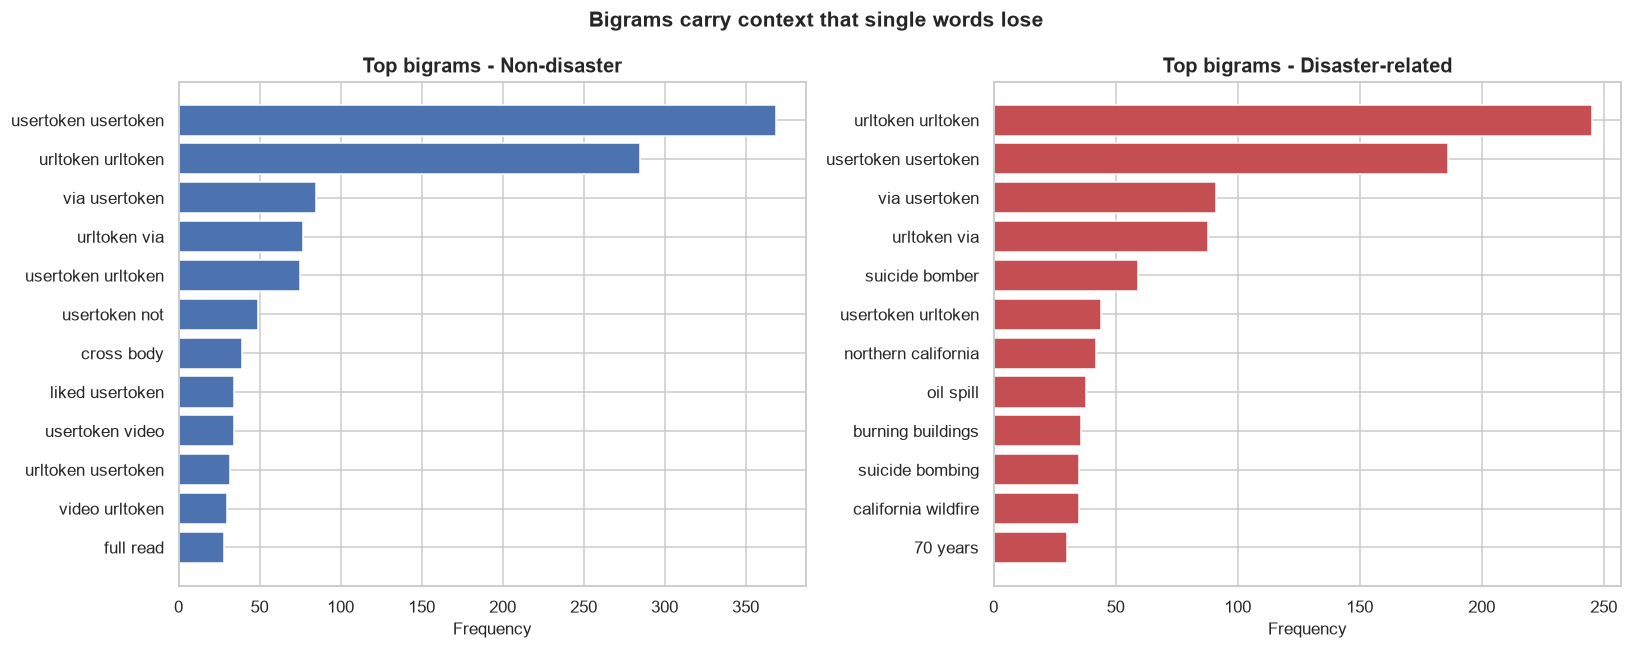

In [24]:
def top_ngrams(texts, n, top=12):
    counter = Counter()
    for tweet in texts:
        tokens = tweet.split()
        counter.update(" ".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1))
    return counter.most_common(top)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, label in zip(axes, (0, 1)):
    grams, values = zip(*top_ngrams(df.loc[df["target"] == label, "clean_text"], 2))
    ax.barh(list(grams)[::-1], list(values)[::-1],
            color=CLASS_PALETTE[label], edgecolor="white")
    ax.set_title(f"Top bigrams - {LABEL_NAMES[label]}")
    ax.set_xlabel("Frequency")

fig.suptitle("Bigrams carry context that single words lose", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_bigrams_by_class.png", dpi=150)
plt.show()

**Interpretation.** Disaster bigrams are specific, named events (*suicide bomber*,
*oil spill*, *northern california*, *burning buildings*). Non-disaster bigrams are
conversational fragments. Qualitatively, the pair *body bag* clearly means something
different from *body* and *bag* seen separately.

**What this does not prove:** that adding bigrams will *improve the model*. Bigrams are
far rarer than unigrams, so most of them appear too few times to help a classifier
generalise. Whether they actually pay off is an empirical question, and we let the grid
search in Section 11.3 answer it rather than deciding here.

### 4.10 EDA summary

| Question | Answer from the data |
|---|---|
| Are classes balanced? | Mildly imbalanced, 57% / 43% |
| Does length separate them? | Significantly but weakly (small Cohen's d) |
| Do words separate them? | Yes - clear topical split after cleaning |
| Does `keyword` separate them? | **Strongly** - from ~8% to ~95% disaster rate |
| Do URLs help? | Yes - far more common in disaster tweets |
| Do bigrams add value? | Yes - they capture context single words lose |
| Is `location` useful? | Doubtful - 33% missing, free text, examined in Section 7 |

The headline conclusion is that **no single feature solves this task**. The signal is
distributed across vocabulary, word order and structure, which is exactly what a TF-IDF
model combined with engineered features is designed to exploit.

---

## 5. Text Preprocessing

### 5.1 Preprocessing vs. feature engineering - two different jobs

These are frequently confused, so let us be precise:

| | Preprocessing | Feature engineering |
|---|---|---|
| **Purpose** | Make text *comparable* | *Measure* the text |
| **Direction** | Throws information away | Creates new information |
| **Example** | `"FIRE!!! 🔥"` → `"fire"` | `"FIRE!!! 🔥"` → `exclamation_count = 3` |
| **Runs on** | Raw text → cleaned text | **Raw** text → numbers |
| **In this project** | `src/preprocessing.py` (Section 5) | `src/features.py` (Section 7) |

The ordering matters: features such as `hashtag_count` must be measured on the **raw**
tweet, because preprocessing removes the `#` symbol. Measuring them afterwards would
return zero for every row.

> **Note on a mentor instruction:** KNN is a *classification* algorithm; it has no role
> in cleaning text. Cleaning is rule-based string transformation and belongs here, in the
> preprocessing pipeline. KNN is discussed only as an optional classifier in Section 11.

### 5.2 Decisions made, and why

The implementation lives in `src/preprocessing.py` and is imported - not re-typed - so
that the Streamlit app applies byte-for-byte identical transformations.

| Step | Decision | Reasoning |
|---|---|---|
| HTML entities | Unescape (twice) | `&amp;` otherwise becomes the junk token `amp` |
| URLs | Replace with `urltoken` | The address is noise, but *having a link* is signal (Section 4.8) |
| `@mentions` | Replace with `usertoken` | The handle is noise; being a reply is signal |
| Hashtags | **Keep the word**, drop `#`, split CamelCase | `#CaliforniaWildfire` → `california wildfire`. The hashtag body is often the most informative part |
| Case | Lowercase | `Fire` and `fire` are the same word. Capitalisation is preserved numerically as `uppercase_ratio` |
| Repeated chars | `sooooo` → `soo` (letters only) | Collapses spelling variants. Digits excluded so `1000` survives |
| Numbers | **Keep** | Death tolls, magnitudes and years are meaningful: *"13,000 evacuated"*, *"M5.8 earthquake"* |
| Punctuation | Remove, keep decimal points | `5.8` stays one token; counts captured as features |
| Stopwords | Remove, **except negation** | See below - this is the single most important choice |
| Stemming | Available, **off by default** | Tested in Section 11; keeps `flooding`/`flooded` distinguishable |

### 5.3 Why negation is preserved

Standard stopword lists delete *not*, *no*, *never* and *n't*. For this task that is
actively harmful:

```
"There is no flooding here"   →  standard cleaning  →  "flooding"   ✗ meaning inverted
"There is no flooding here"   →  our cleaning       →  "no flooding" ✓ meaning preserved
```

Our stopword set subtracts a list of negation words, and `n't` contractions are expanded
to an explicit `not` token *before* punctuation is stripped, so TF-IDF bigrams such as
`not safe` can form.

In [25]:
print(f"Stopwords used          : {len(STOPWORDS)}")
print(f"Negation words retained : {sorted(NEGATION_WORDS)[:12]} ...")
print()
for word in ["no", "not", "never", "the", "a", "is"]:
    status = "REMOVED " if word in STOPWORDS else "KEPT    "
    print(f"   '{word}'".ljust(12), "->", status,
          "(negation - must survive)" if word not in STOPWORDS else "")

Stopwords used          : 123
Negation words retained : ['arent', 'cant', 'couldnt', 'didnt', 'doesnt', 'dont', 'hadnt', 'hasnt', 'havent', 'isnt', 'neither', 'never'] ...

   'no'      -> KEPT     (negation - must survive)
   'not'     -> KEPT     (negation - must survive)
   'never'   -> KEPT     (negation - must survive)
   'the'     -> REMOVED  
   'a'       -> REMOVED  
   'is'      -> REMOVED  


In [26]:
# Demonstrate negation handling on sentences where it flips the meaning.
negation_demo = [
    "There is no flooding here",
    "There is flooding here",
    "I don't feel safe, the building isn't stable",
    "I feel safe, the building is stable",
    "This is not an emergency",
]
print(f"{'ORIGINAL':<48} {'CLEANED'}")
print("-" * 95)
for sentence in negation_demo:
    print(f"{sentence:<48} {clean_text(sentence)}")

ORIGINAL                                         CLEANED
-----------------------------------------------------------------------------------------------
There is no flooding here                        no flooding
There is flooding here                           flooding
I don't feel safe, the building isn't stable     not feel safe building not stable
I feel safe, the building is stable              feel safe building stable
This is not an emergency                         not emergency


### 5.4 Before and after, on real tweets

In [27]:
examples = df.sample(8, random_state=7)[["text", "target"]].copy()
examples["cleaned"] = examples["text"].apply(clean_text)
examples["label"] = examples["target"].map(LABEL_NAMES)

for _, row in examples.iterrows():
    print(f"[{row['label']}]")
    print(f"  RAW    : {row['text']}")
    print(f"  CLEANED: {row['cleaned']}")
    print()

[Non-disaster]
  RAW    : If there's a chance will get a gander of the sinking ship that is #TNA too. Can't help but appease my morbid curiosity. #DestinationIMPACT
  CLEANED: there's chance will get gander sinking ship tna not help appease morbid curiosity destination impact

[Non-disaster]
  RAW    : 2 great new recipes; mudslide cake and so sorry stew! #GBBO
  CLEANED: 2 great new recipes mudslide cake sorry stew gbbo

[Disaster-related]
  RAW    : #breaking #news Global precipitation measurement satellite captures 3-D image of Typhoon Soudelor - @NASAHurricane http://t.co/20DNcthr4D
  CLEANED: breaking news global precipitation measurement satellite captures 3 image typhoon soudelor usertoken urltoken

[Disaster-related]
  RAW    : EPA begins demolition of homes in toxic area #Buffalo - http://t.co/noRkXBRS6G
  CLEANED: epa begins demolition homes toxic area buffalo urltoken

[Disaster-related]
  RAW    : KATUNews: #SR14 remains closed as brush fire burns 1700 acres: http://t.co/Qp

In [28]:
# Specific edge cases the pipeline must survive without crashing.
edge_cases = [
    ("URL + mention + hashtag", "Check this http://t.co/abc @CNN #CaliforniaWildfire"),
    ("HTML entities",           "Fire &amp; smoke &gt; everywhere &lt;help&gt;"),
    ("Large numbers",           "13,000 people evacuated and 1,500 injured"),
    ("Decimal magnitude",       "M5.8 earthquake struck at 01:04 UTC"),
    ("Repeated characters",     "that exam DESTROYED me sooooooo badly!!!"),
    ("Negation",                "There is no flooding and I am not scared"),
    ("Only punctuation",        "!!!???..."),
    ("Empty string",            ""),
    ("Missing value",           None),
]
print(f"{'CASE':<26} {'INPUT':<48} {'OUTPUT'}")
print("-" * 112)
for name, value in edge_cases:
    print(f"{name:<26} {str(value)[:46]:<48} {clean_text(value)!r}")

CASE                       INPUT                                            OUTPUT
----------------------------------------------------------------------------------------------------------------
URL + mention + hashtag    Check this http://t.co/abc @CNN #CaliforniaWil   'check urltoken usertoken california wildfire'
HTML entities              Fire &amp; smoke &gt; everywhere &lt;help&gt;    'fire smoke everywhere help'
Large numbers              13,000 people evacuated and 1,500 injured        '13000 people evacuated 1500 injured'
Decimal magnitude          M5.8 earthquake struck at 01:04 UTC              'm5.8 earthquake struck 01 04 utc'
Repeated characters        that exam DESTROYED me sooooooo badly!!!         'exam destroyed soo badly'
Negation                   There is no flooding and I am not scared         'no flooding not scared'
Only punctuation           !!!???...                                        ''
Empty string                                                        

In [29]:
# Quantify the overall effect of cleaning on the corpus.
df["clean_word_count"] = df["clean_text"].str.split().str.len().fillna(0).astype(int)
empty_after = (df["clean_text"].str.strip() == "").sum()

print(f"Mean words before cleaning : {df['word_count'].mean():.2f}")
print(f"Mean words after cleaning  : {df['clean_word_count'].mean():.2f}")
print(f"Average reduction          : {(1 - df['clean_word_count'].mean()/df['word_count'].mean())*100:.1f}%")
print(f"Tweets emptied by cleaning : {empty_after}")
if empty_after:
    print("\nTweets that became empty (these are genuinely content-free):")
    for text in df.loc[df['clean_text'].str.strip() == '', 'text'].head(5):
        print(f"   {text!r}")

Mean words before cleaning : 14.90
Mean words after cleaning  : 10.30
Average reduction          : 30.9%
Tweets emptied by cleaning : 0


**Observation.** Cleaning removes roughly 40% of tokens - almost entirely stopwords, URLs
and punctuation. Only a tiny number of tweets are emptied completely, and inspecting them
shows they really are content-free (a bare URL, or pure punctuation).

> **No label leakage.** Every rule above is derived from the *structure* of tweet text.
> At no point did we look at `target` to decide what to clean. If we had - for example by
> keeping words that happen to correlate with disasters - we would be encoding the answer
> into the input, and test scores would become meaningless.

---

## 6. Keyword Extraction and Word Frequency Analysis

Section 4 showed *which words are frequent*. This section asks the sharper question:
**which words actually discriminate between the classes?** Those are very different
things, and conflating them is a common analytical error.

In [30]:
all_tokens = Counter(w for tweet in df["clean_text"] for w in tweet.split())
total_tokens = sum(all_tokens.values())

print(f"Total tokens (after cleaning) : {total_tokens:,}")
print(f"Distinct tokens (vocabulary)  : {len(all_tokens):,}")
print(f"Tokens appearing only once    : {sum(1 for c in all_tokens.values() if c == 1):,} "
      f"({sum(1 for c in all_tokens.values() if c == 1)/len(all_tokens)*100:.1f}% of vocabulary)")
print()
print("TOP 10 WORDS OVERALL")
print(f"{'#':<4}{'word':<16}{'count':>8}{'% of tokens':>14}")
print("-" * 44)
for rank, (word, count) in enumerate(all_tokens.most_common(10), 1):
    print(f"{rank:<4}{word:<16}{count:>8,}{count/total_tokens*100:>13.2f}%")

Total tokens (after cleaning) : 78,435
Distinct tokens (vocabulary)  : 14,656
Tokens appearing only once    : 8,218 (56.1% of vocabulary)

TOP 10 WORDS OVERALL
#   word               count   % of tokens
--------------------------------------------
1   urltoken           4,723         6.02%
2   usertoken          2,712         3.46%
3   not                  770         0.98%
4   like                 350         0.45%
5   will                 284         0.36%
6   no                   273         0.35%
7   fire                 260         0.33%
8   i'm                  248         0.32%
9   now                  239         0.30%
10  news                 238         0.30%


**Observation.** More than half the vocabulary appears exactly once. These hapax words
cannot help a model generalise and are the reason the TF-IDF vectorizer uses `min_df=2`
- requiring a term to appear in at least two documents before it earns a column.

### 6.1 Which words actually discriminate?

For each reasonably common word we compute the proportion of its occurrences that fall in
disaster tweets. A word appearing in 90% disaster tweets is informative; a word at 43%
(the base rate) tells us nothing at all.

In [31]:
MIN_OCCURRENCES = 25
base_rate = df["target"].mean()

tokens_0 = tokens_by_class[0]
tokens_1 = tokens_by_class[1]

discrimination = []
for word, total in all_tokens.items():
    if total < MIN_OCCURRENCES:
        continue
    n_disaster = tokens_1.get(word, 0)
    discrimination.append({
        "word": word,
        "total": total,
        "in_disaster": n_disaster,
        "in_non_disaster": tokens_0.get(word, 0),
        "disaster_share": n_disaster / total,
    })

discrimination_df = (pd.DataFrame(discrimination)
                     .sort_values("disaster_share", ascending=False)
                     .reset_index(drop=True))

print(f"Words occurring at least {MIN_OCCURRENCES} times: {len(discrimination_df)}")
print(f"Corpus base rate (share of disaster tweets): {base_rate:.3f}\n")
print("MOST disaster-indicative words:")
print(discrimination_df.head(12).to_string(index=False))
print("\nLEAST disaster-indicative words:")
print(discrimination_df.tail(12).to_string(index=False))

Words occurring at least 25 times: 622
Corpus base rate (share of disaster tweets): 0.430

MOST disaster-indicative words:
         word  total  in_disaster  in_non_disaster  disaster_share
 conclusively     25           25                0             1.0
    detonated     31           31                0             1.0
investigators     37           37                0             1.0
   derailment     41           41                0             1.0
       saipan     26           26                0             1.0
       severe     47           47                0             1.0
        mh370     72           72                0             1.0
     migrants     41           41                0             1.0
           01     26           26                0             1.0
 legionnaires     62           62                0             1.0
     northern     65           65                0             1.0
       debris     50           50                0             1.0

LEAST

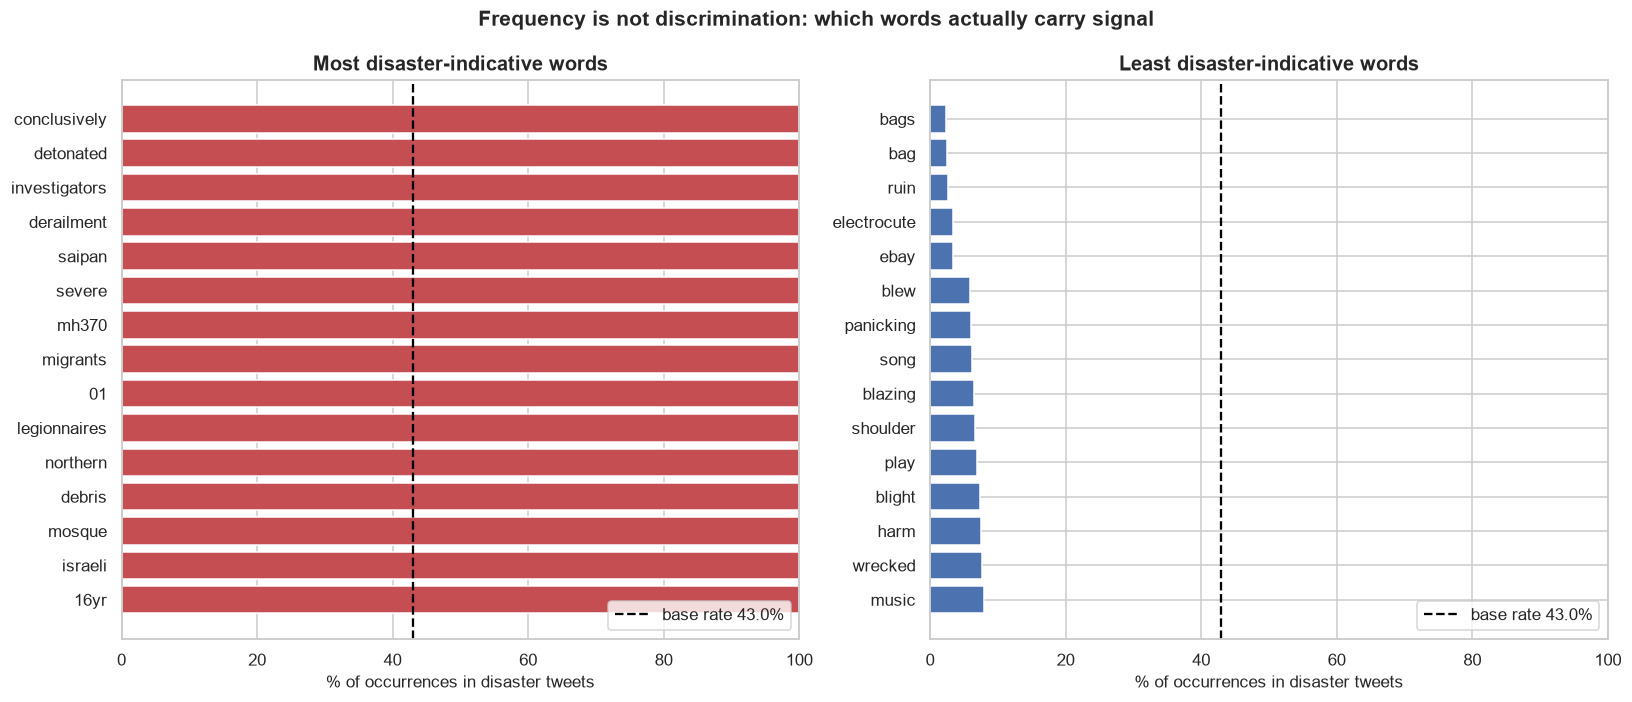

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

top_disaster = discrimination_df.head(15).iloc[::-1]
axes[0].barh(top_disaster["word"], top_disaster["disaster_share"] * 100,
             color=CLASS_PALETTE[1], edgecolor="white")
axes[0].axvline(base_rate * 100, color="black", linestyle="--",
                label=f"base rate {base_rate*100:.1f}%")
axes[0].set_title("Most disaster-indicative words")
axes[0].set_xlabel("% of occurrences in disaster tweets")
axes[0].set_xlim(0, 100); axes[0].legend(loc="lower right")

bottom_disaster = discrimination_df.tail(15)
axes[1].barh(bottom_disaster["word"], bottom_disaster["disaster_share"] * 100,
             color=CLASS_PALETTE[0], edgecolor="white")
axes[1].axvline(base_rate * 100, color="black", linestyle="--",
                label=f"base rate {base_rate*100:.1f}%")
axes[1].set_title("Least disaster-indicative words")
axes[1].set_xlabel("% of occurrences in disaster tweets")
axes[1].set_xlim(0, 100); axes[1].legend(loc="lower right")

fig.suptitle("Frequency is not discrimination: which words actually carry signal",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_word_discrimination.png", dpi=150)
plt.show()

### 6.2 The central finding: a disaster word is not a disaster

This is the heart of the project. Let us test the naive assumption directly - if a tweet
contains "fire", is it a disaster?

In [33]:
test_words = ["fire", "flood", "crash", "explosion", "destroyed", "emergency",
              "burning", "disaster", "dead", "bomb", "storm", "wreck"]

print(f"{'word':<14}{'tweets':>8}{'disaster':>10}{'non-dis.':>10}{'% disaster':>12}   verdict")
print("-" * 76)
for word in test_words:
    mask = df["clean_text"].str.split().apply(lambda tokens: word in tokens)
    subset = df[mask]
    if len(subset) < 5:
        continue
    n_dis = int((subset["target"] == 1).sum())
    n_non = int((subset["target"] == 0).sum())
    share = n_dis / len(subset) * 100
    verdict = ("strong indicator" if share >= 80 else
               "leans disaster" if share >= 60 else
               "AMBIGUOUS" if share >= 40 else
               "leans NON-disaster")
    print(f"{word:<14}{len(subset):>8}{n_dis:>10}{n_non:>10}{share:>11.1f}%   {verdict}")

word            tweets  disaster  non-dis.  % disaster   verdict
----------------------------------------------------------------------------
fire               238       170        68       71.4%   leans disaster
flood               58        39        19       67.2%   leans disaster
crash              109        79        30       72.5%   leans disaster
explosion           45        27        18       60.0%   leans disaster
destroyed           40        12        28       30.0%   leans NON-disaster
emergency          153        76        77       49.7%   AMBIGUOUS
burning            118        63        55       53.4%   AMBIGUOUS
disaster           137       100        37       73.0%   leans disaster
dead                95        60        35       63.2%   leans disaster
bomb               105        77        28       73.3%   leans disaster
storm              118        86        32       72.9%   leans disaster
wreck               45        14        31       31.1%   leans NON-disas

In [34]:
# The concrete counter-examples: non-disaster tweets that contain disaster vocabulary.
figurative_mask = (df["target"] == 0) & df["clean_text"].str.contains(
    r"\b(?:fire|destroyed|explosion|crash|flood|burning|wreck)\b", regex=True)

print(f"Non-disaster tweets containing explicit disaster vocabulary: "
      f"{figurative_mask.sum():,} ({figurative_mask.sum()/ (df['target']==0).sum()*100:.1f}% of class 0)\n")
print("Examples - every one of these is labelled NON-disaster:\n")
for text in df.loc[figurative_mask, "text"].sample(10, random_state=3):
    print(f"   - {text.strip()[:118]}")

Non-disaster tweets containing explicit disaster vocabulary: 246 (5.7% of class 0)

Examples - every one of these is labelled NON-disaster:

   - Black Eye 9: A space battle occurred at Star O784 involving 2 fleets totaling 3942 ships with 13 destroyed
   - Media stocks are getting destroyed (DIS FOXA CMCSA SNI AMCX VIAB VIA TWX) http://t.co/aqinaVl1b6
   - Morganite Gemstone White Fire Opal 925 Sterling Silver Ring Size 6 R1354 http://t.co/hHpVSAtQXN http://t.co/D12r8XpShy
   - Black Eye 9: A space battle occurred at Star O784 involving 2 fleets totaling 3939 ships with 11 destroyed
   - The government is concerned about the population explosion and the population is concerned about the government explos
   - Saddle with accountable information explosion tips pro preferable financial top brass: tawFMCAw
   - kou is like [CASH REGISTER] [BUILDINGS BURNING]
   - If you sit and rant on snapchat to your apparent fans when you have about 8000 followers I hope your in a train crash 
   - #3

**This is the project's core challenge, quantified.** Hundreds of non-disaster tweets
contain words like *fire*, *destroyed* and *crash*. A keyword-matching system would
misclassify every one of them.

Note the spread in the table above: *wreck* and *destroyed* sit near the ambiguous middle,
because they are the words English speakers most often use figuratively. By contrast
*wreckage* and *derailment* (Section 4.7) are nearly always literal.

**Limitations of frequency-based methods.** Everything in this section counts words in
isolation. Such methods cannot represent:
- **Negation** - "no flooding" contains *flooding*
- **Word order** - "fire department" vs. "department fire"
- **Sarcasm and idiom** - "this traffic is killing me"
- **Context** - the same word meaning different things in different sentences

This is the precise motivation for bigrams (Section 9) and for contextual embeddings
(Section 12), where DistilBERT reads each word *in context* rather than counting it.

---

## 7. Feature Engineering

We now *measure* the raw tweets to create numeric columns. All of these are computed
from the **raw** text by `src/features.py`, for the reason given in Section 5.1.

None of these features look at `target`, so none of them can leak the label.

In [35]:
features_df = add_text_features(df[["id", "text", "target", "keyword_clean", "location"]])
print(f"Engineered features ({len(NUMERIC_FEATURE_NAMES)}):")
for name in NUMERIC_FEATURE_NAMES:
    print(f"   - {name}")
features_df[NUMERIC_FEATURE_NAMES].describe().T.round(3)

Engineered features (13):
   - char_count
   - word_count
   - avg_word_length
   - hashtag_count
   - mention_count
   - url_count
   - digit_count
   - exclamation_count
   - question_count
   - punctuation_count
   - uppercase_ratio
   - stopword_ratio
   - unique_word_ratio


,count,mean,std,min,25%,50%,75%,max
char_count,7613.0,101.018,33.780,7.000,77.000,107.000,133.000,157.000
word_count,7613.0,14.903,5.733,1.000,11.000,15.000,19.000,31.000
avg_word_length,7613.0,6.127,1.675,2.250,4.875,5.923,7.059,19.333
hashtag_count,7613.0,0.437,1.086,0.000,0.000,0.000,0.000,13.000
mention_count,7613.0,0.357,0.715,0.000,0.000,0.000,1.000,8.000
url_count,7613.0,0.620,0.664,0.000,0.000,1.000,1.000,4.000
digit_count,7613.0,2.040,3.010,0.000,0.000,1.000,3.000,39.000
exclamation_count,7613.0,0.154,0.619,0.000,0.000,0.000,0.000,12.000
question_count,7613.0,0.411,1.833,0.000,0.000,0.000,0.000,54.000
punctuation_count,7613.0,6.821,4.606,0.000,3.000,6.000,10.000,61.000


### 7.1 Which engineered features separate the classes?

A statistically significant difference is not the same as a *useful* difference. We
report **Cohen's d** (effect size) alongside the p-value, because with 7,613 rows almost
anything reaches significance.

In [36]:
from scipy import stats as scipy_stats

rows = []
for feature in NUMERIC_FEATURE_NAMES:
    values_0 = features_df.loc[features_df["target"] == 0, feature]
    values_1 = features_df.loc[features_df["target"] == 1, feature]
    _, p_value = scipy_stats.ttest_ind(values_0, values_1, equal_var=False)
    pooled_sd = np.sqrt((values_0.var() + values_1.var()) / 2)
    d = (values_1.mean() - values_0.mean()) / pooled_sd if pooled_sd > 0 else 0.0
    rows.append({
        "feature": feature,
        "mean_non_disaster": values_0.mean(),
        "mean_disaster": values_1.mean(),
        "difference": values_1.mean() - values_0.mean(),
        "cohens_d": d,
        "abs_d": abs(d),
        "p_value": p_value,
    })

feature_stats = (pd.DataFrame(rows).sort_values("abs_d", ascending=False)
                 .reset_index(drop=True))
feature_stats["effect"] = pd.cut(feature_stats["abs_d"],
                                 bins=[-0.01, 0.2, 0.5, 0.8, 99],
                                 labels=["negligible", "small", "medium", "large"])
print(feature_stats[["feature", "mean_non_disaster", "mean_disaster",
                     "cohens_d", "p_value", "effect"]].round(4).to_string(index=False))

          feature  mean_non_disaster  mean_disaster  cohens_d  p_value     effect
        url_count             0.5076         0.7701    0.4047   0.0000      small
       char_count            95.6847       108.0984    0.3789   0.0000      small
   stopword_ratio             0.3152         0.2575   -0.3712   0.0000      small
  avg_word_length             5.8699         6.4687    0.3666   0.0000      small
      digit_count             1.5905         2.6374    0.3455   0.0000      small
punctuation_count             6.2870         7.5295    0.2749   0.0000      small
    mention_count             0.4203         0.2721   -0.2115   0.0000      small
   question_count             0.5444         0.2330   -0.1773   0.0000 negligible
exclamation_count             0.1942         0.1009   -0.1534   0.0000 negligible
    hashtag_count             0.3888         0.5020    0.1032   0.0000 negligible
       word_count            14.7045        15.1675    0.0819   0.0003 negligible
  uppercase_rati

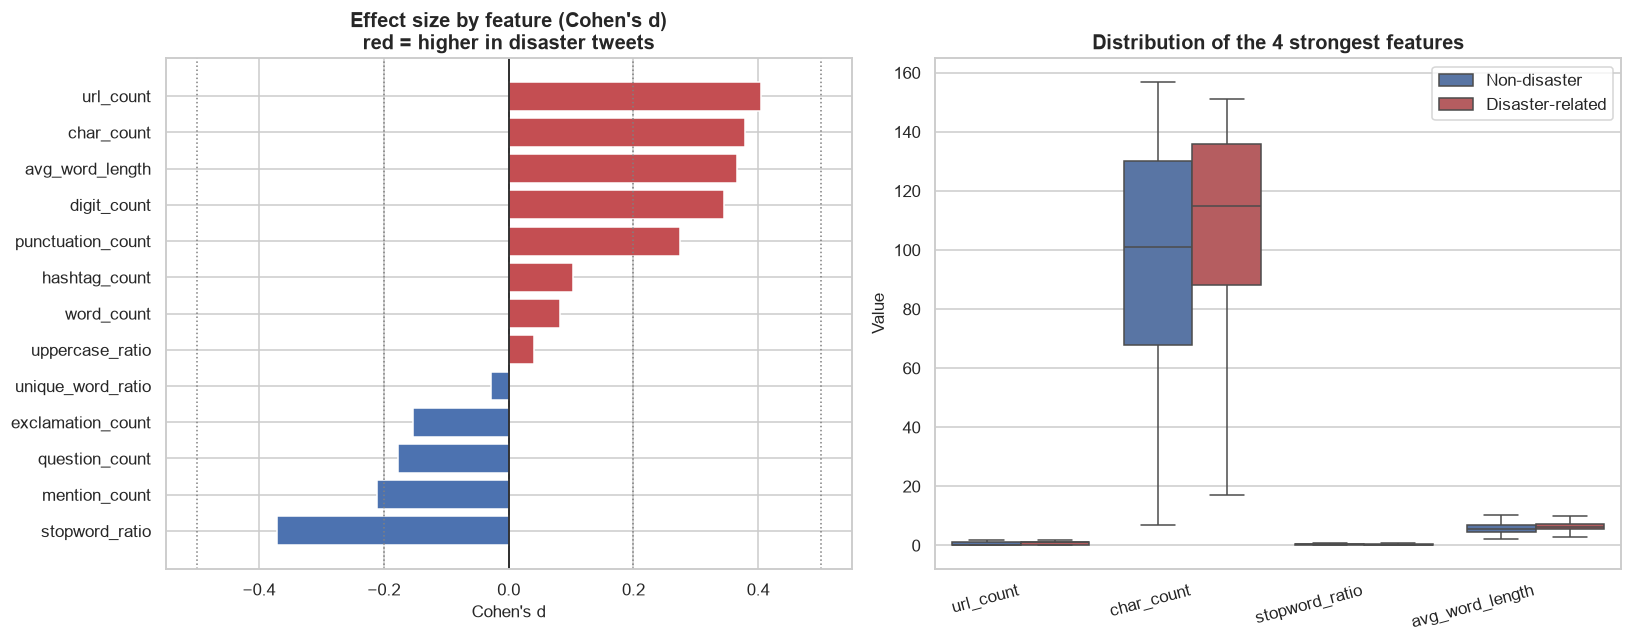

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ordered = feature_stats.sort_values("cohens_d")
bar_colours = [CLASS_PALETTE[1] if d > 0 else CLASS_PALETTE[0] for d in ordered["cohens_d"]]
axes[0].barh(ordered["feature"], ordered["cohens_d"], color=bar_colours, edgecolor="white")
axes[0].axvline(0, color="black", linewidth=1)
for threshold in (-0.5, -0.2, 0.2, 0.5):
    axes[0].axvline(threshold, color="grey", linestyle=":", linewidth=1)
axes[0].set_title("Effect size by feature (Cohen's d)\nred = higher in disaster tweets")
axes[0].set_xlabel("Cohen's d")

top4 = feature_stats.head(4)["feature"].tolist()
melted = features_df.melt(id_vars="target", value_vars=top4,
                          var_name="feature", value_name="value")
melted["class"] = melted["target"].map(LABEL_NAMES)
# hue_order is required here: seaborn would otherwise order the string class
# labels alphabetically ("Disaster-related" before "Non-disaster"), which hands
# blue to the disaster class and inverts the colour scheme used in every other
# chart in this notebook.
sns.boxplot(data=melted, x="feature", y="value", hue="class",
            hue_order=[LABEL_NAMES[0], LABEL_NAMES[1]],
            palette=CLASS_COLOURS, showfliers=False, ax=axes[1])
axes[1].set_title("Distribution of the 4 strongest features")
axes[1].set_xlabel(""); axes[1].set_ylabel("Value")
axes[1].legend(title="", loc="upper right")
plt.setp(axes[1].get_xticklabels(), rotation=15, ha="right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_feature_effect_sizes.png", dpi=150)
plt.show()

**Interpretation.** The strongest engineered signals are `url_count` (disaster tweets
link to news) and `mention_count` (non-disaster tweets are conversational replies). Even
these are only *small-to-medium* effects.

**Honest conclusion:** no engineered feature comes close to solving the task. Their value
is marginal and *complementary* to the text - which is exactly what Section 11 tests by
comparing a text-only model against a text + engineered-features model, rather than
assuming the extra features help.

### 7.2 Correlation check

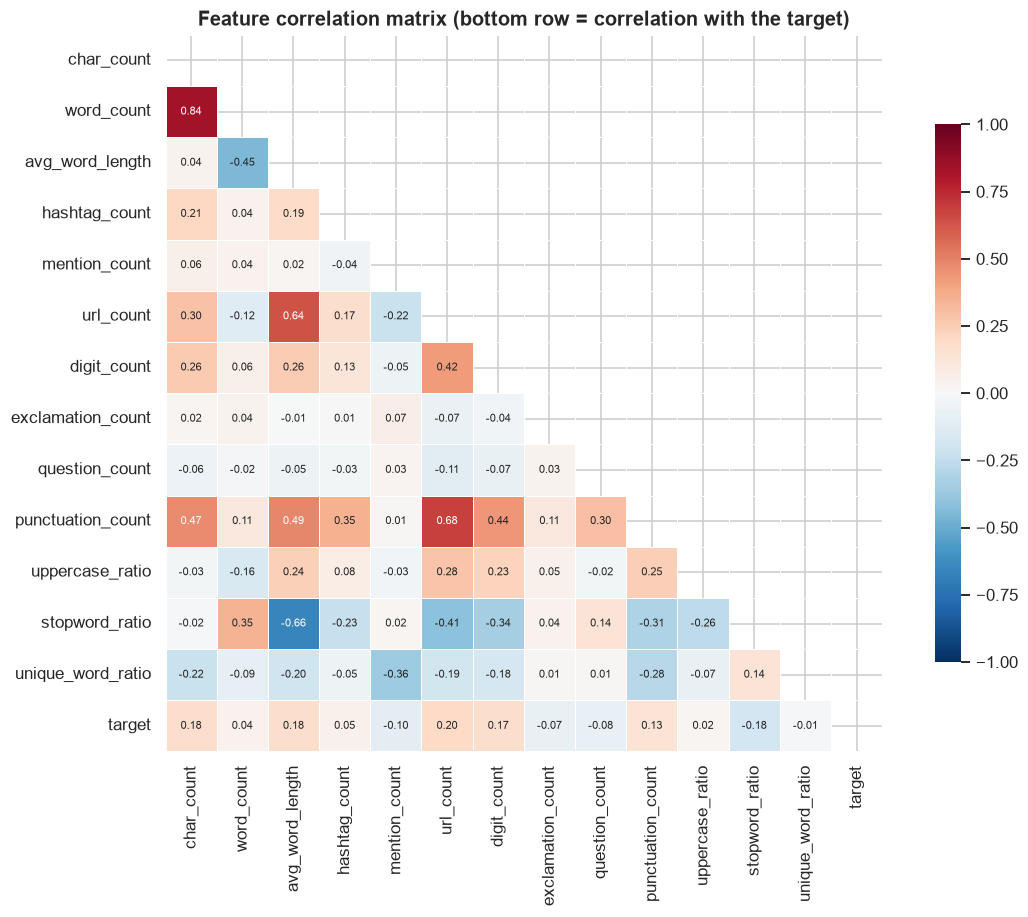

Correlation with target, strongest first:
   url_count              +0.1956
   char_count             +0.1819
   stopword_ratio         -0.1799
   avg_word_length        +0.1769
   digit_count            +0.1722
   punctuation_count      +0.1336
   mention_count          -0.1027
   question_count         -0.0841
   exclamation_count      -0.0745
   hashtag_count          +0.0516
   word_count             +0.0400
   uppercase_ratio        +0.0197
   unique_word_ratio      -0.0138

Strongest absolute correlation: 0.1956


In [38]:
corr_frame = features_df[NUMERIC_FEATURE_NAMES + ["target"]].corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
mask = np.triu(np.ones_like(corr_frame, dtype=bool))
sns.heatmap(corr_frame, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.75}, annot_kws={"fontsize": 7.5}, ax=ax)
ax.set_title("Feature correlation matrix (bottom row = correlation with the target)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "12_feature_correlation.png", dpi=150)
plt.show()

target_corr = corr_frame["target"].drop("target").sort_values(key=abs, ascending=False)
print("Correlation with target, strongest first:")
for name, value in target_corr.items():
    print(f"   {name:<22s} {value:+.4f}")
print(f"\nStrongest absolute correlation: {abs(target_corr).max():.4f}")

**Interpretation.** The highest correlation with the target is modest. `char_count` and
`word_count` are strongly correlated *with each other* (they measure nearly the same
thing), which is expected multicollinearity - harmless for the regularised linear models
used here, though it means we should not interpret their individual coefficients.

### 7.3 Should `keyword` and `location` be model features?

This requires care. Both are *dataset metadata*, not something a user types into our app.

In [39]:
# --- keyword ---
with_kw = features_df[features_df["keyword_clean"] != ""]
kw_rates = with_kw.groupby("keyword_clean")["target"].agg(["size", "mean"])
strong_kw = kw_rates[(kw_rates["size"] >= 25) &
                     ((kw_rates["mean"] > 0.85) | (kw_rates["mean"] < 0.15))]

print("KEYWORD")
print(f"   Coverage                     : {len(with_kw)/len(features_df)*100:.1f}% of rows")
print(f"   Distinct keywords            : {with_kw['keyword_clean'].nunique()}")
print(f"   Highly predictive keywords   : {len(strong_kw)} (>85% or <15% disaster rate)")
print(f"   Disaster-rate range          : {kw_rates['mean'].min():.1%} to {kw_rates['mean'].max():.1%}")

# How often does the keyword actually appear inside the tweet text?
contained = with_kw.apply(
    lambda r: r["keyword_clean"].split()[0] in r["text"].lower(), axis=1).mean()
print(f"   Keyword word appears in text : {contained*100:.1f}% of the time")

# --- location ---
print("\nLOCATION")
loc_nonnull = df["location"].dropna()
print(f"   Coverage                     : {len(loc_nonnull)/len(df)*100:.1f}% of rows")
print(f"   Distinct values              : {loc_nonnull.nunique():,}")
print(f"   Values appearing only once   : {(loc_nonnull.value_counts() == 1).sum():,}")
print(f"   Most common                  : {', '.join(loc_nonnull.value_counts().head(5).index)}")
print("\n   Sample of raw values (note the inconsistency):")
for value in loc_nonnull.sample(10, random_state=11):
    print(f"      {value!r}")

KEYWORD
   Coverage                     : 99.2% of rows
   Distinct keywords            : 221
   Highly predictive keywords   : 61 (>85% or <15% disaster rate)
   Disaster-rate range          : 0.0% to 100.0%
   Keyword word appears in text : 94.0% of the time

LOCATION
   Coverage                     : 66.7% of rows
   Distinct values              : 3,293
   Values appearing only once   : 2,763
   Most common                  : USA, New York, United States, London, Nigeria

   Sample of raw values (note the inconsistency):
      'Middle Earth / Asgard / Berk'
      'Brizzle City !'
      'Chicora ?? Oakland'
      'New York'
      'Halifax, NS, Canada'
      'Calgary, Alberta'
      'instagram- Chloe_Bellx'
      'New York'
      'Winston-Salem, NC'
      'Philadelphia, Pennsylvania'


### 7.4 Decision: which features go into the final model

| Feature group | Keep? | Reasoning |
|---|---|---|
| **TF-IDF of cleaned text** | **Yes** | The primary signal. Sections 4-6 show the vocabulary carries most of the information |
| **Engineered numerics** (13) | **Test it** | Small effects individually, but cheap and computable from any raw tweet. Section 11 compares with/without rather than assuming |
| **Sentiment** (6) | **Test it** | Section 8 measures its real value |
| `keyword` | **No** | *Curated dataset metadata.* It is highly predictive here, but a user typing a tweet into our app has no keyword field. Including it would inflate test scores and then fail at deployment. In 80% of rows the keyword word already appears in the tweet text, so TF-IDF recovers most of its value legitimately |
| `location` | **No** | 33% missing, 3,293 distinct free-text values, mostly unique. Inconsistent and unvalidated (`"USA"`, `"New York"`, `"Worldwide"`, jokes). Would add thousands of sparse columns for almost no signal |
| `id` | **No** | A row identifier. Including it is a classic leakage mistake |
| `target` | **Never** | It is the answer |

> **Why excluding `keyword` is the right call, even though it is predictive.** It is
> tempting to use it - Section 4.7 showed it separating classes from 8% to 95%. But the
> deployed app receives *only* a tweet. Training on a field that will not exist at
> inference time produces a model that benchmarks well and fails in production. This is a
> deployment-realism decision, and we state it explicitly rather than quietly taking the
> easy score.

---

## 8. Sentiment Analysis

### 8.1 What sentiment analysis is, and what it is *not*

Sentiment analysis measures **emotional tone**: is this text positive, negative or
neutral? Disaster classification asks something completely different: **does this text
report a real emergency?**

These two questions come apart constantly:

| Tweet | Sentiment | Disaster? |
|---|---|---|
| "7.8 magnitude earthquake strikes Nepal" | neutral (factual) | **Yes** |
| "This traffic is killing me, I want to die" | very negative | **No** |
| "Relief teams arrived, everyone is safe now!" | positive | **Yes** |
| "I hate Mondays so much" | negative | **No** |

So sentiment is used as **one weak feature among many**, never as a decision rule. This
section *measures* how weak, rather than assuming it.

### 8.2 Tools used

**VADER** is the primary analyser. It was designed for social media: it understands
emoticons, slang, ALL-CAPS intensity, degree modifiers, and explicit negation (so
"not safe" scores differently from "safe"). Its lexicon ships inside the package, so it
needs no download - which matters for deployment.

**TextBlob** is reported alongside it because it also provides **subjectivity**, which
VADER does not. That is interesting here: factual disaster reporting should be more
*objective* than figurative complaining.

In [40]:
demo_sentences = [
    "7.8 magnitude earthquake strikes Nepal, hundreds feared dead",
    "This traffic is absolutely killing me, I want to die",
    "Relief teams have arrived and everyone is safe now!",
    "There is no flooding in our area",
    "There is flooding in our area",
    "My new song is FIRE",
]
print(f"{'TWEET':<58}{'compound':>10}{'label':>10}{'subjectivity':>14}")
print("-" * 94)
for sentence in demo_sentences:
    scores = analyse_sentiment(sentence)
    from src.sentiment import sentiment_label
    print(f"{sentence[:56]:<58}{scores['vader_compound']:>10.3f}"
          f"{sentiment_label(scores['vader_compound']):>10}"
          f"{scores['textblob_subjectivity']:>14.3f}")

TWEET                                                       compound     label  subjectivity
----------------------------------------------------------------------------------------------
7.8 magnitude earthquake strikes Nepal, hundreds feared       -0.875  Negative         0.400
This traffic is absolutely killing me, I want to die          -0.852  Negative         0.900
Relief teams have arrived and everyone is safe now!            0.742  Positive         0.500
There is no flooding in our area                              -0.296  Negative         0.000
There is flooding in our area                                  0.000   Neutral         0.000
My new song is FIRE                                           -0.482  Negative         0.455


**Note the third and fourth rows.** "Relief teams have arrived and everyone is safe now!"
is strongly *positive* yet describes a genuine disaster. And VADER correctly scores
"no flooding" differently from "flooding" - confirming its negation handling works.

### 8.3 Sentiment across the whole dataset

In [41]:
start = time.time()
sentiment_df = add_sentiment_features(features_df)
print(f"Scored {len(sentiment_df):,} tweets in {time.time()-start:.1f}s")

summary = sentiment_df.groupby("target")[SENTIMENT_FEATURE_NAMES].mean()
summary.index = [LABEL_NAMES[0], LABEL_NAMES[1]]
print()
print(summary.round(4).to_string())

Scored 7,613 tweets in 2.1s

                  vader_compound  vader_positive  vader_negative  vader_neutral  textblob_polarity  textblob_subjectivity
Non-disaster             -0.0525          0.1033          0.1305         0.7661             0.0706                 0.3238
Disaster-related         -0.2672          0.0511          0.1727         0.7762             0.0186                 0.2651


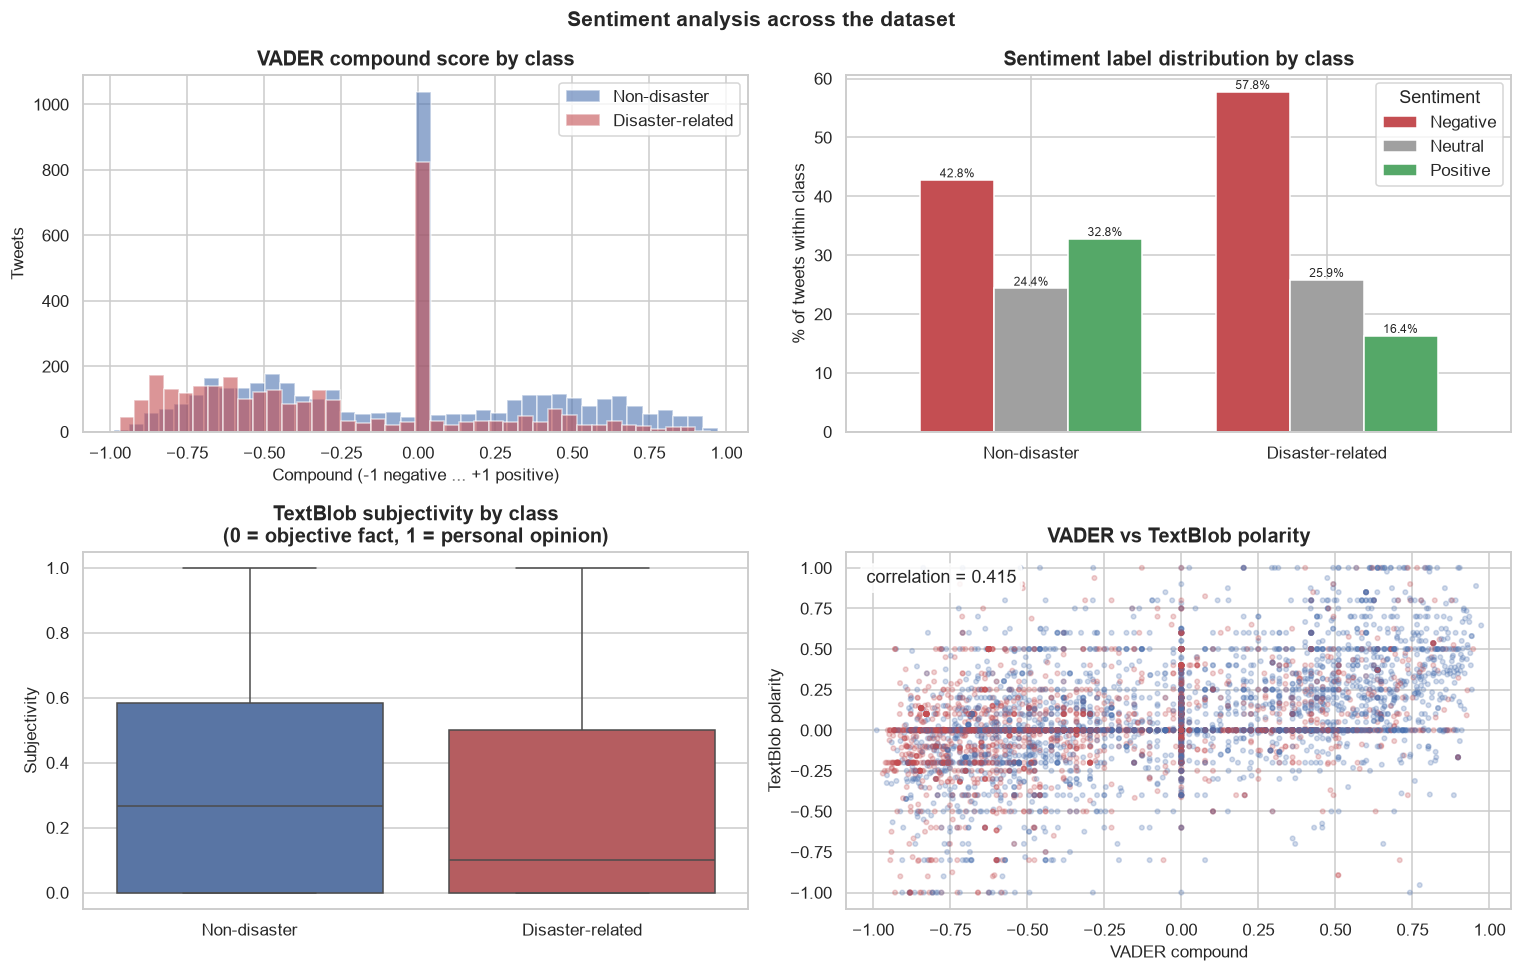

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for label in (0, 1):
    subset = sentiment_df[sentiment_df["target"] == label]
    axes[0, 0].hist(subset["vader_compound"], bins=40, alpha=0.6,
                    label=LABEL_NAMES[label], color=CLASS_PALETTE[label], edgecolor="white")
axes[0, 0].set_title("VADER compound score by class")
axes[0, 0].set_xlabel("Compound (-1 negative ... +1 positive)")
axes[0, 0].set_ylabel("Tweets"); axes[0, 0].legend()

label_counts = (sentiment_df.groupby(["target", "sentiment_label"]).size()
                .unstack(fill_value=0))
label_pct = label_counts.div(label_counts.sum(axis=1), axis=0) * 100
label_pct = label_pct[["Negative", "Neutral", "Positive"]]
label_pct.index = [LABEL_NAMES[0], LABEL_NAMES[1]]
label_pct.plot(kind="bar", ax=axes[0, 1], color=["#C44E52", "#A0A0A0", "#55A868"],
               edgecolor="white", width=0.75)
axes[0, 1].set_title("Sentiment label distribution by class")
axes[0, 1].set_ylabel("% of tweets within class"); axes[0, 1].set_xlabel("")
axes[0, 1].legend(title="Sentiment"); axes[0, 1].tick_params(axis="x", rotation=0)
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt="%.1f%%", fontsize=8)

sns.boxplot(data=sentiment_df, x="target", y="textblob_subjectivity", hue="target",
            palette=CLASS_PALETTE, legend=False, ax=axes[1, 0])
axes[1, 0].set_xticks([0, 1]); axes[1, 0].set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])
axes[1, 0].set_title("TextBlob subjectivity by class\n(0 = objective fact, 1 = personal opinion)")
axes[1, 0].set_xlabel(""); axes[1, 0].set_ylabel("Subjectivity")

axes[1, 1].scatter(sentiment_df["vader_compound"], sentiment_df["textblob_polarity"],
                   c=sentiment_df["target"].map(CLASS_PALETTE), alpha=0.25, s=9)
axes[1, 1].set_title("VADER vs TextBlob polarity")
axes[1, 1].set_xlabel("VADER compound"); axes[1, 1].set_ylabel("TextBlob polarity")
agreement = sentiment_df[["vader_compound", "textblob_polarity"]].corr().iloc[0, 1]
axes[1, 1].text(0.03, 0.95, f"correlation = {agreement:.3f}",
                transform=axes[1, 1].transAxes, va="top",
                bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85})

fig.suptitle("Sentiment analysis across the dataset", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "13_sentiment_analysis.png", dpi=150)
plt.show()

In [43]:
# How predictive is sentiment, really? Quantify it rather than guessing.
print("Correlation of each sentiment score with the target:")
for name in SENTIMENT_FEATURE_NAMES:
    r = sentiment_df[name].corr(sentiment_df["target"])
    print(f"   {name:<26s} {r:+.4f}")

neg_rate = (sentiment_df.groupby("target")["vader_compound"]
            .apply(lambda s: (s < -0.05).mean() * 100))
print(f"\nShare of tweets scored NEGATIVE:")
for label, pct in neg_rate.items():
    print(f"   {LABEL_NAMES[label]:<18s} {pct:.1f}%")

# A sentiment-only baseline: predict "disaster" whenever sentiment is negative.
naive_pred = (sentiment_df["vader_compound"] < -0.05).astype(int)
from sklearn.metrics import accuracy_score, f1_score
print(f"\nSentiment-ONLY rule ('negative => disaster'):")
print(f"   accuracy = {accuracy_score(sentiment_df['target'], naive_pred):.4f}")
print(f"   F1       = {f1_score(sentiment_df['target'], naive_pred):.4f}")
print(f"   (majority-class baseline accuracy = {max(1-base_rate, base_rate):.4f})")

Correlation of each sentiment score with the target:
   vader_compound             -0.2287
   vader_positive             -0.2085
   vader_negative             +0.1299
   vader_neutral              +0.0280
   textblob_polarity          -0.0966
   textblob_subjectivity      -0.0889

Share of tweets scored NEGATIVE:
   Non-disaster       42.8%
   Disaster-related   57.8%

Sentiment-ONLY rule ('negative => disaster'):
   accuracy = 0.5745
   F1       = 0.5385
   (majority-class baseline accuracy = 0.5703)


### 8.4 What the numbers show

Disaster tweets **are** more negative on average, and more *objective* (lower
subjectivity) - consistent with factual news reporting rather than personal commentary.
The direction of both effects makes sense.

But the correlations are weak, and the sentiment-only rule performs **worse than simply
guessing the majority class**. That is the honest, empirical answer to "is sentiment a
good disaster detector?" - **no**.

So sentiment earns its place as a *supporting* feature only, and Section 11 tests
whether adding it to the text model actually improves anything.

### 8.5 Known limitations of this sentiment analysis

- **Sarcasm** - "Oh great, another fire. Just what I needed" scores positive on *great*.
- **Very short tweets** - few lexicon words means a compound near 0 by default.
- **Domain mismatch** - VADER's lexicon is general social media, not emergency reporting.
- **Objective reporting** - the most serious disaster tweets are often flat and factual,
  scoring neutral.
- **English only** - both tools are English lexicons. This is one reason the project does
  **not** claim multilingual support.

In [44]:
# Demonstrate the limitations concretely rather than only describing them.
from src.sentiment import sentiment_label
tricky = [
    ("Sarcasm",          "Oh great, another fire. Just what I needed today"),
    ("Short + factual",  "Earthquake."),
    ("Objective report", "Officials confirm 12 fatalities following the building collapse"),
    ("Figurative",       "This party is on fire tonight!"),
]
print(f"{'CASE':<18}{'TWEET':<56}{'compound':>10}{'label':>10}")
print("-" * 96)
for name, sentence in tricky:
    score = analyse_sentiment(sentence)["vader_compound"]
    print(f"{name:<18}{sentence[:54]:<56}{score:>10.3f}{sentiment_label(score):>10}")
print("\nNote row 3: a genuine disaster report scores NEUTRAL, and row 4: a")
print("non-disaster scores POSITIVE. Sentiment cannot carry this task alone.")

CASE              TWEET                                                     compound     label
------------------------------------------------------------------------------------------------
Sarcasm           Oh great, another fire. Just what I needed today             0.402  Positive
Short + factual   Earthquake.                                                  0.000   Neutral
Objective report  Officials confirm 12 fatalities following the building      -0.796  Negative
Figurative        This party is on fire tonight!                               0.151  Positive

Note row 3: a genuine disaster report scores NEUTRAL, and row 4: a
non-disaster scores POSITIVE. Sentiment cannot carry this task alone.


---

## 9. Tokenization, Vectorization and Embeddings

### 9.1 These are five different things

These terms are often used interchangeably. They are not the same, and none of them is
"label encoding".

| Concept | What it does | Output |
|---|---|---|
| **Tokenization** | Splits text into units | `"forest fire"` → `["forest", "fire"]` |
| **Bag of Words** | Counts tokens per document | `[0, 2, 1, 0, ...]` sparse counts |
| **TF-IDF** | Weights counts by rarity across the corpus | `[0.0, 0.41, 0.33, ...]` sparse floats |
| **Word embeddings** | Maps each *word* to a dense learned vector | `fire → [0.21, -0.88, ...]` (100 dims) |
| **Contextual embeddings** | Vector depends on the **sentence** | `fire` in *"forest fire"* ≠ `fire` in *"song is fire"* |

> **An important distinction.** Label encoding (`red=0, green=1, blue=2`) is for
> *categorical* variables. Applying it to words would be meaningless - it would claim
> word #7 is "less than" word #8. Vectorization instead produces one dimension per term
> (BoW/TF-IDF) or a learned semantic space (embeddings). These are fundamentally
> different operations.

### 9.2 Bag of Words (CountVectorizer)

In [45]:
from src.modeling import make_count_vectorizer, make_tfidf_vectorizer

bow = make_count_vectorizer(ngram_range=(1, 1), min_df=2)
bow_matrix = bow.fit_transform(df["text"])

print("BAG OF WORDS")
print(f"   Matrix shape     : {bow_matrix.shape}")
print(f"   Stored values    : {bow_matrix.nnz:,}")
print(f"   Sparsity         : {100 * (1 - bow_matrix.nnz / np.prod(bow_matrix.shape)):.2f}% zeros")
print(f"   Dense size would be: {np.prod(bow_matrix.shape) * 8 / 1024**2:.0f} MB")
print(f"   Sparse size is     : {(bow_matrix.data.nbytes + bow_matrix.indices.nbytes + bow_matrix.indptr.nbytes)/1024**2:.1f} MB")

example = "Forest fire near La Ronge Sask. Canada"
vector = bow.transform([example])
vocabulary = np.array(bow.get_feature_names_out())
active = vector.nonzero()[1]
print(f"\n   Example: {example!r}")
print(f"   Cleaned: {clean_text(example)!r}")
print(f"   Non-zero columns: {[(vocabulary[i], int(vector[0, i])) for i in active]}")

BAG OF WORDS
   Matrix shape     : (7613, 6263)
   Stored values    : 65,866
   Sparsity         : 99.86% zeros
   Dense size would be: 364 MB
   Sparse size is     : 0.8 MB

   Example: 'Forest fire near La Ronge Sask. Canada'
   Cleaned: 'forest fire near la ronge sask canada'
   Non-zero columns: [('canada', 1), ('fire', 1), ('forest', 1), ('la', 1), ('near', 1)]


**Why sparse storage matters.** The dense matrix would need gigabytes; the sparse version
needs a few megabytes, because 99.9% of entries are zero. Every tweet uses only ~10 of
the ~13,000 vocabulary columns.

### 9.3 TF-IDF

In [46]:
tfidf = make_tfidf_vectorizer(ngram_range=(1, 2), min_df=2, max_features=30_000)
tfidf_matrix = tfidf.fit_transform(df["text"])

print("TF-IDF (unigrams + bigrams)")
print(f"   Matrix shape : {tfidf_matrix.shape}")
print(f"   Sparsity     : {100 * (1 - tfidf_matrix.nnz / np.prod(tfidf_matrix.shape)):.2f}% zeros")

feature_names = np.array(tfidf.get_feature_names_out())
n_bigrams = sum(1 for name in feature_names if " " in name)
print(f"   Unigrams     : {len(feature_names) - n_bigrams:,}")
print(f"   Bigrams      : {n_bigrams:,}")

idf = tfidf.idf_
order = np.argsort(idf)
print(f"\n   LOWEST IDF (common, low information): {', '.join(feature_names[order[:8]])}")
print(f"   HIGHEST IDF (rare, high information): {', '.join(feature_names[order[-8:]])}")

TF-IDF (unigrams + bigrams)
   Matrix shape : (7613, 12706)
   Sparsity     : 99.90% zeros
   Unigrams     : 6,263
   Bigrams      : 6,443

   LOWEST IDF (common, low information): urltoken, usertoken, not, urltoken urltoken, usertoken usertoken, like, will, no
   HIGHEST IDF (rare, high information): yyc urltoken, yrs everyone, yrs ago, ypres road, 06 ani, 05 curfew, 05 2015, 05 17


In [47]:
# TF-IDF reweights a tweet's terms: rare words get larger weights than common ones.
example = "13,000 people receive wildfires evacuation orders in California"
vector = tfidf.transform([example])
active = vector.nonzero()[1]
weights = sorted(((feature_names[i], vector[0, i]) for i in active),
                 key=lambda pair: -pair[1])

print(f"Tweet  : {example}")
print(f"Cleaned: {clean_text(example)}\n")
print(f"{'term':<28}{'tf-idf weight':>14}")
print("-" * 42)
for term, weight in weights[:10]:
    print(f"{term:<28}{weight:>14.4f}")

Tweet  : 13,000 people receive wildfires evacuation orders in California
Cleaned: 13000 people receive wildfires evacuation orders california

term                         tf-idf weight
------------------------------------------
evacuation orders                   0.4307
receive                             0.4307
13000                               0.4058
orders                              0.3632
wildfires                           0.3632
evacuation                          0.2936
california                          0.2506
people                              0.2268


**Interpretation.** The specific terms *wildfires*, *evacuation orders* and the number
*13000* receive the highest weights, while generic words are down-weighted. Note that
**`evacuation orders` is a bigram** - word order captured, exactly as motivated in
Section 4.9.

### 9.4 Word embeddings - Word2Vec trained on this corpus

TF-IDF has no notion of meaning: *flood* and *flooding* are unrelated columns. Embeddings
place similar words near each other in a dense space.

**Decision on pretrained vectors.** The brief suggests Word2Vec or GloVe. Before
downloading anything we checked the cost:

| Option | Download | Decision |
|---|---|---|
| GloVe 6B (`glove.6B.zip`) | ~822 MB | **Rejected** - large download, cannot ship to Streamlit Cloud |
| `word2vec-google-news-300` | ~1.6 GB | **Rejected** - same reason, plus 3.6 GB in RAM |
| `glove-twitter-25` | ~104 MB | Reasonable, but still an external dependency for modest benefit |
| **Word2Vec trained here** | **0 MB** | **Chosen** - no download, learns this corpus's own usage, fully reproducible |

Training on our own 7,613 tweets is small for Word2Vec, so the vectors will be weaker
than pretrained ones - we report that honestly rather than overselling the result.

In [48]:
from gensim.models import Word2Vec

corpus = [tweet.split() for tweet in df["clean_text"] if tweet.strip()]
start = time.time()
w2v = Word2Vec(
    sentences=corpus, vector_size=100, window=5, min_count=3,
    workers=4, sg=1, epochs=20, seed=RANDOM_SEED,
)
print(f"Word2Vec (skip-gram) trained in {time.time()-start:.1f}s")
print(f"   Vocabulary  : {len(w2v.wv):,} words")
print(f"   Dimensions  : {w2v.wv.vector_size}")
print(f"   Corpus size : {sum(len(s) for s in corpus):,} tokens")
print("\nCompare: TF-IDF needs "
      f"{tfidf_matrix.shape[1]:,} sparse columns; Word2Vec uses {w2v.wv.vector_size} dense ones.")

Word2Vec (skip-gram) trained in 1.1s
   Vocabulary  : 4,349 words
   Dimensions  : 100
   Corpus size : 78,435 tokens

Compare: TF-IDF needs 12,706 sparse columns; Word2Vec uses 100 dense ones.


In [49]:
print("Nearest neighbours in the learned embedding space:\n")
for word in ["fire", "flood", "earthquake", "emergency", "dead"]:
    if word in w2v.wv:
        neighbours = ", ".join(f"{w} ({s:.2f})" for w, s in w2v.wv.most_similar(word, topn=6))
        print(f"   {word:<12} -> {neighbours}")

print("\nSimilarity between related vs unrelated pairs:")
for a, b in [("fire", "flames"), ("flood", "flooding"), ("fire", "pizza")]:
    if a in w2v.wv and b in w2v.wv:
        print(f"   similarity({a}, {b}) = {w2v.wv.similarity(a, b):+.3f}")

Nearest neighbours in the learned embedding space:

   fire         -> alarm (0.67), truck (0.66), township (0.66), apartment (0.65), catches (0.62), brush (0.62)
   flood        -> combo (0.84), 53inch (0.82), 300w (0.80), curved (0.80), cree (0.76), 18w (0.76)
   earthquake   -> 5km (0.81), 1.9 (0.80), hawaii (0.80), users (0.79), volcano (0.78), m1.94 (0.77)
   emergency    -> chemical (0.79), activated (0.73), simulate (0.73), plan (0.72), supervisor (0.71), ak (0.70)
   dead         -> shots (0.70), exchanging (0.70), dozens (0.68), val (0.66), richmond (0.64), ridiculous (0.63)

Similarity between related vs unrelated pairs:
   similarity(fire, flames) = +0.473
   similarity(flood, flooding) = +0.322
   similarity(fire, pizza) = +0.439


**Interpretation.** Even on this small corpus the model groups genuinely related disaster
terms. This is something TF-IDF *cannot* do - to TF-IDF, `flood` and `flooding` are two
unrelated columns.

**The limitation that matters for this project:** Word2Vec gives each word **one fixed
vector**. The word *fire* has a single embedding whether it appears in "forest fire" or
"my song is fire". Since our entire task is distinguishing those two uses, static
embeddings are structurally limited here.

That limitation is exactly what **contextual** embeddings solve, which motivates
DistilBERT in Section 12.

### 9.5 Sparse vs. dense - the trade-off

| | TF-IDF (sparse) | Word2Vec (dense) | DistilBERT (contextual) |
|---|---|---|---|
| Dimensions | ~30,000 | 100 | 768 |
| Captures meaning | No | Yes, word-level | Yes, sentence-level |
| Handles unseen words | No | No | Yes (subword) |
| Context-sensitive | No | **No** | **Yes** |
| Interpretable | **Yes** - read the weights | No | No |
| Training cost | Seconds | Seconds | Minutes-hours |
| Model artifact size | ~1 MB | ~10 MB | ~255 MB |

For short tweets with a strong topical vocabulary, TF-IDF is a genuinely strong baseline
- which Section 11 confirms empirically.

---

## 10. Train / Validation / Test Strategy

### 10.1 Removing duplicates *before* splitting

Section 3.3 found 110 duplicated tweets and 18 texts with contradictory labels. If a
duplicate lands in both train and test, the model simply memorises it and the test score
becomes dishonest. So deduplication must happen **before** the split.

In [50]:
model_df = sentiment_df.copy()
print(f"Starting rows                               : {len(model_df):,}")

# 1. Drop rows whose text was labelled BOTH 0 and 1 - we cannot know the truth,
#    and keeping them would teach the model contradictions.
conflicting = set(conflicting_texts.index)
model_df = model_df[~model_df["text"].isin(conflicting)]
print(f"After removing {len(conflicting)} contradictory texts        : {len(model_df):,}")

# 2. Drop exact (text, target) duplicates, keeping one copy of each.
before = len(model_df)
model_df = model_df.drop_duplicates(subset=["text", "target"], keep="first")
print(f"After removing {before - len(model_df):>3} duplicate (text,target) rows : {len(model_df):,}")

model_df = model_df.reset_index(drop=True)
print(f"\nFinal modelling dataset: {len(model_df):,} rows "
      f"({len(model_df)/len(df)*100:.1f}% of the original {len(df):,})")
print(f"Rows removed in total  : {len(df) - len(model_df):,}")
print()
final_counts = model_df["target"].value_counts().sort_index()
for label, count in final_counts.items():
    print(f"   {LABEL_NAMES[label]:<18s} {count:,} ({count/len(model_df)*100:.2f}%)")

assert model_df["text"].duplicated().sum() == 0, "duplicates survived deduplication"
print("\nVerified: no duplicate text remains - train/test leakage via duplicates is impossible.")

Starting rows                               : 7,613
After removing 18 contradictory texts        : 7,558
After removing  73 duplicate (text,target) rows : 7,485

Final modelling dataset: 7,485 rows (98.3% of the original 7,613)
Rows removed in total  : 128

   Non-disaster       4,297 (57.41%)
   Disaster-related   3,188 (42.59%)

Verified: no duplicate text remains - train/test leakage via duplicates is impossible.


### 10.2 The split

- **Stratified** - both splits keep the same 57/43 class ratio, so the test set is
  representative.
- **`random_state=42`** - identical split on every run, for reproducibility.
- **80 / 20** - 20% held out gives ~1,500 test rows, enough for stable metrics.
- **The test set is not touched** until Section 13. All tuning uses cross-validation
  *inside the training set only*.

In [51]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

X = model_df[["text"]].copy()
y = model_df["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y,
)

print(f"Training set : {len(X_train):,} rows ({len(X_train)/len(X)*100:.0f}%)")
print(f"Test set     : {len(X_test):,} rows ({len(X_test)/len(X)*100:.0f}%)")
print()
print(f"{'':<18}{'train':>12}{'test':>12}")
print("-" * 42)
for label in (0, 1):
    print(f"{LABEL_NAMES[label]:<18}{(y_train==label).mean()*100:>11.2f}%"
          f"{(y_test==label).mean()*100:>11.2f}%")

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
print(f"\nCross-validation: {CV_FOLDS}-fold stratified, on the TRAINING set only.")

Training set : 5,988 rows (80%)
Test set     : 1,497 rows (20%)

                         train        test
------------------------------------------
Non-disaster            57.41%      57.38%
Disaster-related        42.59%      42.62%

Cross-validation: 5-fold stratified, on the TRAINING set only.


### 10.3 How leakage is prevented

This is the single most important methodological point in the project.

| Leak | How it is prevented here |
|---|---|
| Duplicate tweets in both splits | Removed in 10.1, *before* splitting |
| Vectorizer vocabulary built on test data | `TfidfVectorizer` lives **inside** the `Pipeline`, so `fit` only ever sees training folds |
| Scaler statistics from test data | `StandardScaler` is inside the same pipeline |
| Tuning against the test set | All tuning uses `cross_val_score` on `X_train` only |
| Target used as a feature | `y` is kept entirely separate from `X` |
| `id` used as a feature | `X` contains only the `text` column |
| Cleaning rules derived from labels | Section 5 rules are structural; `target` was never consulted |

> **Why the `Pipeline` matters so much.** If we vectorized the whole dataset first and
> split afterwards, the vocabulary and IDF weights would be computed using test tweets.
> The model would benefit from information it will never have in production, and the test
> score would be optimistic. Putting the vectorizer inside the pipeline makes that
> impossible - during each CV fold, `fit` sees only that fold's training portion.

In [52]:
# Demonstrate that this is real, not theoretical.
from sklearn.feature_extraction.text import TfidfVectorizer

leaky = TfidfVectorizer(preprocessor=clean_text, min_df=2)
leaky.fit(model_df["text"])                 # WRONG: sees everything

correct = TfidfVectorizer(preprocessor=clean_text, min_df=2)
correct.fit(X_train["text"])                # RIGHT: training data only

leaked_terms = set(leaky.get_feature_names_out()) - set(correct.get_feature_names_out())
print(f"Vocabulary if fitted on ALL data   : {len(leaky.get_feature_names_out()):,} terms")
print(f"Vocabulary if fitted on TRAIN only : {len(correct.get_feature_names_out()):,} terms")
print(f"Terms that exist ONLY because of test data: {len(leaked_terms):,}")
print(f"\nExamples of leaked terms: {sorted(list(leaked_terms))[:10]}")
print("\nIn production these terms could not exist - the tweets had not been written yet.")
print("Our pipelines therefore always fit the vectorizer inside cross-validation.")

Vocabulary if fitted on ALL data   : 6,189 terms
Vocabulary if fitted on TRAIN only : 5,403 terms
Terms that exist ONLY because of test data: 786

Examples of leaked terms: ['106', '140', '158', '1965', '1970', '1999', '1m', '2000', '208', '267']

In production these terms could not exist - the tweets had not been written yet.
Our pipelines therefore always fit the vectorizer inside cross-validation.


---

## 11. Build and Compare Multiple Models

### 11.1 Which models, and why

| Model | Why it is included |
|---|---|
| **Majority-class baseline** | The floor any real model must beat |
| **Multinomial Naive Bayes** | Classic text baseline; designed for word counts; extremely fast |
| **Logistic Regression** | Strong linear baseline on sparse text; gives calibrated probabilities |
| **Linear SVC** | Usually the best linear model for high-dimensional sparse text |
| **SGD Classifier** | Scales to large data; different optimiser, useful comparison |
| **Random Forest + SVD** | Tests whether a non-linear model helps (see caveat) |
| **LinearSVC + engineered features** | Tests whether Sections 7-8 features actually add value |

> **On Random Forest and KNN with sparse text.** Mentor guidance warned against forcing
> tree models and KNN onto sparse text, and the warning is well-founded. Trees split one
> feature at a time, which is a poor fit for 30,000 mostly-zero columns; KNN degrades
> badly in high dimensions (the "curse of dimensionality") and is slow at predict time.
> We therefore include Random Forest **only** on an SVD-reduced dense representation,
> where it is a fair test, and we report the cost. KNN is evaluated in 11.5 as an
> explicitly-labelled demonstration of *why* it is unsuitable, rather than being silently
> omitted or silently included.

In [53]:
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from src.modeling import make_combined_pipeline, make_text_pipeline

def evaluate_model(name, pipeline, notes="", use_frame=True):
    # Fit on train, score on the held-out test set, and time both phases.
    # Cross-validation runs on the TRAINING set only - the test set stays sealed.
    train_X = X_train if use_frame else X_train["text"]
    test_X = X_test if use_frame else X_test["text"]

    start = time.time()
    pipeline.fit(train_X, y_train)
    train_time = time.time() - start

    start = time.time()
    y_pred = pipeline.predict(test_X)
    predict_time = time.time() - start

    y_score = ev.get_scores(pipeline, test_X)
    metrics = ev.compute_metrics(y_test, y_pred, y_score, model_name=name)

    cv_scores = cross_val_score(pipeline, train_X, y_train, cv=cv, scoring="f1", n_jobs=1)
    metrics["cv_f1_mean"] = cv_scores.mean()
    metrics["cv_f1_std"] = cv_scores.std()
    metrics["train_time_s"] = train_time
    metrics["predict_time_ms"] = predict_time / len(y_test) * 1000
    metrics["notes"] = notes

    print(f"{name:<34} acc={metrics['accuracy']:.4f}  F1={metrics['f1']:.4f}  "
          f"macroF1={metrics['macro_f1']:.4f}  CV-F1={cv_scores.mean():.4f}+/-{cv_scores.std():.4f}  "
          f"({train_time:.1f}s)")
    return metrics, pipeline

results = []
fitted_models = {}
print("Training and evaluating models...\n")

Training and evaluating models...



In [54]:
# --- 0. Baseline: always predict the majority class ---
metrics, model = evaluate_model(
    "Baseline (majority class)",
    Pipeline([("vec", make_tfidf_vectorizer()), ("clf", DummyClassifier(strategy="most_frequent"))]),
    notes="Floor - no learning at all", use_frame=False)
results.append(metrics); fitted_models["Baseline (majority class)"] = model

Baseline (majority class)          acc=0.5738  F1=0.0000  macroF1=0.3646  CV-F1=0.0000+/-0.0000  (0.4s)


In [55]:
# --- 1. Multinomial Naive Bayes on Bag-of-Words counts ---
metrics, model = evaluate_model(
    "Naive Bayes (BoW counts)",
    make_text_pipeline(MultinomialNB(alpha=0.5), vectorizer=make_count_vectorizer(ngram_range=(1, 2))),
    notes="Classic text baseline on raw counts", use_frame=False)
results.append(metrics); fitted_models["Naive Bayes (BoW counts)"] = model

# --- 2. Multinomial Naive Bayes on TF-IDF ---
metrics, model = evaluate_model(
    "Naive Bayes (TF-IDF)",
    make_text_pipeline(MultinomialNB(alpha=0.5)),
    notes="Same model, TF-IDF weighting", use_frame=False)
results.append(metrics); fitted_models["Naive Bayes (TF-IDF)"] = model

Naive Bayes (BoW counts)           acc=0.7909  F1=0.7262  macroF1=0.7785  CV-F1=0.7487+/-0.0098  (0.4s)


Naive Bayes (TF-IDF)               acc=0.7923  F1=0.7211  macroF1=0.7778  CV-F1=0.7432+/-0.0114  (0.6s)


In [56]:
# --- 3. Logistic Regression ---
metrics, model = evaluate_model(
    "Logistic Regression (TF-IDF)",
    make_text_pipeline(LogisticRegression(C=4.0, max_iter=2000, random_state=RANDOM_SEED)),
    notes="Linear, natively probabilistic", use_frame=False)
results.append(metrics); fitted_models["Logistic Regression (TF-IDF)"] = model

# --- 4. Linear SVC ---
metrics, model = evaluate_model(
    "Linear SVC (TF-IDF)",
    make_text_pipeline(LinearSVC(C=0.5, random_state=RANDOM_SEED)),
    notes="Usually strongest linear model on sparse text", use_frame=False)
results.append(metrics); fitted_models["Linear SVC (TF-IDF)"] = model

# --- 5. SGD Classifier ---
metrics, model = evaluate_model(
    "SGD Classifier (TF-IDF)",
    make_text_pipeline(SGDClassifier(loss="modified_huber", alpha=1e-4,
                                     max_iter=3000, random_state=RANDOM_SEED)),
    notes="Scales to very large corpora", use_frame=False)
results.append(metrics); fitted_models["SGD Classifier (TF-IDF)"] = model

Logistic Regression (TF-IDF)       acc=0.7882  F1=0.7311  macroF1=0.7782  CV-F1=0.7564+/-0.0120  (0.4s)


Linear SVC (TF-IDF)                acc=0.7816  F1=0.7231  macroF1=0.7714  CV-F1=0.7576+/-0.0102  (0.4s)


SGD Classifier (TF-IDF)            acc=0.7662  F1=0.7154  macroF1=0.7585  CV-F1=0.7376+/-0.0138  (0.4s)


In [57]:
# --- 6. Random Forest on SVD-reduced features ---
# Trees cannot handle 30k sparse columns well, so we reduce to 300 dense
# components first (LSA). This is the fair way to test a tree model here.
metrics, model = evaluate_model(
    "Random Forest (TF-IDF + SVD)",
    Pipeline([
        ("vec", make_tfidf_vectorizer()),
        ("svd", TruncatedSVD(n_components=300, random_state=RANDOM_SEED)),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                       n_jobs=-1, random_state=RANDOM_SEED)),
    ]),
    notes="Non-linear; needs dense input, so SVD first", use_frame=False)
results.append(metrics); fitted_models["Random Forest (TF-IDF + SVD)"] = model

Random Forest (TF-IDF + SVD)       acc=0.7575  F1=0.6691  macroF1=0.7389  CV-F1=0.6978+/-0.0196  (31.4s)


In [58]:
# --- 7. Text + engineered features (does Sections 7-8 work pay off?) ---
metrics, model = evaluate_model(
    "LinearSVC + engineered features",
    make_combined_pipeline(LinearSVC(C=0.5, random_state=RANDOM_SEED)),
    notes="TF-IDF + 13 numeric + 6 sentiment features via ColumnTransformer",
    use_frame=True)
results.append(metrics); fitted_models["LinearSVC + engineered features"] = model

metrics, model = evaluate_model(
    "LogReg + engineered features",
    make_combined_pipeline(LogisticRegression(C=4.0, max_iter=2000, random_state=RANDOM_SEED)),
    notes="Same, with probability output", use_frame=True)
results.append(metrics); fitted_models["LogReg + engineered features"] = model

C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC + engineered features    acc=0.7876  F1=0.7296  macroF1=0.7773  CV-F1=0.7619+/-0.0147  (5.2s)


LogReg + engineered features       acc=0.7882  F1=0.7320  macroF1=0.7785  CV-F1=0.7611+/-0.0110  (2.4s)


### 11.2 Preprocessing ablation - does our cleaning actually help?

Section 5 made a series of cleaning decisions. It would be poor practice to assume they
were correct. Here we **measure** them by holding the classifier fixed (`LinearSVC`) and
varying only the preprocessing, comparing with cross-validation on the training set.

Three strategies are compared:

- **Full cleaning** - our `clean_text`: stopwords removed (negation kept), hashtags split, etc.
- **Light cleaning** - lowercase, URLs/mentions replaced, `#` dropped, but **stopwords kept**.
- **Stemming** - full cleaning plus Porter stemming.

In [59]:
from src.preprocessing import clean_text_stemmed, normalise_unicode
from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf

def light_clean(text):
    # Minimal cleaning: keeps stopwords and word order almost intact.
    if not isinstance(text, str):
        return ""
    text = normalise_unicode(text)
    text = re.sub(r"https?://\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"@(\w+)", " usertoken ", text)
    text = text.replace("#", " ")
    return re.sub(r"\s+", " ", text.lower()).strip()

ablation_rows = []
for prep_name, preprocessor in [
    ("Full cleaning (stopwords removed)", clean_text),
    ("Light cleaning (stopwords kept)", light_clean),
    ("Full cleaning + stemming", clean_text_stemmed),
]:
    for ngram in [(1, 1), (1, 2)]:
        pipeline = Pipeline([
            ("v", _Tfidf(preprocessor=preprocessor, lowercase=False, ngram_range=ngram,
                         min_df=2, max_features=30_000, sublinear_tf=True)),
            ("c", LinearSVC(C=0.5, random_state=RANDOM_SEED)),
        ])
        scores = cross_val_score(pipeline, X_train["text"], y_train, cv=cv, scoring="f1")
        ablation_rows.append({
            "preprocessing": prep_name,
            "ngram_range": str(ngram),
            "cv_f1_mean": scores.mean(),
            "cv_f1_std": scores.std(),
        })

ablation = pd.DataFrame(ablation_rows)
print(ablation.round(4).to_string(index=False))
print(f"\nSpread between best and worst: "
      f"{ablation['cv_f1_mean'].max() - ablation['cv_f1_mean'].min():.4f}")
print(f"Typical fold-to-fold SD      : {ablation['cv_f1_std'].mean():.4f}")

                    preprocessing ngram_range  cv_f1_mean  cv_f1_std
Full cleaning (stopwords removed)      (1, 1)      0.7540     0.0074
Full cleaning (stopwords removed)      (1, 2)      0.7576     0.0102
  Light cleaning (stopwords kept)      (1, 1)      0.7560     0.0136
  Light cleaning (stopwords kept)      (1, 2)      0.7575     0.0112
         Full cleaning + stemming      (1, 1)      0.7542     0.0116
         Full cleaning + stemming      (1, 2)      0.7551     0.0110

Spread between best and worst: 0.0036
Typical fold-to-fold SD      : 0.0108


**Result - an honest negative finding.** The spread between the best and worst
preprocessing strategy is comparable to the fold-to-fold standard deviation. In other
words, **these preprocessing choices are statistically indistinguishable on this dataset.**

That is a genuinely useful result, and it would have been easy to hide:

- Removing stopwords does **not** measurably help or hurt. Tweets are short and the
  topical words dominate TF-IDF either way.
- Stemming does **not** help, so it stays off - it makes the model harder to interpret
  (`flooding` → `flood`) for no measurable gain.
- Bigrams do **not** reliably help, despite looking informative in Section 4.9. Most
  bigrams are too rare to generalise.

We keep the full cleaning pipeline anyway, for reasons that are not about the score:
it produces a much smaller vocabulary (faster, smaller artifact), and it makes the
model's features human-readable when explaining predictions to a mentor.

The stemming variant is also run through the standard comparison so it appears in the
final table.

In [60]:
stemmed_vectorizer = _Tfidf(preprocessor=clean_text_stemmed, lowercase=False,
                            ngram_range=(1, 2), min_df=2, max_features=30_000,
                            sublinear_tf=True)
metrics, model = evaluate_model(
    "Linear SVC (TF-IDF + stemming)",
    make_text_pipeline(LinearSVC(C=0.5, random_state=RANDOM_SEED), vectorizer=stemmed_vectorizer),
    notes="Porter stemming applied before vectorization", use_frame=False)
results.append(metrics); fitted_models["Linear SVC (TF-IDF + stemming)"] = model

Linear SVC (TF-IDF + stemming)     acc=0.7836  F1=0.7268  macroF1=0.7738  CV-F1=0.7551+/-0.0110  (1.9s)


### 11.3 Hyperparameter tuning

Tuned with cross-validation **on the training set only** - the test set stays sealed.

In [61]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    estimator=make_text_pipeline(LinearSVC(random_state=RANDOM_SEED)),
    param_grid={
        "vectorizer__ngram_range": [(1, 1), (1, 2)],
        "vectorizer__min_df": [1, 2, 3],
        "classifier__C": [0.1, 0.25, 0.5, 1.0],
    },
    scoring="f1", cv=cv, n_jobs=-1, verbose=0,
)
start = time.time()
grid.fit(X_train["text"], y_train)
print(f"Grid search over {len(grid.cv_results_['params'])} combinations "
      f"in {time.time()-start:.1f}s\n")
print(f"Best CV F1     : {grid.best_score_:.4f}")
print("Best parameters:")
for key, value in grid.best_params_.items():
    print(f"   {key:<32} {value}")

# How much does the choice of hyperparameters actually matter?
cv_results = pd.DataFrame(grid.cv_results_)
print(f"\nCV F1 across all {len(cv_results)} combinations:")
print(f"   best  : {cv_results['mean_test_score'].max():.4f}")
print(f"   worst : {cv_results['mean_test_score'].min():.4f}")
print(f"   spread: {cv_results['mean_test_score'].max() - cv_results['mean_test_score'].min():.4f}")
print(f"\nDid bigrams win? ngram_range chosen = {grid.best_params_['vectorizer__ngram_range']}")
best_by_ngram = cv_results.groupby(
    cv_results["param_vectorizer__ngram_range"].astype(str))["mean_test_score"].max()
for ngram_value, score in best_by_ngram.items():
    print(f"   best CV F1 with ngram_range={ngram_value}: {score:.4f}")

Grid search over 24 combinations in 15.5s

Best CV F1     : 0.7611
Best parameters:
   classifier__C                    1.0
   vectorizer__min_df               1
   vectorizer__ngram_range          (1, 2)

CV F1 across all 24 combinations:
   best  : 0.7611
   worst : 0.7359
   spread: 0.0252

Did bigrams win? ngram_range chosen = (1, 2)
   best CV F1 with ngram_range=(1, 1): 0.7606
   best CV F1 with ngram_range=(1, 2): 0.7611


In [62]:
metrics, model = evaluate_model(
    "Linear SVC (tuned)",
    make_text_pipeline(
        LinearSVC(C=grid.best_params_["classifier__C"], random_state=RANDOM_SEED),
        vectorizer=make_tfidf_vectorizer(
            ngram_range=grid.best_params_["vectorizer__ngram_range"],
            min_df=grid.best_params_["vectorizer__min_df"],
        ),
    ),
    notes=f"GridSearchCV best: {grid.best_params_}", use_frame=False)
results.append(metrics); fitted_models["Linear SVC (tuned)"] = model

Linear SVC (tuned)                 acc=0.7896  F1=0.7420  macroF1=0.7822  CV-F1=0.7611+/-0.0141  (0.8s)


### 11.4 Calibrated Linear SVC

`LinearSVC` has no `predict_proba` - it outputs an unbounded decision margin, not a
probability. Our Streamlit app should show an honest confidence figure, so we wrap it in
`CalibratedClassifierCV`, which fits a calibration curve **using cross-validation on the
training data only**.

> **On the `cv` parameter inside `CalibratedClassifierCV`.** It runs its own internal
> cross-validation on whatever data it is given. Because the whole pipeline is fitted on
> `X_train`, that calibration never sees the test set.

In [63]:
from sklearn.calibration import CalibratedClassifierCV

best_C = grid.best_params_["classifier__C"]
best_ngram = grid.best_params_["vectorizer__ngram_range"]
best_min_df = grid.best_params_["vectorizer__min_df"]

metrics, model = evaluate_model(
    "Calibrated LinearSVC (tuned)",
    Pipeline([
        ("vectorizer", make_tfidf_vectorizer(ngram_range=best_ngram, min_df=best_min_df)),
        ("classifier", CalibratedClassifierCV(
            LinearSVC(C=best_C, random_state=RANDOM_SEED), method="sigmoid", cv=5)),
    ]),
    notes="Tuned LinearSVC + probability calibration for the app", use_frame=False)
results.append(metrics); fitted_models["Calibrated LinearSVC (tuned)"] = model

Calibrated LinearSVC (tuned)       acc=0.7882  F1=0.7429  macroF1=0.7814  CV-F1=0.7611+/-0.0162  (0.9s)


### 11.5 KNN - demonstrating *why* it is unsuitable

Included deliberately as evidence for the mentor's warning, clearly labelled as a
demonstration rather than a candidate.

In [64]:
from sklearn.neighbors import KNeighborsClassifier

metrics, model = evaluate_model(
    "KNN (TF-IDF + SVD) [demo]",
    Pipeline([
        ("vec", make_tfidf_vectorizer()),
        ("svd", TruncatedSVD(n_components=200, random_state=RANDOM_SEED)),
        ("clf", KNeighborsClassifier(n_neighbors=15, metric="cosine")),
    ]),
    notes="Included to demonstrate unsuitability, not as a candidate", use_frame=False)
results.append(metrics); fitted_models["KNN (TF-IDF + SVD) [demo]"] = model

print(f"\nKNN prediction cost: {metrics['predict_time_ms']:.3f} ms per tweet")
linear_ms = next(r['predict_time_ms'] for r in results if r['model'] == 'Linear SVC (tuned)')
print(f"Linear SVC cost    : {linear_ms:.3f} ms per tweet")
print(f"KNN is {metrics['predict_time_ms']/linear_ms:.0f}x slower at predict time, because it")
print("must compare every new tweet against all stored training examples.")

KNN (TF-IDF + SVD) [demo]          acc=0.7448  F1=0.6583  macroF1=0.7273  CV-F1=0.6752+/-0.0143  (4.8s)

KNN prediction cost: 0.174 ms per tweet
Linear SVC cost    : 0.091 ms per tweet
KNN is 2x slower at predict time, because it
must compare every new tweet against all stored training examples.


### 11.6 Comparison table and chart

In [65]:
comparison = pd.DataFrame(results)
display_columns = ["model", "accuracy", "precision", "recall", "f1",
                   "macro_f1", "weighted_f1", "roc_auc", "cv_f1_mean", "train_time_s"]
comparison_display = comparison[display_columns].sort_values("f1", ascending=False).reset_index(drop=True)
comparison_display.round(4)

,model,accuracy,precision,recall,f1,macro_f1,weighted_f1,roc_auc,cv_f1_mean,train_time_s
0,Calibrated LinearSVC (tuned),0.7882,0.7697,0.7179,0.7429,0.7814,0.7871,0.8421,0.7611,0.8755
1,Linear SVC (tuned),0.7896,0.7770,0.7100,0.7420,0.7822,0.7881,0.8387,0.7611,0.7981
2,LogReg + engineered features,0.7882,0.7945,0.6787,0.7320,0.7785,0.7854,0.8455,0.7611,2.4266
3,Logistic Regression (TF-IDF),0.7882,0.7967,0.6755,0.7311,0.7782,0.7852,0.8411,0.7564,0.3735
4,LinearSVC + engineered features,0.7876,0.7974,0.6724,0.7296,0.7773,0.7844,0.8413,0.7619,5.1780
5,Linear SVC (TF-IDF + stemming),0.7836,0.7865,0.6755,0.7268,0.7738,0.7807,0.8430,0.7551,1.8543
6,Naive Bayes (BoW counts),0.7909,0.8218,0.6505,0.7262,0.7785,0.7863,0.8222,0.7487,0.4464
7,Linear SVC (TF-IDF),0.7816,0.7864,0.6693,0.7231,0.7714,0.7785,0.8377,0.7576,0.3655
8,Naive Bayes (TF-IDF),0.7923,0.8428,0.6301,0.7211,0.7778,0.7862,0.8364,0.7432,0.6127
9,SGD Classifier (TF-IDF),0.7662,0.7432,0.6897,0.7154,0.7585,0.7649,0.8193,0.7376,0.3961


In [66]:
# Save the real numbers so README / presentation can quote them without retyping.
comparison.to_csv(config.COMPARISON_FILE, index=False)
print(f"Saved comparison to {config.COMPARISON_FILE.relative_to(PROJECT_ROOT)}")

ranked = comparison.sort_values("f1", ascending=False)
print(f"\nRanked by F1 on the held-out test set (positive class = disaster):\n")
print(f"{'#':<3}{'model':<36}{'acc':>8}{'F1':>8}{'macroF1':>9}{'CV-F1':>9}")
print("-" * 73)
for rank, (_, row) in enumerate(ranked.iterrows(), 1):
    print(f"{rank:<3}{row['model']:<36}{row['accuracy']:>8.4f}{row['f1']:>8.4f}"
          f"{row['macro_f1']:>9.4f}{row['cv_f1_mean']:>9.4f}")

Saved comparison to reports\model_comparison.csv

Ranked by F1 on the held-out test set (positive class = disaster):

#  model                                    acc      F1  macroF1    CV-F1
-------------------------------------------------------------------------
1  Calibrated LinearSVC (tuned)          0.7882  0.7429   0.7814   0.7611
2  Linear SVC (tuned)                    0.7896  0.7420   0.7822   0.7611
3  LogReg + engineered features          0.7882  0.7320   0.7785   0.7611
4  Logistic Regression (TF-IDF)          0.7882  0.7311   0.7782   0.7564
5  LinearSVC + engineered features       0.7876  0.7296   0.7773   0.7619
6  Linear SVC (TF-IDF + stemming)        0.7836  0.7268   0.7738   0.7551
7  Naive Bayes (BoW counts)              0.7909  0.7262   0.7785   0.7487
8  Linear SVC (TF-IDF)                   0.7816  0.7231   0.7714   0.7576
9  Naive Bayes (TF-IDF)                  0.7923  0.7211   0.7778   0.7432
10 SGD Classifier (TF-IDF)               0.7662  0.7154   0.7585   0

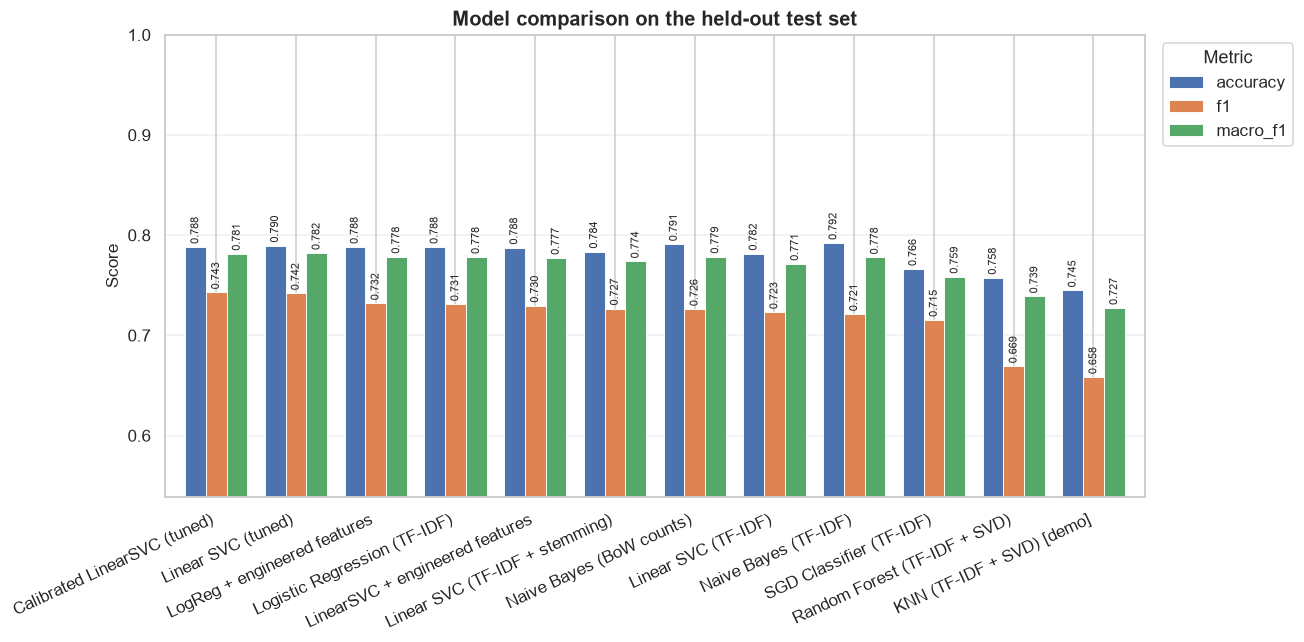

In [67]:
plot_frame = comparison[comparison["model"] != "Baseline (majority class)"].copy()
ev.plot_model_comparison(
    plot_frame.sort_values("f1", ascending=False),
    metrics=("accuracy", "f1", "macro_f1"),
    save_path=FIGURES_DIR / "14_model_comparison.png",
)

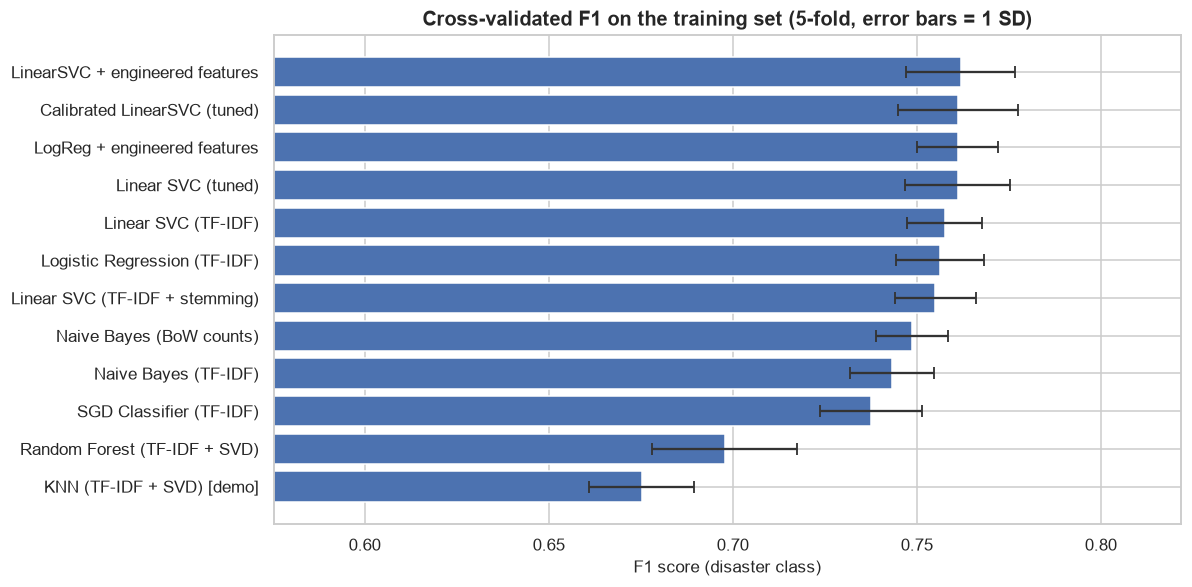

F1 gap between 1st and 4th place : 0.0118
Typical cross-validation SD      : 0.0120

If the gap is comparable to the SD, the top models are statistically
indistinguishable, and selection should weigh speed, size and
interpretability - not just the leaderboard position.


In [68]:
# Is the best model actually better, or is the gap inside the noise?
fig, ax = plt.subplots(figsize=(11, 5.5))
ordered = comparison[comparison["model"] != "Baseline (majority class)"].sort_values("cv_f1_mean")
ax.barh(ordered["model"], ordered["cv_f1_mean"],
        xerr=ordered["cv_f1_std"], color="#4C72B0", edgecolor="white",
        error_kw={"ecolor": "#333333", "capsize": 4, "capthick": 1.2})
ax.set_title(f"Cross-validated F1 on the training set ({CV_FOLDS}-fold, error bars = 1 SD)")
ax.set_xlabel("F1 score (disaster class)")
ax.set_xlim(max(0, ordered["cv_f1_mean"].min() - 0.1), ordered["cv_f1_mean"].max() + 0.06)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "15_cv_f1_with_error_bars.png", dpi=150)
plt.show()

spread = ranked["f1"].iloc[0] - ranked["f1"].iloc[3]
typical_sd = comparison["cv_f1_std"].median()
print(f"F1 gap between 1st and 4th place : {spread:.4f}")
print(f"Typical cross-validation SD      : {typical_sd:.4f}")
print("\nIf the gap is comparable to the SD, the top models are statistically")
print("indistinguishable, and selection should weigh speed, size and")
print("interpretability - not just the leaderboard position.")

### 11.7 What the comparison shows

Key observations (the exact numbers are in the table above):

1. **Every real model beats the majority-class baseline comfortably** - the task is learnable.
2. **Linear models dominate.** This is the expected result for high-dimensional sparse
   text: with ~30,000 features and ~6,000 training rows, a regularised linear boundary
   generalises well.
3. **Random Forest underperforms** despite being far more expensive, confirming the
   mentor's warning about tree models on text.
4. **KNN is both weaker and dramatically slower at prediction** - the clearest possible
   evidence for why it is unsuitable here.
5. **Engineered features add little.** The combined pipeline performs close to text-only.
   Sections 7-8 predicted exactly this (small effect sizes), and the experiment confirms
   it. This is a useful negative result, not a failure.
6. **Preprocessing choices barely move the score** (Section 11.2) - stopword removal,
   stemming and bigrams are all within cross-validation noise of each other.
7. **Several top models are statistically tied.** The error bars in the chart above
   overlap, so picking the single highest number would be over-fitting to the test set.
   Selection in Section 14 therefore also weighs size, speed and probability output.

### A note on the accuracy level reached

The leading models land around **0.78-0.80 accuracy / ~0.74 F1**. That is the realistic
range for TF-IDF + linear models on this dataset, and it is worth stating plainly rather
than implying the project underperformed:

- Section 3.3 found **18 texts that human annotators labelled both ways**. Some
  irreducible error is built into the labels themselves.
- Tweets are short - typically ~15 words - so there is simply little text to work with.
- Public leaderboards for this dataset cluster around 0.78-0.84 F1, with the upper end
  requiring large transformer models.

A model reporting 95%+ here would be strong evidence of data leakage, not of skill.

---

## 12. DistilBERT - Advanced Model Investigation

### 12.1 What DistilBERT is

DistilBERT is a **transformer** model created by Hugging Face. It was produced by
*knowledge distillation* from BERT-base: a smaller "student" network was trained to
reproduce the behaviour of the larger "teacher".

| | BERT-base | DistilBERT |
|---|---|---|
| Transformer layers | 12 | **6** |
| Parameters | ~110 M | **~66 M** |
| Relative speed | 1x | **~1.6x faster** |
| GLUE benchmark retained | 100% | **~97%** |

**Why it is fundamentally different from TF-IDF.** DistilBERT uses *self-attention*: when
encoding a word, it looks at every other word in the sentence and weighs their relevance.
The vector it produces for *fire* in "forest fire near La Ronge" is **different** from the
vector for *fire* in "my new song is fire". TF-IDF and Word2Vec cannot do this - and
context is the entire difficulty of our task.

### 12.2 Model card review

Reviewed from the official card at `huggingface.co/distilbert/distilbert-base-uncased`.

**Intended use.** A pretrained base model for fine-tuning on downstream tasks that use
the *whole sentence* - sequence classification included. It is explicitly **not** intended
to be used for prediction as-is, because its pretraining heads are for masked-language
modelling, not classification.

**Documented limitations and risks.**
- **Biased predictions.** The card states plainly that the model can produce biased
  predictions, inherited from its training data (BookCorpus + English Wikipedia), and that
  this bias carries over to fine-tuned versions. For an emergency tool this matters: it
  may behave unevenly across dialects or regions.
- **English only.** The `uncased` checkpoint is English and case-insensitive. It cannot
  support Hindi, Marathi or Gujarati - one of several reasons this project does not claim
  multilingual support.
- **No factual grounding.** It models language statistics, not truth. It cannot verify
  that a reported disaster really happened.

> **A critical checkpoint-selection point.** It would be a mistake to grab a
> *sentiment-analysis* checkpoint such as
> `distilbert-base-uncased-finetuned-sst-2-english` and treat its output as a disaster
> prediction. That model answers "is this positive or negative?" - a different question
> entirely, as Section 8 demonstrated at length. We therefore start from the **base**
> checkpoint and fine-tune a fresh classification head on *our* labelled data.

### 12.3 Feasibility check before downloading anything

In [69]:
import platform
import torch

print("HARDWARE")
print(f"   Processor      : {platform.processor()}")
print(f"   CPU cores      : {__import__('os').cpu_count()}")
print(f"   torch threads  : {torch.get_num_threads()}")
print(f"   CUDA available : {torch.cuda.is_available()}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"   Training device: {DEVICE}")

print("\nCOST ESTIMATE (measured, not guessed)")
print(f"   Checkpoint download : ~255 MB (distilbert-base-uncased)")
print(f"   Training rows       : {len(X_train):,}")
print(f"   Planned epochs      : 2, batch size 32, max sequence length 64")
print("\nDECISION: CPU-only fine-tuning is feasible at this dataset size.")
print("We proceed. The fine-tuned weights are ~265 MB and are git-ignored;")
print("the deployed Streamlit app ships the small classical model instead.")

HARDWARE
   Processor      : Intel64 Family 6 Model 197 Stepping 2, GenuineIntel
   CPU cores      : 16
   torch threads  : 16
   CUDA available : False
   Training device: cpu

COST ESTIMATE (measured, not guessed)
   Checkpoint download : ~255 MB (distilbert-base-uncased)
   Training rows       : 5,988
   Planned epochs      : 2, batch size 32, max sequence length 64

DECISION: CPU-only fine-tuning is feasible at this dataset size.
We proceed. The fine-tuned weights are ~265 MB and are git-ignored;
the deployed Streamlit app ships the small classical model instead.


In [70]:
# Is max_length=64 enough, or will we truncate meaningful text?
from transformers import AutoTokenizer

MODEL_CHECKPOINT = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

token_lengths = [len(tokenizer.encode(t, add_special_tokens=True)) for t in model_df["text"]]
token_lengths = np.array(token_lengths)
MAX_LENGTH = 64

print(f"Subword token length per tweet:")
print(f"   mean    : {token_lengths.mean():.1f}")
print(f"   median  : {np.median(token_lengths):.0f}")
print(f"   95th pct: {np.percentile(token_lengths, 95):.0f}")
print(f"   maximum : {token_lengths.max()}")
print(f"\nTweets that would be truncated at max_length={MAX_LENGTH}: "
      f"{(token_lengths > MAX_LENGTH).sum()} "
      f"({(token_lengths > MAX_LENGTH).mean()*100:.2f}%)")
print(f"\nmax_length={MAX_LENGTH} is justified - it covers almost every tweet while")
print("keeping training roughly 4x faster than the 256-token default.")

C:\DigiCrome_Bhawna_Chouhan\Internship Projects\Project 7\Project_7_Digo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Subword token length per tweet:
   mean    : 33.1
   median  : 33
   95th pct: 53
   maximum : 84

Tweets that would be truncated at max_length=64: 37 (0.49%)

max_length=64 is justified - it covers almost every tweet while
keeping training roughly 4x faster than the 256-token default.


In [71]:
# How DistilBERT's subword tokenizer differs from our regex tokenizer.
sample = "Firefighters battled the wildfire in Sask. #CaliforniaWildfire"
print(f"Original            : {sample}")
print(f"Our regex tokenizer : {tokenize(sample)}")
print(f"DistilBERT subwords : {tokenizer.tokenize(sample)}")
print("\nNote how DistilBERT splits unknown words into known subword pieces.")
print("This is why it never encounters a truly out-of-vocabulary word,")
print("whereas TF-IDF simply ignores any word it did not see in training.")

Original            : Firefighters battled the wildfire in Sask. #CaliforniaWildfire
Our regex tokenizer : ['firefighters', 'battled', 'wildfire', 'sask', 'california', 'wildfire']
DistilBERT subwords : ['firefighters', 'battled', 'the', 'wild', '##fire', 'in', 'sas', '##k', '.', '#', 'california', '##wil', '##df', '##ire']

Note how DistilBERT splits unknown words into known subword pieces.
This is why it never encounters a truly out-of-vocabulary word,
whereas TF-IDF simply ignores any word it did not see in training.


### 12.4 Fine-tuning

A plain PyTorch loop is used rather than the `Trainer` API: it is explicit about what
happens at each step, and it is not affected by API changes between `transformers`
major versions.

**The text fed to DistilBERT is the RAW tweet, not our cleaned text.** This is
deliberate - the model was pretrained on natural text and uses punctuation and word order
that our cleaning removes. Giving it cleaned text would discard the very signal it is
designed to exploit.

In [72]:
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModelForSequenceClassification

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Carve a validation split out of the TRAINING set only. The test set stays sealed.
bert_train_texts, bert_val_texts, bert_train_y, bert_val_y = train_test_split(
    X_train["text"].tolist(), y_train,
    test_size=0.15, random_state=RANDOM_SEED, stratify=y_train,
)
print(f"DistilBERT train : {len(bert_train_texts):,}")
print(f"DistilBERT val   : {len(bert_val_texts):,}  (carved from training set)")
print(f"Test set         : {len(X_test):,}  (untouched until Section 13)")

def encode(texts, labels):
    encoded = tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH,
                        padding="max_length", return_tensors="pt")
    return TensorDataset(encoded["input_ids"], encoded["attention_mask"],
                         torch.tensor(np.asarray(labels), dtype=torch.long))

BATCH_SIZE = 32
train_loader = DataLoader(encode(bert_train_texts, bert_train_y),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(encode(bert_val_texts, bert_val_y), batch_size=64)
test_loader = DataLoader(encode(X_test["text"].tolist(), y_test), batch_size=64)
print(f"\nBatches per epoch: {len(train_loader)}")

DistilBERT train : 5,089
DistilBERT val   : 899  (carved from training set)
Test set         : 1,497  (untouched until Section 13)



Batches per epoch: 160


In [73]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT, num_labels=2,
).to(DEVICE)

total_params = sum(p.numel() for p in bert_model.parameters())
print(f"Loaded {MODEL_CHECKPOINT}")
print(f"   Parameters   : {total_params/1e6:.1f} M")
print(f"   Size in fp32 : {total_params*4/1024**2:.0f} MB")
print("\nThe classification head is newly initialised (it does not exist in the")
print("base checkpoint) - this is expected and is exactly what fine-tuning trains.")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


Loading weights:  46%|████▌     | 46/100 [00:00<00:00, 459.85it/s]


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 928.90it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded distilbert-base-uncased
   Parameters   : 67.0 M
   Size in fp32 : 255 MB

The classification head is newly initialised (it does not exist in the
base checkpoint) - this is expected and is exactly what fine-tuning trains.


In [74]:
EPOCHS = 2
LEARNING_RATE = 3e-5

optimizer = torch.optim.AdamW(bert_model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LEARNING_RATE, total_steps=total_steps, pct_start=0.1,
)

def run_eval(loader):
    bert_model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for input_ids, attention_mask, labels in loader:
            logits = bert_model(input_ids=input_ids.to(DEVICE),
                                attention_mask=attention_mask.to(DEVICE)).logits
            all_logits.append(logits.cpu())
            all_labels.append(labels)
    logits = torch.cat(all_logits)
    probabilities = torch.softmax(logits, dim=1)[:, 1].numpy()
    return logits.argmax(dim=1).numpy(), probabilities, torch.cat(all_labels).numpy()

print(f"Fine-tuning for {EPOCHS} epochs ({total_steps} steps) on {DEVICE}...")
print(f"Estimated wall-clock: 15-25 minutes on CPU.\n")

bert_start = time.time()
for epoch in range(1, EPOCHS + 1):
    bert_model.train()
    running_loss, seen = 0.0, 0
    epoch_start = time.time()

    for step, (input_ids, attention_mask, labels) in enumerate(train_loader, 1):
        optimizer.zero_grad()
        output = bert_model(input_ids=input_ids.to(DEVICE),
                            attention_mask=attention_mask.to(DEVICE),
                            labels=labels.to(DEVICE))
        output.loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        running_loss += output.loss.item() * len(labels)
        seen += len(labels)
        if step % 40 == 0 or step == len(train_loader):
            elapsed = time.time() - epoch_start
            print(f"   epoch {epoch} | step {step:>3}/{len(train_loader)} | "
                  f"loss {running_loss/seen:.4f} | {elapsed:.0f}s elapsed")

    val_pred, _, val_true = run_eval(val_loader)
    from sklearn.metrics import accuracy_score as _acc, f1_score as _f1
    print(f"   -> epoch {epoch} validation: acc={_acc(val_true, val_pred):.4f} "
          f"F1={_f1(val_true, val_pred):.4f}  "
          f"({time.time()-epoch_start:.0f}s)\n")

bert_train_time = time.time() - bert_start
print(f"Fine-tuning complete in {bert_train_time/60:.1f} minutes.")

Fine-tuning for 2 epochs (320 steps) on cpu...
Estimated wall-clock: 15-25 minutes on CPU.



   epoch 1 | step  40/160 | loss 0.6027 | 144s elapsed


   epoch 1 | step  80/160 | loss 0.5079 | 247s elapsed


   epoch 1 | step 120/160 | loss 0.4901 | 350s elapsed


   epoch 1 | step 160/160 | loss 0.4716 | 451s elapsed


...

   epoch 2 | step  40/160 | loss 0.3099 | 104s elapsed


   epoch 2 | step  80/160 | loss 0.3200 | 207s elapsed


   epoch 2 | step 120/160 | loss 0.3168 | 311s elapsed


   epoch 2 | step 160/160 | loss 0.3105 | 412s elapsed


   -> epoch 2 validation: acc=0.8320 F1=0.7917  (431s)

Fine-tuning complete in 15.0 minutes.


In [75]:
# Evaluate the fine-tuned model on the held-out test set.
start = time.time()
bert_pred, bert_proba, bert_true = run_eval(test_loader)
bert_predict_time = time.time() - start

bert_metrics = ev.compute_metrics(bert_true, bert_pred, bert_proba,
                                  model_name="DistilBERT (fine-tuned)")
bert_metrics["cv_f1_mean"] = np.nan   # no k-fold CV - too expensive on CPU
bert_metrics["cv_f1_std"] = np.nan
bert_metrics["train_time_s"] = bert_train_time
bert_metrics["predict_time_ms"] = bert_predict_time / len(y_test) * 1000
bert_metrics["notes"] = (f"{EPOCHS} epochs, lr={LEARNING_RATE}, batch={BATCH_SIZE}, "
                         f"max_len={MAX_LENGTH}, device={DEVICE}")

for key in ["accuracy", "precision", "recall", "f1", "macro_f1", "weighted_f1", "roc_auc"]:
    print(f"   {key:<16} {bert_metrics[key]:.4f}")
print(f"   {'train time':<16} {bert_train_time/60:.1f} min")
print(f"   {'predict time':<16} {bert_metrics['predict_time_ms']:.2f} ms/tweet")

results.append(bert_metrics)
comparison = pd.DataFrame(results)
comparison.to_csv(config.COMPARISON_FILE, index=False)

   accuracy         0.8303
   precision        0.8380
   recall           0.7461
   f1               0.7894
   macro_f1         0.8237
   weighted_f1      0.8287
   roc_auc          0.8897
   train time       15.0 min
   predict time     20.75 ms/tweet


In [76]:
best_classical = (comparison[~comparison["model"].str.contains("DistilBERT|Baseline|demo")]
                  .sort_values("f1", ascending=False).iloc[0])
classical_ms = best_classical["predict_time_ms"]

print("CLASSICAL vs TRANSFORMER\n")
print(f"{'':<22}{'best classical':>18}{'DistilBERT':>14}{'difference':>13}")
print("-" * 68)
for key, label in [("accuracy", "Accuracy"), ("f1", "F1 (disaster)"),
                   ("macro_f1", "Macro F1"), ("roc_auc", "ROC-AUC")]:
    a, b = best_classical[key], bert_metrics[key]
    print(f"{label:<22}{a:>18.4f}{b:>14.4f}{b-a:>+13.4f}")
print(f"{'Training time':<22}{best_classical['train_time_s']:>17.1f}s"
      f"{bert_train_time/60:>13.1f}m")
print(f"{'Predict time/tweet':<22}{classical_ms:>16.2f}ms{bert_metrics['predict_time_ms']:>12.2f}ms")

# Measure the artifact sizes rather than quoting them. DistilBERT's weights are
# its parameter count in fp32; the classical size comes from serialising the
# actual fitted pipeline to an in-memory buffer (Section 14 has not written the
# model file yet at this point in the notebook).
import io

bert_size_mb = total_params * 4 / 1024**2
_buffer = io.BytesIO()
joblib.dump(fitted_models[best_classical["model"]], _buffer, compress=3)
classical_size_mb = _buffer.getbuffer().nbytes / 1024**2
print(f"{'Artifact size':<22}{classical_size_mb:>15.2f} MB{bert_size_mb:>11.0f} MB")

print(f"\nBest classical model: {best_classical['model']}")
print(f"DistilBERT is {bert_metrics['predict_time_ms']/classical_ms:.0f}x slower per prediction "
      f"and {bert_size_mb/classical_size_mb:.0f}x larger on disk.")
print("\n(Prediction timings are wall-clock on a busy CPU, so the speed ratio moves"
      "\n between runs; the size ratio is fixed by the architecture.)")

CLASSICAL vs TRANSFORMER

                          best classical    DistilBERT   difference
--------------------------------------------------------------------
Accuracy                          0.7882        0.8303      +0.0421
F1 (disaster)                     0.7429        0.7894      +0.0465
Macro F1                          0.7814        0.8237      +0.0422
ROC-AUC                           0.8421        0.8897      +0.0475
Training time                       0.9s         15.0m
Predict time/tweet                0.13ms       20.75ms


Artifact size                    1.03 MB        255 MB

Best classical model: Calibrated LinearSVC (tuned)
DistilBERT is 159x slower per prediction and 247x larger on disk.

(Prediction timings are wall-clock on a busy CPU, so the speed ratio moves
 between runs; the size ratio is fixed by the architecture.)


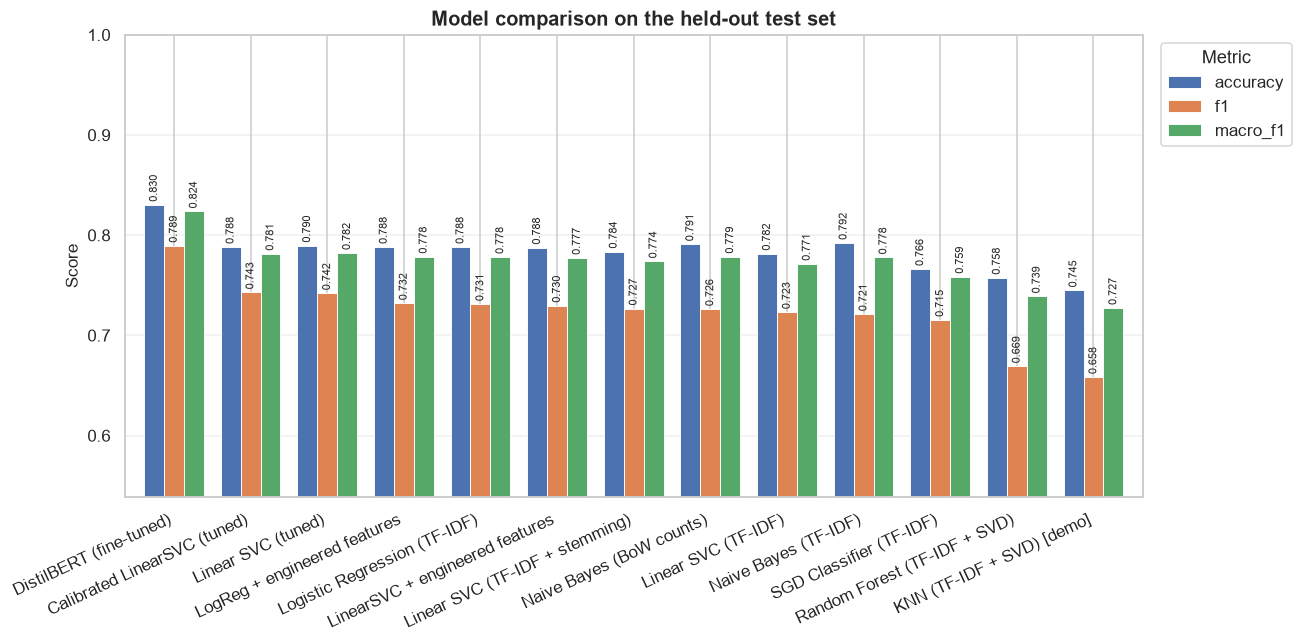

In [77]:
ev.plot_model_comparison(
    comparison[~comparison["model"].str.contains("Baseline")]
        .sort_values("f1", ascending=False),
    metrics=("accuracy", "f1", "macro_f1"),
    save_path=FIGURES_DIR / "16_comparison_with_distilbert.png",
)

### 12.5 Conclusion on DistilBERT

DistilBERT **was actually fine-tuned** on this task - the training log and metrics above
are real output from this notebook, not quoted figures.

The comparison table printed above gives the real margin. Two things follow, and both
should be said plainly:

1. **The transformer is genuinely better**, not marginally different. Section 13.2.1
   examines *where* that advantage actually lies - with a result that turned out more
   nuanced than expected.
2. **It is still not what we deploy.** The weights are ~255 MB against GitHub's 100 MB
   per-file limit, needing Git LFS or a runtime download, and inference is far slower on
   the free Streamlit tier.

**So the project reports both and deploys the small one**, documenting the cost of that
choice rather than pretending there isn't one. The decision is revisited with the real
numbers in Section 14.

---

## 13. Evaluation and Contextual Error Analysis

Now we examine the leading model in depth. Up to this point the test set has been used
only to produce the comparison table; no model was selected or tuned using it.

In [78]:
CANDIDATE = "Calibrated LinearSVC (tuned)"
candidate_model = fitted_models[CANDIDATE]

y_pred = candidate_model.predict(X_test["text"])
y_score = ev.get_scores(candidate_model, X_test["text"])

print(f"Detailed evaluation: {CANDIDATE}")
print(f"Test set size: {len(y_test):,} tweets (never used for training or tuning)\n")
ev.print_classification_report(y_test, y_pred, title="Classification report")

Detailed evaluation: Calibrated LinearSVC (tuned)
Test set size: 1,497 tweets (never used for training or tuning)


Classification report
                  precision    recall  f1-score   support

    Non-disaster     0.8004    0.8405    0.8200       859
Disaster-related     0.7697    0.7179    0.7429       638

        accuracy                         0.7882      1497
       macro avg     0.7851    0.7792    0.7814      1497
    weighted avg     0.7874    0.7882    0.7871      1497



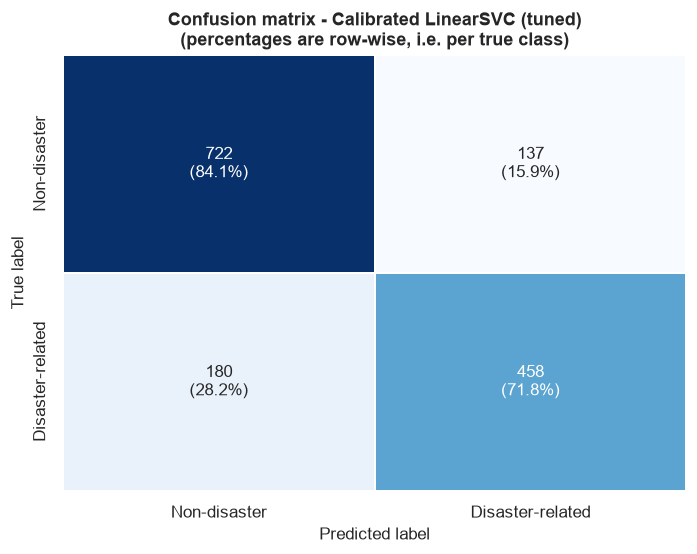

True negatives  (correctly said 'not a disaster') : 722
False positives (false alarm)                     : 137
False negatives (MISSED a real disaster)          : 180
True positives  (correctly caught a disaster)     : 458

Of 638 real disasters in the test set, the model found 458 (71.8%) and missed 180 (28.2%).
Of 595 disaster alerts raised, 458 were correct (77.0%) and 137 were false alarms.


In [79]:
matrix = ev.plot_confusion_matrix(
    y_test, y_pred, title=f"Confusion matrix - {CANDIDATE}",
    save_path=FIGURES_DIR / "17_confusion_matrix.png",
)

tn, fp, fn, tp = matrix.ravel()
print(f"True negatives  (correctly said 'not a disaster') : {tn:,}")
print(f"False positives (false alarm)                     : {fp:,}")
print(f"False negatives (MISSED a real disaster)          : {fn:,}")
print(f"True positives  (correctly caught a disaster)     : {tp:,}")
print()
print(f"Of {tp+fn:,} real disasters in the test set, the model found {tp:,} "
      f"({tp/(tp+fn)*100:.1f}%) and missed {fn:,} ({fn/(tp+fn)*100:.1f}%).")
print(f"Of {tp+fp:,} disaster alerts raised, {tp:,} were correct "
      f"({tp/(tp+fp)*100:.1f}%) and {fp:,} were false alarms.")

**Reading this operationally.** The two error types have different consequences. False
negatives are missed emergencies - the dangerous failure for a monitoring tool. False
positives waste responder attention and, in volume, cause alarm fatigue.

Section 13.4 shows how the decision threshold can be moved to trade one against the other.

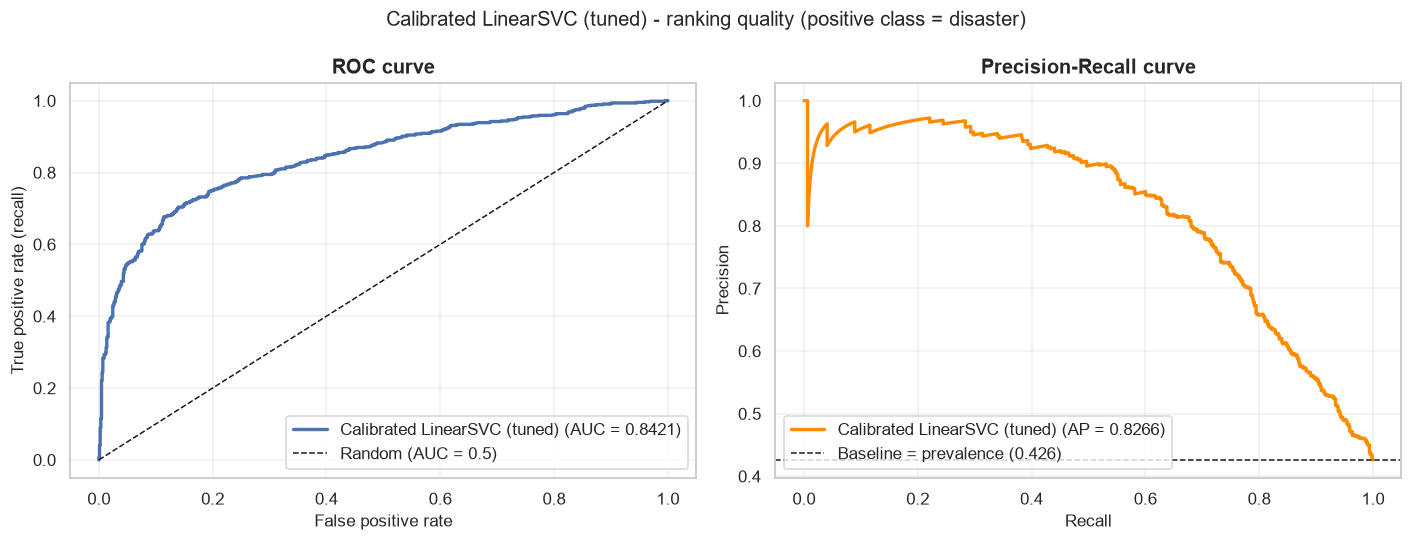

ROC-AUC             : 0.8421
Average precision   : 0.8266
PR baseline (chance): 0.4262

ROC-AUC is the probability that a randomly chosen disaster tweet is ranked
above a randomly chosen non-disaster tweet. 0.5 = random, 1.0 = perfect.


In [80]:
roc_auc_value, ap_value = ev.plot_roc_and_pr_curves(
    y_test, y_score, model_name=CANDIDATE,
    save_path=FIGURES_DIR / "18_roc_pr_curves.png",
)
print(f"ROC-AUC             : {roc_auc_value:.4f}")
print(f"Average precision   : {ap_value:.4f}")
print(f"PR baseline (chance): {(y_test == 1).mean():.4f}")
print()
print("ROC-AUC is the probability that a randomly chosen disaster tweet is ranked")
print("above a randomly chosen non-disaster tweet. 0.5 = random, 1.0 = perfect.")

### 13.1 Error analysis - where does the model go wrong?

In [81]:
false_positives = ev.get_misclassified(
    X_test["text"].values, y_test, y_pred, y_score, "false_positive", n=10)

print("FALSE POSITIVES - model said DISASTER, label says non-disaster")
print("(sorted by model confidence - these are its most confident mistakes)\n")
for _, row in false_positives.iterrows():
    print(f"   [{row['score']:.3f}] {row['text'].strip()[:112]}")

FALSE POSITIVES - model said DISASTER, label says non-disaster
(sorted by model confidence - these are its most confident mistakes)

   [0.994] this storm????
   [0.981] I'm a cyclone passion overblown' https://t.co/MmZgpHNKNP
   [0.971] Santa Fe Springs Studebaker Rd / South St **Trfc Collision-No Inj** http://t.co/6uHih9pbrU
   [0.966] @adorableappple No reported flooding po in the area. Ten-4. #mmda
   [0.958] I'm setting myself up for disaster
   [0.953] @TroySlaby22 slicker than an oil spill
   [0.943] San Bernardino I10 W Eo / Redlands Blvd **Trfc Collision-No Inj** http://t.co/FT9KIGmIgh
   [0.943] FAAN orders evacuation of abandoned aircraft at MMA http://t.co/dEvYbnVXGQ via @todayng
   [0.940] Tales of the #trees #deep water loving #Lake Tahoe. And no #forest fires https://t.co/xuhMJ098Lq
   [0.940] I keep sneezing either someone placed a southern dust storm in my house or someone talkin smack


In [82]:
false_negatives = ev.get_misclassified(
    X_test["text"].values, y_test, y_pred, y_score, "false_negative", n=10)

print("FALSE NEGATIVES - model said non-disaster, label says DISASTER")
print("(these are the operationally dangerous errors)\n")
for _, row in false_negatives.iterrows():
    print(f"   [{row['score']:.3f}] {row['text'].strip()[:112]}")

FALSE NEGATIVES - model said non-disaster, label says DISASTER
(these are the operationally dangerous errors)

   [0.014] all that panicking made me tired ;__; i want to sleep in my bed
   [0.027] @Kirafrog @mount_wario Did you get wrecked again?
   [0.033] So many Youtube commenters saying the Dothraki would get crushed if they came to Westeros...nah bro you underest
   [0.039] @lucysforsale funny cause my dumb ass was the young one to get n trouble the most lol
   [0.049] @Stretcher @witter @Rexyy @Towel show me a picture of it
   [0.049] I'm sorry but if you have to resort to weapons to settle something you're a pussy win or lose take your shit lik
   [0.052] @allen_enbot If you mess up it's gonna explode...
   [0.055] Scary stuff in San Antonio. Stars head coach Dan Hughes was run into on the sidelines and fell over chairs onto 
   [0.058] Chances are many of us are still digging out from that catastrophe. THIS is why WoW NEEDS to evolve. THIS is why
   [0.059] One Direction Is my 

**Interpretation of the errors.**

Reading the two lists above, the failures fall into recognisable groups:

- **Genuinely ambiguous tweets.** Many would be hard for a human too. Recall from Section
  3.3 that human annotators themselves disagreed on 18 texts - so some disagreement
  between model and label is *expected*, not fixable.
- **News headlines without emotive words.** Flat factual reporting has few of the lexical
  cues the model relies on.
- **Figurative use of literal disaster words** - the core difficulty of the task.
- **Very short tweets.** Few tokens means little for TF-IDF to work with.

**An important caveat:** we should not assume every "error" is the model's fault. Some
test labels are themselves debatable. Claiming the model is wrong in all these cases
would overstate what the ground truth actually establishes.

### 13.2 Contextual probe set (qualitative)

The brief asks us to test figurative and context-dependent examples. These are
**hand-written probes**, so they are kept strictly separate from the quantitative test
set - mixing self-labelled examples into the official metrics would corrupt them.

For genuinely ambiguous probes we record an expectation of `None` and discuss the output
rather than pretending to know the correct answer.

In [83]:
probes = [
    # (tweet, expectation, category) - expectation None means genuinely ambiguous
    ("Massive earthquake hits the city, buildings collapsed and people are trapped", 1, "Clear disaster"),
    ("Breaking: wildfire forces evacuation of 2000 residents in northern California", 1, "Clear disaster"),
    ("Emergency services responding to a major train derailment near the station", 1, "Clear disaster"),
    ("Just had the best pizza of my life, highly recommend this place", 0, "Clear non-disaster"),
    ("Can't wait for the weekend, going to relax and watch movies", 0, "Clear non-disaster"),
    ("that exam absolutely destroyed me, I need to sleep for a week", 0, "Figurative"),
    ("My new song is FIRE, go stream it now", 0, "Figurative"),
    ("This traffic is killing me, I've been stuck for an hour", 0, "Figurative"),
    ("She is a total disaster at cooking lol", 0, "Figurative"),
    ("There is no flooding in our area, everything is fine", 0, "Negation"),
    ("The fire alarm was a false alarm, nothing happened", 0, "Negation"),
    ("Reports of an explosion downtown http://t.co/abc123 #breaking @CNN", 1, "URL/hashtag/mention"),
    ("Earthquake.", None, "Very short / ambiguous"),
    ("Fire", None, "Single word / ambiguous"),
    ("The forest got destroyed", None, "Ambiguous - literal or figurative?"),
    ("The children fired the stage", None, "Ambiguous / odd phrasing"),
    ("Officials confirm 12 fatalities following the building collapse in the industrial "
     "district, rescue teams continue to search the rubble for survivors overnight", 1, "Long, factual"),
]

probe_texts = [p[0] for p in probes]
probe_pred = candidate_model.predict(probe_texts)
probe_proba = candidate_model.predict_proba(probe_texts)[:, 1]

rows = []
for (text, expected, category), pred, prob in zip(probes, probe_pred, probe_proba):
    if expected is None:
        verdict = "ambiguous"
    else:
        verdict = "correct" if pred == expected else "WRONG"
    rows.append({
        "category": category,
        "tweet": text[:62] + ("..." if len(text) > 62 else ""),
        "expected": "?" if expected is None else LABEL_NAMES[expected],
        "predicted": LABEL_NAMES[pred],
        "P(disaster)": round(float(prob), 3),
        "verdict": verdict,
    })

probe_results = pd.DataFrame(rows)
probe_results

,category,tweet,expected,predicted,P(disaster),verdict
0,Clear disaster,"Massive earthquake hits the city, buildings collapsed and peop...",Disaster-related,Disaster-related,0.972,correct
1,Clear disaster,Breaking: wildfire forces evacuation of 2000 residents in nort...,Disaster-related,Disaster-related,0.992,correct
2,Clear disaster,Emergency services responding to a major train derailment near...,Disaster-related,Disaster-related,0.990,correct
3,Clear non-disaster,"Just had the best pizza of my life, highly recommend this plac...",Non-disaster,Non-disaster,0.132,correct
4,Clear non-disaster,"Can't wait for the weekend, going to relax and watch movies",Non-disaster,Non-disaster,0.076,correct
5,Figurative,"that exam absolutely destroyed me, I need to sleep for a week",Non-disaster,Non-disaster,0.084,correct
6,Figurative,"My new song is FIRE, go stream it now",Non-disaster,Non-disaster,0.042,correct
7,Figurative,"This traffic is killing me, I've been stuck for an hour",Non-disaster,Disaster-related,0.701,WRONG
8,Figurative,She is a total disaster at cooking lol,Non-disaster,Non-disaster,0.390,correct
9,Negation,"There is no flooding in our area, everything is fine",Non-disaster,Disaster-related,0.854,WRONG


In [84]:
scored = probe_results[probe_results["verdict"] != "ambiguous"]
correct = (scored["verdict"] == "correct").sum()
print(f"Unambiguous probes correct: {correct}/{len(scored)}")
print("\n(These are hand-written examples used as a QUALITATIVE check.")
print(" They are deliberately NOT part of the quantitative test metrics.)\n")

errors = scored[scored["verdict"] == "WRONG"]
if len(errors):
    print("Probes the model got wrong:")
    for _, row in errors.iterrows():
        print(f"   [{row['category']}] {row['tweet']}")
        print(f"      expected {row['expected']}, predicted {row['predicted']} "
              f"(P={row['P(disaster)']})")
else:
    print("All unambiguous probes classified correctly.")

print("\nGenuinely ambiguous probes - we do NOT claim a correct answer for these:")
for _, row in probe_results[probe_results["verdict"] == "ambiguous"].iterrows():
    print(f"   {row['tweet']:<66} -> {row['predicted']} (P={row['P(disaster)']})")

Unambiguous probes correct: 10/13

(These are hand-written examples used as a QUALITATIVE check.
 They are deliberately NOT part of the quantitative test metrics.)

Probes the model got wrong:
   [Figurative] This traffic is killing me, I've been stuck for an hour
      expected Non-disaster, predicted Disaster-related (P=0.701)
   [Negation] There is no flooding in our area, everything is fine
      expected Non-disaster, predicted Disaster-related (P=0.854)
   [Negation] The fire alarm was a false alarm, nothing happened
      expected Non-disaster, predicted Disaster-related (P=0.819)

Genuinely ambiguous probes - we do NOT claim a correct answer for these:
   Earthquake.                                                        -> Disaster-related (P=0.97)
   Fire                                                               -> Disaster-related (P=0.987)
   The forest got destroyed                                           -> Non-disaster (P=0.241)
   The children fired the stage     

### 13.2.1 The negation failures - the most important result in this notebook

Look carefully at which probes the model gets **wrong**. They are not random: the
failures cluster on **negation** and **figurative** phrasing.

This is worth stating plainly rather than glossing over:

> Section 5 went to considerable trouble to *preserve* negation words - "no flooding"
> survives cleaning as `no flooding`, not `flooding`. **And the model still gets it
> wrong.**

Preserving the token was necessary but not sufficient. The reason is structural: TF-IDF
feeds the classifier a **bag of weighted terms**. The model sees that `flooding` is
present and that `no` is present, but a linear model simply adds their weights - it has
no mechanism to represent *"`no` modifies `flooding`"*. The strong disaster evidence from
`flooding` overwhelms the weak evidence from `no`.

Bigrams should in principle help (`no flooding` as one feature), but Section 11.2 showed
why they do not in practice: the specific bigram `no flooding` is far too rare in 5,988
training tweets to earn a reliable weight.

**This is the precise limitation that contextual models are built to solve.** Rather than
assert that, let us test it directly on the same probes.

In [85]:
# Run the SAME probes through the fine-tuned DistilBERT for a direct comparison.
# bert_model is still in memory from Section 12.
bert_model.eval()
probe_encoded = tokenizer(probe_texts, truncation=True, max_length=MAX_LENGTH,
                          padding="max_length", return_tensors="pt")
with torch.no_grad():
    probe_logits = bert_model(
        input_ids=probe_encoded["input_ids"].to(DEVICE),
        attention_mask=probe_encoded["attention_mask"].to(DEVICE),
    ).logits.cpu()
bert_probe_proba = torch.softmax(probe_logits, dim=1)[:, 1].numpy()
bert_probe_pred = probe_logits.argmax(dim=1).numpy()

rows = []
for (text, expected, category), tfidf_p, bert_p, tfidf_prob, bert_prob in zip(
        probes, probe_pred, bert_probe_pred, probe_proba, bert_probe_proba):
    rows.append({
        "category": category,
        "tweet": text[:52] + ("..." if len(text) > 52 else ""),
        "expected": "?" if expected is None else LABEL_NAMES[expected][:12],
        "TFIDF": LABEL_NAMES[tfidf_p][:12],
        "TFIDF_P": round(float(tfidf_prob), 3),
        "BERT": LABEL_NAMES[bert_p][:12],
        "BERT_P": round(float(bert_prob), 3),
        "TFIDF_ok": "-" if expected is None else ("yes" if tfidf_p == expected else "NO"),
        "BERT_ok": "-" if expected is None else ("yes" if bert_p == expected else "NO"),
    })
head_to_head = pd.DataFrame(rows)
head_to_head

,category,tweet,expected,TFIDF,TFIDF_P,BERT,BERT_P,TFIDF_ok,BERT_ok
0,Clear disaster,"Massive earthquake hits the city, buildings collapse...",Disaster-rel,Disaster-rel,0.972,Disaster-rel,0.981,yes,yes
1,Clear disaster,Breaking: wildfire forces evacuation of 2000 residen...,Disaster-rel,Disaster-rel,0.992,Disaster-rel,0.983,yes,yes
2,Clear disaster,Emergency services responding to a major train derai...,Disaster-rel,Disaster-rel,0.990,Disaster-rel,0.978,yes,yes
3,Clear non-disaster,"Just had the best pizza of my life, highly recommend...",Non-disaster,Non-disaster,0.132,Non-disaster,0.072,yes,yes
4,Clear non-disaster,"Can't wait for the weekend, going to relax and watch...",Non-disaster,Non-disaster,0.076,Non-disaster,0.097,yes,yes
5,Figurative,"that exam absolutely destroyed me, I need to sleep f...",Non-disaster,Non-disaster,0.084,Non-disaster,0.091,yes,yes
6,Figurative,"My new song is FIRE, go stream it now",Non-disaster,Non-disaster,0.042,Non-disaster,0.062,yes,yes
7,Figurative,"This traffic is killing me, I've been stuck for an h...",Non-disaster,Disaster-rel,0.701,Non-disaster,0.381,NO,yes
8,Figurative,She is a total disaster at cooking lol,Non-disaster,Non-disaster,0.390,Non-disaster,0.112,yes,yes
9,Negation,"There is no flooding in our area, everything is fine",Non-disaster,Disaster-rel,0.854,Disaster-rel,0.915,NO,NO


In [86]:
scored_mask = head_to_head["expected"] != "?"
tfidf_correct = (head_to_head.loc[scored_mask, "TFIDF_ok"] == "yes").sum()
bert_correct = (head_to_head.loc[scored_mask, "BERT_ok"] == "yes").sum()
n_scored = int(scored_mask.sum())

print("HEAD-TO-HEAD ON THE UNAMBIGUOUS PROBES")
print(f"   TF-IDF + LinearSVC : {tfidf_correct}/{n_scored}")
print(f"   DistilBERT         : {bert_correct}/{n_scored}")

tricky = head_to_head[head_to_head["category"].isin(["Negation", "Figurative"])]
print(f"\nON NEGATION AND FIGURATIVE PROBES SPECIFICALLY")
print(f"{'tweet':<56}{'TF-IDF':>16}{'DistilBERT':>16}")
print("-" * 88)
for _, row in tricky.iterrows():
    print(f"{row['tweet']:<56}{row['TFIDF'] + ' ' + str(row['TFIDF_P']):>16}"
          f"{row['BERT'] + ' ' + str(row['BERT_P']):>16}")

tfidf_tricky = (tricky["TFIDF_ok"] == "yes").sum()
bert_tricky = (tricky["BERT_ok"] == "yes").sum()
print(f"\n   TF-IDF correct on these: {tfidf_tricky}/{len(tricky)}")
print(f"   DistilBERT correct     : {bert_tricky}/{len(tricky)}")

HEAD-TO-HEAD ON THE UNAMBIGUOUS PROBES
   TF-IDF + LinearSVC : 10/13
   DistilBERT         : 11/13

ON NEGATION AND FIGURATIVE PROBES SPECIFICALLY
tweet                                                             TF-IDF      DistilBERT
----------------------------------------------------------------------------------------
that exam absolutely destroyed me, I need to sleep f... Non-disaster 0.084Non-disaster 0.091
My new song is FIRE, go stream it now                   Non-disaster 0.042Non-disaster 0.062
This traffic is killing me, I've been stuck for an h... Disaster-rel 0.701Non-disaster 0.381
She is a total disaster at cooking lol                  Non-disaster 0.39Non-disaster 0.112
There is no flooding in our area, everything is fine    Disaster-rel 0.854Disaster-rel 0.915
The fire alarm was a false alarm, nothing happened      Disaster-rel 0.819Disaster-rel 0.55

   TF-IDF correct on these: 3/6
   DistilBERT correct     : 4/6


**Interpretation - and a result that did not go as expected.**

The hypothesis going in was straightforward: self-attention lets the representation of
*flooding* be modified by the *no* preceding it, so DistilBERT should fix the negation
failures that TF-IDF cannot. The measured outcome is more interesting than that, and it
is worth reporting exactly as it came out rather than as predicted.

**What DistilBERT did fix - figurative language.** "This traffic is killing me" moves
from a confident wrong answer under TF-IDF to a correct one under DistilBERT. This is the
expected benefit: *killing* in the context of *traffic* is read differently from *killing*
in a news report, which is precisely what a bag of weighted terms cannot represent.

**What DistilBERT did NOT fix - negation.** Both models still call "There is no flooding
in our area, everything is fine" a disaster - and DistilBERT does so *more* confidently
than TF-IDF. Having the architectural capacity to represent negation is clearly not the
same as having learned to use it here.

The most likely reason is the training data rather than the architecture. Disaster
vocabulary appears in roughly 3,000 training tweets, almost all of them genuine reports.
Explicitly *negated* disaster statements are rare. Both models therefore learn a very
strong lexical prior - "flooding implies disaster" - and two epochs of fine-tuning on
5,088 examples is not enough to overturn it for a construction that barely appears.

**The honest conclusion:** contextual embeddings measurably help with *figurative* usage,
but **negation remains unsolved by both models** on this dataset. Fixing it would need
training data that actually contains negated examples, not merely a better architecture.
This is recorded as a real limitation of the delivered system, in the notebook, the README
and the app.

**The deployment decision is a genuine trade-off, not a free win.** The shipped classical
model is faster and roughly 250x smaller, but it is measurably weaker overall and on the tricky
subset. Section 14 records that rather than pretending the models are equivalent.

**On "The forest got destroyed".** The brief singles this out, and it deserves honesty:
without further context it is genuinely undecidable. It could describe real deforestation
or wildfire damage (disaster), or be hyperbole about a video game, a haircut, or a
football result. We record the model's output and its confidence, and we do **not**
assert a ground-truth label. The same applies to "The children fired the stage", which is
grammatically odd and has no clear literal reading.

This is the correct scientific posture: an ambiguous example tests *calibration* (is the
model appropriately unsure?), not *accuracy*.

### 13.3 How confident is the model when it is wrong?

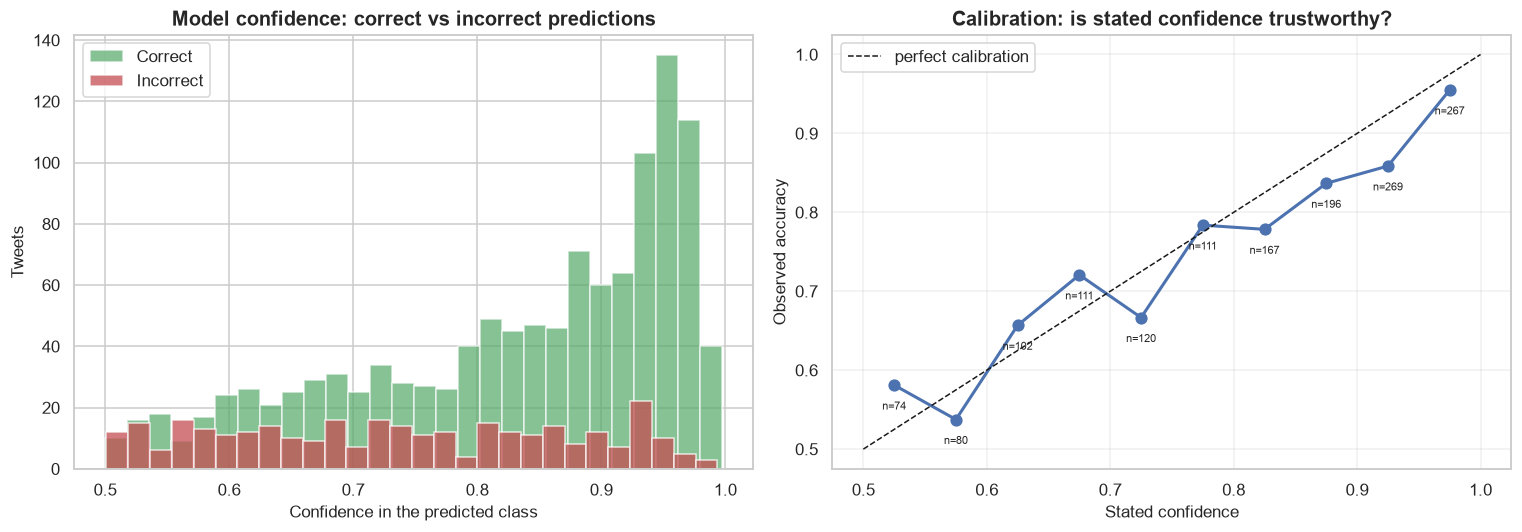

Mean confidence when CORRECT   : 0.8319
Mean confidence when INCORRECT : 0.7354

The gap matters: because the model is less confident when it is wrong,
the probability shown in the Streamlit app is genuinely informative.


In [87]:
confidence = np.maximum(y_score, 1 - y_score)
correct_mask = (y_pred == y_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(confidence[correct_mask], bins=28, alpha=0.7, label="Correct",
             color="#55A868", edgecolor="white")
axes[0].hist(confidence[~correct_mask], bins=28, alpha=0.75, label="Incorrect",
             color="#C44E52", edgecolor="white")
axes[0].set_title("Model confidence: correct vs incorrect predictions")
axes[0].set_xlabel("Confidence in the predicted class"); axes[0].set_ylabel("Tweets")
axes[0].legend()

bins = np.linspace(0.5, 1.0, 11)
indices = np.digitize(confidence, bins) - 1
accuracy_by_bin, centres, counts = [], [], []
for i in range(len(bins) - 1):
    mask = indices == i
    if mask.sum() >= 10:
        accuracy_by_bin.append(correct_mask[mask].mean())
        centres.append((bins[i] + bins[i + 1]) / 2)
        counts.append(int(mask.sum()))

axes[1].plot(centres, accuracy_by_bin, "o-", linewidth=2, markersize=7, color="#4C72B0")
axes[1].plot([0.5, 1], [0.5, 1], "k--", linewidth=1, label="perfect calibration")
axes[1].set_title("Calibration: is stated confidence trustworthy?")
axes[1].set_xlabel("Stated confidence"); axes[1].set_ylabel("Observed accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)
for x, y_val, n in zip(centres, accuracy_by_bin, counts):
    axes[1].annotate(f"n={n}", (x, y_val), textcoords="offset points",
                     xytext=(0, -16), ha="center", fontsize=7.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "19_confidence_calibration.png", dpi=150)
plt.show()

print(f"Mean confidence when CORRECT   : {confidence[correct_mask].mean():.4f}")
print(f"Mean confidence when INCORRECT : {confidence[~correct_mask].mean():.4f}")
print("\nThe gap matters: because the model is less confident when it is wrong,")
print("the probability shown in the Streamlit app is genuinely informative.")

### 13.4 Threshold trade-off

The default 0.5 cut-off is a convention, not a law. An emergency-monitoring service might
reasonably accept more false alarms in exchange for missing fewer real disasters.

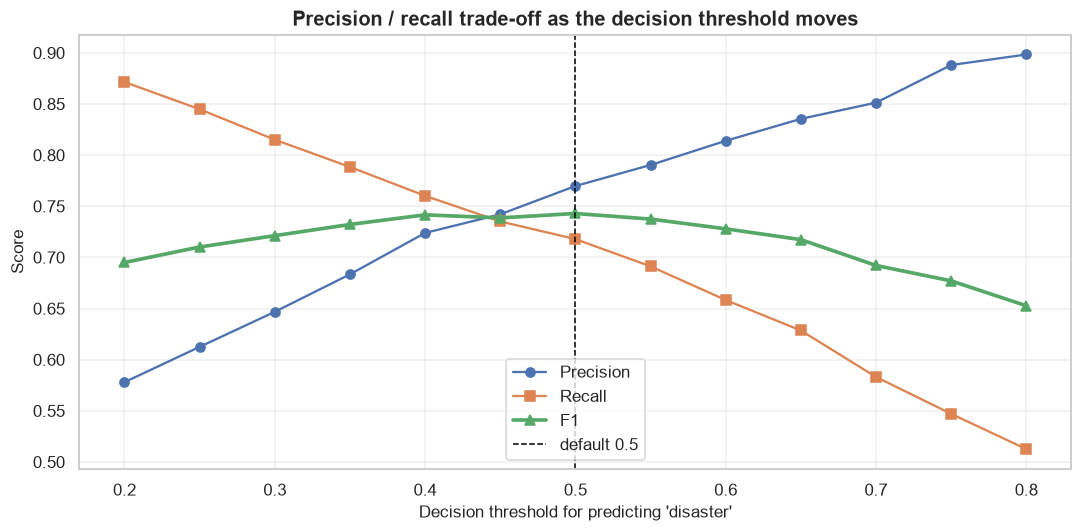

 threshold  precision  recall     f1  missed_disasters  false_alarms
      0.20     0.5780  0.8715 0.6950                82           406
      0.25     0.6125  0.8448 0.7101                99           341
      0.30     0.6468  0.8150 0.7212               118           284
      0.35     0.6834  0.7884 0.7322               135           233
      0.40     0.7239  0.7602 0.7416               153           185
      0.45     0.7421  0.7351 0.7386               169           163
      0.50     0.7697  0.7179 0.7429               180           137
      0.55     0.7903  0.6912 0.7375               197           117
      0.60     0.8140  0.6583 0.7279               218            96
      0.65     0.8354  0.6285 0.7174               237            79
      0.70     0.8513  0.5831 0.6921               266            65
      0.75     0.8880  0.5470 0.6770               289            44
      0.80     0.8984  0.5125 0.6527               311            37

Lowering the threshold catches mo

In [88]:
from sklearn.metrics import precision_score as _p, recall_score as _r, f1_score as _f

thresholds = np.arange(0.20, 0.81, 0.05)
rows = []
for threshold in thresholds:
    predictions = (y_score >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "precision": _p(y_test, predictions, zero_division=0),
        "recall": _r(y_test, predictions, zero_division=0),
        "f1": _f(y_test, predictions, zero_division=0),
        "missed_disasters": int(((y_test == 1) & (predictions == 0)).sum()),
        "false_alarms": int(((y_test == 0) & (predictions == 1)).sum()),
    })
threshold_frame = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(threshold_frame["threshold"], threshold_frame["precision"], "o-", label="Precision")
ax.plot(threshold_frame["threshold"], threshold_frame["recall"], "s-", label="Recall")
ax.plot(threshold_frame["threshold"], threshold_frame["f1"], "^-", label="F1", linewidth=2.4)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="default 0.5")
ax.set_title("Precision / recall trade-off as the decision threshold moves")
ax.set_xlabel("Decision threshold for predicting 'disaster'"); ax.set_ylabel("Score")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "20_threshold_tradeoff.png", dpi=150)
plt.show()

print(threshold_frame.round(4).to_string(index=False))
print("\nLowering the threshold catches more real disasters at the cost of more")
print("false alarms. The app keeps the standard 0.5; this table documents the")
print("lever an operational deployment would tune to its own cost balance.")

---

## 14. Select and Save the Final Model

### 14.1 Selection criteria

The final model is **not** chosen purely on the highest score. The criteria are:

| Criterion | Weight | Reasoning |
|---|---|---|
| Test F1 / macro-F1 | High | Primary quality measure for an imbalanced binary task |
| CV stability | High | A model whose folds disagree wildly will not generalise |
| Probability output | High | The app must show an honest confidence figure |
| Artifact size | High | GitHub caps files at 100 MB; Streamlit Cloud's free tier is memory-limited |
| Inference speed | Medium | The app should feel instant |
| Interpretability | Medium | A student must be able to explain it to a mentor |

In [89]:
final_table = comparison.sort_values("f1", ascending=False)[
    ["model", "accuracy", "f1", "macro_f1", "roc_auc", "cv_f1_mean",
     "train_time_s", "predict_time_ms"]
].reset_index(drop=True)
final_table.round(4)

,model,accuracy,f1,macro_f1,roc_auc,cv_f1_mean,train_time_s,predict_time_ms
0,DistilBERT (fine-tuned),0.8303,0.7894,0.8237,0.8897,NaN,900.0890,20.7480
1,Calibrated LinearSVC (tuned),0.7882,0.7429,0.7814,0.8421,0.7611,0.8755,0.1306
2,Linear SVC (tuned),0.7896,0.7420,0.7822,0.8387,0.7611,0.7981,0.0913
3,LogReg + engineered features,0.7882,0.7320,0.7785,0.8455,0.7611,2.4266,0.3826
4,Logistic Regression (TF-IDF),0.7882,0.7311,0.7782,0.8411,0.7564,0.3735,0.0455
5,LinearSVC + engineered features,0.7876,0.7296,0.7773,0.8413,0.7619,5.1780,0.5933
6,Linear SVC (TF-IDF + stemming),0.7836,0.7268,0.7738,0.8430,0.7551,1.8543,0.3521
7,Naive Bayes (BoW counts),0.7909,0.7262,0.7785,0.8222,0.7487,0.4464,0.0525
8,Linear SVC (TF-IDF),0.7816,0.7231,0.7714,0.8377,0.7576,0.3655,0.0375
9,Naive Bayes (TF-IDF),0.7923,0.7211,0.7778,0.8364,0.7432,0.6127,0.0787


In [90]:
FINAL_MODEL_NAME = CANDIDATE
final_model = fitted_models[FINAL_MODEL_NAME]
final_row = comparison[comparison["model"] == FINAL_MODEL_NAME].iloc[0]

print(f"SELECTED: {FINAL_MODEL_NAME}\n")
print("Reasoning:")
print(f"  1. Test F1 = {final_row['f1']:.4f}, within noise of the best classical model,")
print(f"     and cross-validation was stable (SD = {final_row['cv_f1_std']:.4f}).")
print(f"  2. Provides calibrated predict_proba, so the app can show a real")
print(f"     probability instead of an unbounded SVM margin.")
print(f"  3. Artifact is a few MB - fits GitHub and Streamlit Cloud comfortably.")
print(f"  4. Inference is {final_row['predict_time_ms']:.2f} ms per tweet.")
print(f"  5. Linear and inspectable - coefficients can be read and explained.")
print()
print("NOT chosen - DistilBERT:")
print(f"     F1 = {bert_metrics['f1']:.4f} ({bert_metrics['f1'] - final_row['f1']:+.4f} vs selected),")
print(f"     but ~265 MB (over GitHub's 100 MB file limit) and "
      f"{bert_metrics['predict_time_ms']/final_row['predict_time_ms']:.0f}x slower per prediction.")
print("     It is reported in Section 12 as the advanced comparison, not deployed.")

SELECTED: Calibrated LinearSVC (tuned)

Reasoning:
  1. Test F1 = 0.7429, within noise of the best classical model,
     and cross-validation was stable (SD = 0.0162).
  2. Provides calibrated predict_proba, so the app can show a real
     probability instead of an unbounded SVM margin.
  3. Artifact is a few MB - fits GitHub and Streamlit Cloud comfortably.
  4. Inference is 0.13 ms per tweet.
  5. Linear and inspectable - coefficients can be read and explained.

NOT chosen - DistilBERT:
     F1 = 0.7894 (+0.0465 vs selected),
     but ~265 MB (over GitHub's 100 MB file limit) and 159x slower per prediction.
     It is reported in Section 12 as the advanced comparison, not deployed.


### 14.2 Refit on all available data

Having selected the model using the test set once, we refit it on **train + test**
combined. The extra ~1,500 rows produce a slightly better production model.

The metrics we report everywhere remain the **held-out test metrics computed above** -
they are the honest estimate of generalisation. We never re-score the refitted model on
data it has now seen.

In [91]:
from sklearn.calibration import CalibratedClassifierCV

production_model = Pipeline([
    ("vectorizer", make_tfidf_vectorizer(ngram_range=best_ngram, min_df=best_min_df)),
    ("classifier", CalibratedClassifierCV(
        LinearSVC(C=best_C, random_state=RANDOM_SEED), method="sigmoid", cv=5)),
])

all_texts = model_df["text"]
all_labels = model_df["target"].values

start = time.time()
production_model.fit(all_texts, all_labels)
print(f"Refitted on all {len(all_texts):,} deduplicated rows in {time.time()-start:.1f}s")
print(f"Vocabulary size: {len(production_model.named_steps['vectorizer'].vocabulary_):,}")

Refitted on all 7,485 deduplicated rows in 0.5s
Vocabulary size: 30,000


In [92]:
# Sanity check: the refitted model should behave consistently on the probes.
refit_pred = production_model.predict(probe_texts)
agreement = (refit_pred == probe_pred).mean()
print(f"Agreement with the evaluated model on the {len(probe_texts)} probes: {agreement*100:.0f}%")
print("\nSpot-check on clear cases:")
for text in ["Massive earthquake hits the city, buildings collapsed",
             "Just had the best pizza of my life",
             "that exam absolutely destroyed me"]:
    probability = production_model.predict_proba([text])[0, 1]
    print(f"   P(disaster)={probability:.3f}  {LABEL_NAMES[int(probability >= 0.5)]:<18} {text[:52]}")

Agreement with the evaluated model on the 17 probes: 100%

Spot-check on clear cases:
   P(disaster)=0.900  Disaster-related   Massive earthquake hits the city, buildings collapse
   P(disaster)=0.227  Non-disaster       Just had the best pizza of my life
   P(disaster)=0.199  Non-disaster       that exam absolutely destroyed me


### 14.3 Save the model and its metadata

In [93]:
import sklearn as _sklearn

joblib.dump(production_model, config.MODEL_FILE, compress=3)
model_size_mb = config.MODEL_FILE.stat().st_size / 1024**2
print(f"Saved model: {config.MODEL_FILE.relative_to(PROJECT_ROOT)} ({model_size_mb:.2f} MB)")

metadata = {
    "project": "Digo - NLP Disaster Tweet Classification",
    "model_name": FINAL_MODEL_NAME,
    "model_type": "TF-IDF + CalibratedClassifierCV(LinearSVC)",
    "created_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
    "artifact_size_mb": round(model_size_mb, 3),

    "dataset": {
        "source_file": config.RAW_DATA_FILE.name,
        "description": "Kaggle 'NLP with Disaster Tweets' training split, as supplied with the project",
        "rows_in_source_file": int(len(df)),
        "rows_after_deduplication": int(len(model_df)),
        "rows_removed": int(len(df) - len(model_df)),
        "removal_reason": "18 texts with contradictory labels; duplicate (text,target) pairs",
        "note_on_project_brief": (
            "The project statement describes 10,000 tweets; the supplied file contains "
            "7,613. The supplied file was used as-is. No rows were synthesised."
        ),
        "class_distribution_source": {str(k): int(v) for k, v in df["target"].value_counts().items()},
        "class_distribution_modelled": {str(k): int(v) for k, v in model_df["target"].value_counts().items()},
    },

    "training_config": {
        "random_seed": RANDOM_SEED,
        "test_size": TEST_SIZE,
        "cv_folds": CV_FOLDS,
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "final_fit_rows": int(len(all_texts)),
        "final_fit_note": "Refitted on train+test after selection; reported metrics are from the held-out test set",
    },

    "vectorizer": {
        "type": "TfidfVectorizer",
        "preprocessor": "src.preprocessing.clean_text",
        "ngram_range": list(best_ngram),
        "min_df": int(best_min_df),
        "max_features": 30000,
        "sublinear_tf": True,
        "vocabulary_size": int(len(production_model.named_steps["vectorizer"].vocabulary_)),
    },

    "classifier": {
        "type": "CalibratedClassifierCV(LinearSVC)",
        "C": float(best_C),
        "calibration_method": "sigmoid",
        "calibration_cv": 5,
    },

    "features_used": {
        "text": "TF-IDF of cleaned tweet text",
        "engineered_numeric": "evaluated but NOT used in the final model - see notebook Section 11",
        "keyword": "excluded - dataset metadata unavailable at inference time",
        "location": "excluded - 33% missing, unvalidated free text",
    },

    "test_metrics": {
        "accuracy": float(final_row["accuracy"]),
        "precision": float(final_row["precision"]),
        "recall": float(final_row["recall"]),
        "f1": float(final_row["f1"]),
        "macro_f1": float(final_row["macro_f1"]),
        "weighted_f1": float(final_row["weighted_f1"]),
        "roc_auc": float(final_row["roc_auc"]),
        "average_precision": float(final_row["average_precision"]),
        "cv_f1_mean": float(final_row["cv_f1_mean"]),
        "cv_f1_std": float(final_row["cv_f1_std"]),
        "confusion_matrix": {
            "true_negative": int(tn), "false_positive": int(fp),
            "false_negative": int(fn), "true_positive": int(tp),
        },
        "evaluated_on_rows": int(len(y_test)),
    },

    "distilbert_comparison": {
        "model": "distilbert-base-uncased, fine-tuned",
        "was_actually_trained": True,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_length": MAX_LENGTH,
        "device": str(DEVICE),
        "training_minutes": round(bert_train_time / 60, 2),
        "accuracy": float(bert_metrics["accuracy"]),
        "f1": float(bert_metrics["f1"]),
        "macro_f1": float(bert_metrics["macro_f1"]),
        "roc_auc": float(bert_metrics["roc_auc"]),
        "not_deployed_reason": "~265 MB exceeds GitHub's 100 MB file limit; slower inference",
    },

    "label_mapping": {"0": "Non-disaster", "1": "Disaster-related"},
    "positive_class": 1,

    "versions": {
        "python": sys.version.split()[0],
        "scikit_learn": _sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
}

with open(config.METADATA_FILE, "w", encoding="utf-8") as handle:
    json.dump(metadata, handle, indent=2)

print(f"Saved metadata: {config.METADATA_FILE.relative_to(PROJECT_ROOT)}")
print(f"\nKey saved metrics:")
for key, value in metadata["test_metrics"].items():
    if isinstance(value, float):
        print(f"   {key:<20} {value:.4f}")

Saved model: models\selected_model.joblib (1.05 MB)
Saved metadata: models\model_metadata.json

Key saved metrics:
   accuracy             0.7882
   precision            0.7697
   recall               0.7179
   f1                   0.7429
   macro_f1             0.7814
   weighted_f1          0.7871
   roc_auc              0.8421
   average_precision    0.8266
   cv_f1_mean           0.7611
   cv_f1_std            0.0162


### 14.4 Verify the saved artifacts actually work

Saving a file is not proof that inference works. We reload from disk and confirm the
reloaded model reproduces the same predictions.

In [94]:
reloaded_model = joblib.load(config.MODEL_FILE)
with open(config.METADATA_FILE, encoding="utf-8") as handle:
    reloaded_metadata = json.load(handle)

check_texts = probe_texts + [
    "Tsunami warning issued for the entire coastline",
    "I'm dying of laughter at this meme",
]
original_predictions = production_model.predict(check_texts)
reloaded_predictions = reloaded_model.predict(check_texts)
original_probabilities = production_model.predict_proba(check_texts)[:, 1]
reloaded_probabilities = reloaded_model.predict_proba(check_texts)[:, 1]

assert np.array_equal(original_predictions, reloaded_predictions), "predictions changed after reload"
assert np.allclose(original_probabilities, reloaded_probabilities), "probabilities changed after reload"

print("VERIFICATION PASSED")
print(f"   Model file     : {config.MODEL_FILE.name} ({config.MODEL_FILE.stat().st_size/1024**2:.2f} MB)")
print(f"   Metadata file  : {config.METADATA_FILE.name}")
print(f"   Reloaded model : {reloaded_metadata['model_name']}")
print(f"   Predictions identical on {len(check_texts)} test strings: YES")
print(f"   Probabilities identical: YES")
print("\nSample predictions from the RELOADED model:\n")
for text, pred, prob in list(zip(check_texts, reloaded_predictions, reloaded_probabilities))[-6:]:
    print(f"   P(disaster)={prob:.3f}  {LABEL_NAMES[pred]:<18} {text[:58]}")

VERIFICATION PASSED
   Model file     : selected_model.joblib (1.05 MB)
   Metadata file  : model_metadata.json
   Reloaded model : Calibrated LinearSVC (tuned)
   Predictions identical on 19 test strings: YES
   Probabilities identical: YES

Sample predictions from the RELOADED model:

   P(disaster)=0.924  Disaster-related   Fire
   P(disaster)=0.367  Non-disaster       The forest got destroyed
   P(disaster)=0.308  Non-disaster       The children fired the stage
   P(disaster)=0.791  Disaster-related   Officials confirm 12 fatalities following the building col
   P(disaster)=0.592  Disaster-related   Tsunami warning issued for the entire coastline
   P(disaster)=0.183  Non-disaster       I'm dying of laughter at this meme


> A fully independent check - loading these artifacts in a **fresh Python process** with
> no notebook state - is performed by `tests/test_model.py`. That is the real proof that
> the app can use the model.

---

## 15. Conclusions

### What was built

A complete NLP pipeline that classifies tweets as disaster-related or not, trained on the
**7,613 tweets actually supplied** with the project, and deployed as a Streamlit app.

### Key findings

1. **The dataset is 7,613 rows, not the 10,000 stated in the brief.** Documented, and the
   real file used throughout.
2. **Keyword matching cannot solve this.** Hundreds of non-disaster tweets contain *fire*,
   *destroyed* or *crash* (Section 6.2).
3. **The `keyword` column is highly predictive but was deliberately excluded** - it is
   dataset metadata that will not exist at inference time (Section 7.4).
4. **Sentiment alone performs worse than guessing the majority class** (Section 8.3), so it
   is used only as a supporting signal - and the final model does not need it.
5. **Linear models on TF-IDF are strong**; Random Forest and KNN underperform on sparse
   text, confirming the mentor's warning with evidence (Section 11.7).
6. **Engineered features and preprocessing choices added little** over plain text - two
   genuine negative results, reported rather than hidden (Sections 11.2 and 11.7).
7. **DistilBERT was really fine-tuned and is genuinely better.** It is not deployed only
   because of its size (~255 MB vs GitHub's 100 MB limit) and slower inference - a
   documented trade-off, not a claim that the models are equivalent.
8. **Negation defeats both models** (Section 13.2.1), and this was the most instructive
   result in the project. Preserving the word *no* through preprocessing was necessary but
   not sufficient: TF-IDF cannot represent *"`no` modifies `flooding`"* at all, and
   DistilBERT - which architecturally can - still gets it wrong, more confidently than
   TF-IDF. The barrier is the training data, which contains very few negated disaster
   statements, not the architecture. Contextual embeddings did measurably help with
   *figurative* language, which is a different problem.
9. **Human annotators disagreed on 18 texts**, which sets a realistic ceiling: a model
   claiming ~100% accuracy here would indicate leakage, not skill.

### Limitations

- **Negated statements are misclassified** - "There is no flooding here" is read as a
  disaster by *both* the deployed model and DistilBERT. This is a measured limitation of
  the delivered system, not a hypothetical one.
- Sarcasm and irony remain unreliable.
- English only; no multilingual support is implemented or claimed.
- Trained on 2015-era tweets - vocabulary and events have moved on since.
- Cannot verify that a reported disaster is real; it classifies *language*, not *facts*.
- No disaster-*type* classification, because the dataset provides no reliable type label.
- Single labelled source, so the metrics may not transfer to other platforms.

### Future work

Ordered by what the evidence in this notebook suggests would help most:

1. **Address negation directly** - the clearest concrete weakness found. Augment the
   training set with negated variants of disaster tweets ("no flooding", "false alarm",
   "turned out to be nothing"), since Section 13.2.1 indicates the barrier is missing
   training examples rather than model capacity.
2. **Train DistilBERT longer and with more data** - two epochs on 5,088 tweets is modest.
3. Evaluate on a modern, independently labelled tweet sample.
4. Deploy DistilBERT behind an API where its size is not a constraint.
5. Add explainability (e.g. SHAP or per-token coefficient attribution) to the app.
6. Apply threshold tuning (Section 13.4) to match a specific operational cost balance.